In [1056]:
import matplotlib.pyplot as plt
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.serif" :"Computer Modern",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})


plt.rcParams['text.color'] = 'black'
plt.rcParams['axes.labelcolor'] = 'black'
plt.rcParams['axes.edgecolor'] = 'black'
plt.rcParams['text.latex.preamble'] = r"\usepackage{amsmath}"
plt.rcParams['figure.dpi'] = 800  # Default is usually 100

In [1057]:
#Interactive plotting
%matplotlib inline
import scipy as sp
import numpy as np
from scipy import linalg
from scipy import interpolate
from scipy import integrate
from IPython.display import clear_output
from scipy.integrate import solve_ivp
from scipy.interpolate import BarycentricInterpolator
from scipy.optimize import minimize
from numpy.polynomial.legendre import Legendre
from numpy.polynomial.legendre import leggauss
from scipy.linalg import solve_continuous_are

In [1058]:
n_states = 3
n_inputs = 1
n_outputs = 1

In [1059]:
n_states = 3
n_inputs = 1
n_outputs = 1

beta = 20.0 #original value is 20

# The Full-Order Model (FOM) is defined by
# dx/dt = Ax + Bu + einsum('ijk,j,k', H, x, x) + einsum('i, ijk, k', N, u, x)
# y = Cx

## linear part of FOM
A_FOM = np.array([[-1.0, 0.0, 0.0], \
                  [0.0, -2.0, 0.0], \
                  [0.0, 0.0, -5.0]])

# #Think of changing this for LQR to break 
# A_FOM = np.array([[1.0, 0.0, 0.0], \
#                   [0.0, 2.0, 0.0], \
#                   [0.0, 0.0, -5.0]])

B_FOM = np.array([[1.0], \
                  [1.0], \
                  [1.0]])

C_FOM = np.array([[1.0, 1.0, 1.0]])

## nonlinear part of FOM
H_FOM = np.zeros((n_states, n_states, n_states))
H_FOM[0, 0, 2] = beta
H_FOM[1, 1, 2] = beta

# symmetrize the quadratic term
H_FOM = (H_FOM + np.transpose(H_FOM, axes=(0,2,1))) / 2.0


N_FOM = np.zeros((n_states, n_inputs, n_states))

# full-order model
def FOM(x, u):
    f = np.einsum('ij,...j', A_FOM, x) + np.einsum('ij,...j', B_FOM, u) + \
        np.einsum('ijk,...j,...k', H_FOM, x, x) + np.einsum('ijk,...j,...k', N_FOM, u, x)
    return f

# observation function
def FOM_obs(x):
    g = np.einsum('ij,...j', C_FOM, x)
    return g

# derivative of full-order model acting on v
def d_FOM(x, u, v):
    df_v = np.einsum('ij,...j', A_FOM, v) + \
        2.0*np.einsum('ijk,...j,...k', H_FOM, x, v) + np.einsum('ijk,...j,...k', N_FOM, u, v)
    return df_v

# derivative of observation function acting on v
def d_FOM_obs(x, v):
    dg_v = np.einsum('ij,...j', C_FOM, v)
    return dg_v

# adjoint of FOM acting on w
def d_FOM_adj(x, u, w):
    df_T_w = np.einsum('ji,...j', A_FOM, w) + \
        2.0*np.einsum('kji,...j,...k', H_FOM, x, w) + np.einsum('kji,...j,...k', N_FOM, u, w)
    return df_T_w

# def d_FOM_adj(x, u, w):
#     df_T_w = np.einsum('ji,...j', A_FOM, w) + \
#         np.einsum('ijk,...k,...i', H_FOM, x, w) + \
#         np.einsum('ikj,...k,...i', H_FOM, x, w) + \
#         np.einsum('kji,...j,...k', N_FOM, u, w)
#     return df_T_w


# adjoint of observations acting on w
def d_FOM_obs_adj(x, w):
    dg_T_w = np.einsum('ji,...j', C_FOM, w)
    return dg_T_w

In [1060]:
# Checking the normalty of the linerarized A operator
AA_T = A_FOM @ A_FOM.T
A_TA = A_FOM.T @ A_FOM

print("A A^T =\n", AA_T)
print("A^T A =\n", A_TA)
print("||A A^T - A^T A|| =", np.linalg.norm(AA_T - A_TA))
print("Is A normal?", np.allclose(AA_T, A_TA))

A A^T =
 [[ 1.  0.  0.]
 [ 0.  4.  0.]
 [ 0.  0. 25.]]
A^T A =
 [[ 1.  0.  0.]
 [ 0.  4.  0.]
 [ 0.  0. 25.]]
||A A^T - A^T A|| = 0.0
Is A normal? True


In [1061]:
#Negative eigenvalues mean the system is asympototically stable
eigvals = np.linalg.eigvals(A_FOM)
print(eigvals)

[-1. -2. -5.]


In [1062]:
# given bi-orthogonal bases Phi, Psi for subspaces V, W, assemble tensors
# defining the ROM
def get_ROM_tensors(Phi, Psi):
    A_ROM = np.einsum('ji, jk, kl', Psi, A_FOM, Phi)
    B_ROM = np.einsum('ji, jk', Psi, B_FOM)
    C_ROM = np.einsum('ij, jk', C_FOM, Phi)
    H_ROM = np.einsum('ji,jkl,km,ln', Psi, H_FOM, Phi, Phi)
    N_ROM = np.einsum('ji,jkl,lm', Psi, N_FOM, Phi)
    return A_ROM, B_ROM, C_ROM, H_ROM, N_ROM

In [1063]:
# step size for finite differences
eps = 1.0e-8

# random state and input
x = np.random.randn(n_states)
u = np.random.randn(n_inputs)

# random vector tangent to state
v = np.random.randn(n_states)

# validate derivative of FOM and observation function
df_v_FD = (FOM(x+eps*v,u) - FOM(x,u))/eps
df_v = d_FOM(x,u,v)
print(np.linalg.norm(df_v - df_v_FD) / np.linalg.norm(df_v_FD)) # (should be about 0)

dg_v_FD = (FOM_obs(x+eps*v) - FOM_obs(x))/eps
dg_v = d_FOM_obs(x,v)
print(np.linalg.norm(dg_v - dg_v_FD) / np.linalg.norm(dg_v_FD)) # (should be about 0)

# random vector tangent to state
w = np.random.randn(n_states)

# validate adjoint of derivative of FOM using definition of adjoint
IP1 = np.dot(d_FOM(x,u,v), w)
IP2 = np.dot(v, d_FOM_adj(x,u,w))
print(np.linalg.norm(IP2 - IP1)/np.linalg.norm(IP1)) # (should be about 0)

# random vector tangent to output
w = np.random.randn(n_outputs)

# validate adjoint of derivative of observation function using definition of adjoint
IP1 = np.dot(d_FOM_obs(x,v), w)
IP2 = np.dot(v, d_FOM_obs_adj(x,w))
print(np.linalg.norm(IP2 - IP1)/np.linalg.norm(IP1)) # (should be about 0)

print(u)

5.713806603016421e-09
3.975636816809351e-09
2.882931175627714e-16
0.0
[1.11883058]


In [1064]:
# ORIGINAL SET OF INITIAL CONDITION
# set tolerance for solvers
atol = 1.0e-9
rtol = 1.0e-7
solver_method = 'RK45'

# number of trajectories 
n_traj = 100

# Initial conditions - number of initial conditions are n_traj
IC_amps = np.linspace(0.5,1,n_traj)
#Set of initial conditions 
traj_ICs = [np.ones(n_states)*IC_amps[k] for k in range(n_traj)]

In [1065]:
# # GAUSSIAN SET OF INITIAL CONDITION
# # Mean initial condition
# mu = 0.5 * np.ones(n_states)

# # Standard deviation in each direction
# sigma = 1

# # Sample n_traj initial conditions from N(mu, sigma^2 I)
# traj_ICs = [np.random.normal(loc=mu, scale=sigma, size=n_states) for _ in range(n_traj)]
# print(traj_ICs)

In [1066]:
traj_ICs = [np.random.uniform(0.5, 1.0, size=n_states) for _ in range(n_traj)]
print(traj_ICs)

[array([0.77053774, 0.9991313 , 0.75671323]), array([0.54131453, 0.67950695, 0.62102098]), array([0.64701267, 0.50168483, 0.65732097]), array([0.86071695, 0.50515185, 0.77709969]), array([0.99899961, 0.94096856, 0.67875459]), array([0.8355046 , 0.69402371, 0.96216428]), array([0.98533847, 0.67571497, 0.81987612]), array([0.80020619, 0.87583671, 0.67860276]), array([0.58045994, 0.921486  , 0.86956419]), array([0.52356967, 0.94262992, 0.88722192]), array([0.8903755 , 0.89096893, 0.55299219]), array([0.76216432, 0.69652233, 0.83169491]), array([0.70215514, 0.74467599, 0.75183253]), array([0.97019014, 0.88034878, 0.69874168]), array([0.74688975, 0.84716596, 0.85366727]), array([0.98602197, 0.85950673, 0.83201703]), array([0.80592792, 0.91212182, 0.97892148]), array([0.75365935, 0.79041287, 0.8833004 ]), array([0.83925264, 0.62655574, 0.75711019]), array([0.92214157, 0.53898827, 0.77694464]), array([0.8242672 , 0.98131467, 0.92103288]), array([0.80228007, 0.81609185, 0.55204498]), array([0.

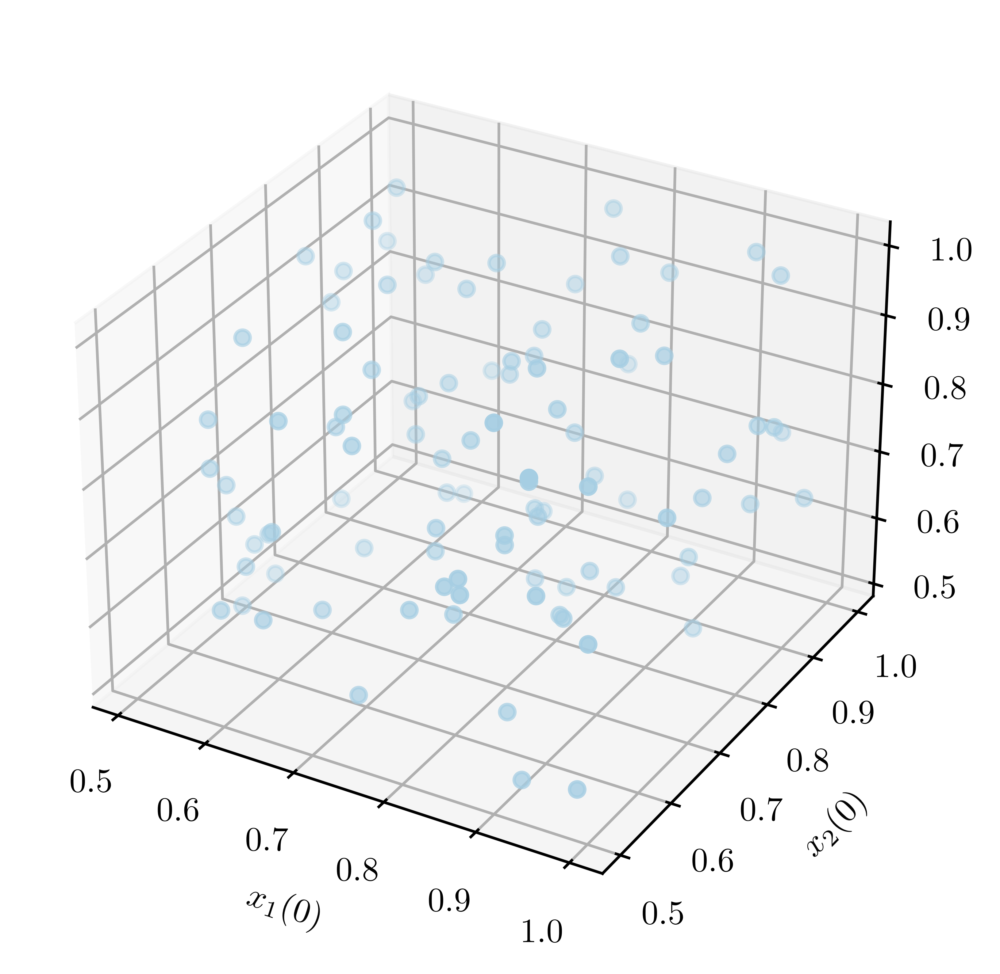

In [1067]:
# PLOT THE INITIAL CONDITIONS
# Convert to array: shape (n_traj, 3)
traj_ICs_array = np.array(traj_ICs)
# Plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(traj_ICs_array[:, 0], traj_ICs_array[:, 1], traj_ICs_array[:, 2]) 
ax.set_xlabel(r'$x_1(0)$')
ax.set_ylabel(r'$x_2(0)$')
ax.set_zlabel(r'$x_3(0)$')

plt.show()

In [1068]:
# inputs along trajectories (to be interpolated) - zeros interpolated
# The original time step is from 0 to 5  
traj_time = np.linspace(0, 10.0, 1001) #1000 time steps


# Control inputs of 0 
u_trajs = [np.reshape(0.0*traj_time, (-1,1)) for k in range(n_traj)]
#Check this out for a sin varying control
# u_trajs = [np.reshape(np.sin(traj_time), (-1,1)) for k in range(n_traj)]
# u_trajs = [np.ones((len(traj_time), 1)) for k in range(n_traj)]

#[0,1] is repeated twice 
FOM_x_trajs = [_ for _ in range(n_traj)]
FOM_y_trajs = [_ for _ in range(n_traj)]

In [1069]:
print(traj_ICs)
print(u_trajs[0].shape)

[array([0.77053774, 0.9991313 , 0.75671323]), array([0.54131453, 0.67950695, 0.62102098]), array([0.64701267, 0.50168483, 0.65732097]), array([0.86071695, 0.50515185, 0.77709969]), array([0.99899961, 0.94096856, 0.67875459]), array([0.8355046 , 0.69402371, 0.96216428]), array([0.98533847, 0.67571497, 0.81987612]), array([0.80020619, 0.87583671, 0.67860276]), array([0.58045994, 0.921486  , 0.86956419]), array([0.52356967, 0.94262992, 0.88722192]), array([0.8903755 , 0.89096893, 0.55299219]), array([0.76216432, 0.69652233, 0.83169491]), array([0.70215514, 0.74467599, 0.75183253]), array([0.97019014, 0.88034878, 0.69874168]), array([0.74688975, 0.84716596, 0.85366727]), array([0.98602197, 0.85950673, 0.83201703]), array([0.80592792, 0.91212182, 0.97892148]), array([0.75365935, 0.79041287, 0.8833004 ]), array([0.83925264, 0.62655574, 0.75711019]), array([0.92214157, 0.53898827, 0.77694464]), array([0.8242672 , 0.98131467, 0.92103288]), array([0.80228007, 0.81609185, 0.55204498]), array([0.

In [1070]:
for k in range(n_traj):
    # interpolate the input
    u_fun = sp.interpolate.interp1d(traj_time, u_trajs[k], axis=0)
    
    # initial condition
    x0 = traj_ICs[k]
    
    # simulate the FOM
    sol = sp.integrate.solve_ivp(lambda t,x: FOM(x, u_fun(t)), \
                                 # jac = lambda t,x: d_FOM(x, u_fun(t), np.eye(n_states)), \
                                 t_span = [traj_time[0], traj_time[-1]], \
                                 y0 = x0, \
                                 t_eval = traj_time, \
                                 method = solver_method, \
                                 atol=atol, rtol=rtol)
    
    #This overwrites the FOM_x_trajs and FOM_y_trajs and replaces it 
    FOM_x_trajs[k] = sol.y.T
    FOM_y_trajs[k] = FOM_obs(sol.y.T)

In [1071]:
#This keeps every 100th time point → downsampling trajectories
sample=100
t_data = traj_time[::sample]
y_traj_data = [FOM_y_trajs[k][::sample,:] for k in range(n_traj)]
x_traj_data = [FOM_x_trajs[k][::sample,:] for k in range(n_traj)]

In [1072]:
print(len(x_traj_data))
print(x_traj_data[0].shape)

100
(11, 3)


In [1073]:
# Insert the trajectory number to be plotted
k=0

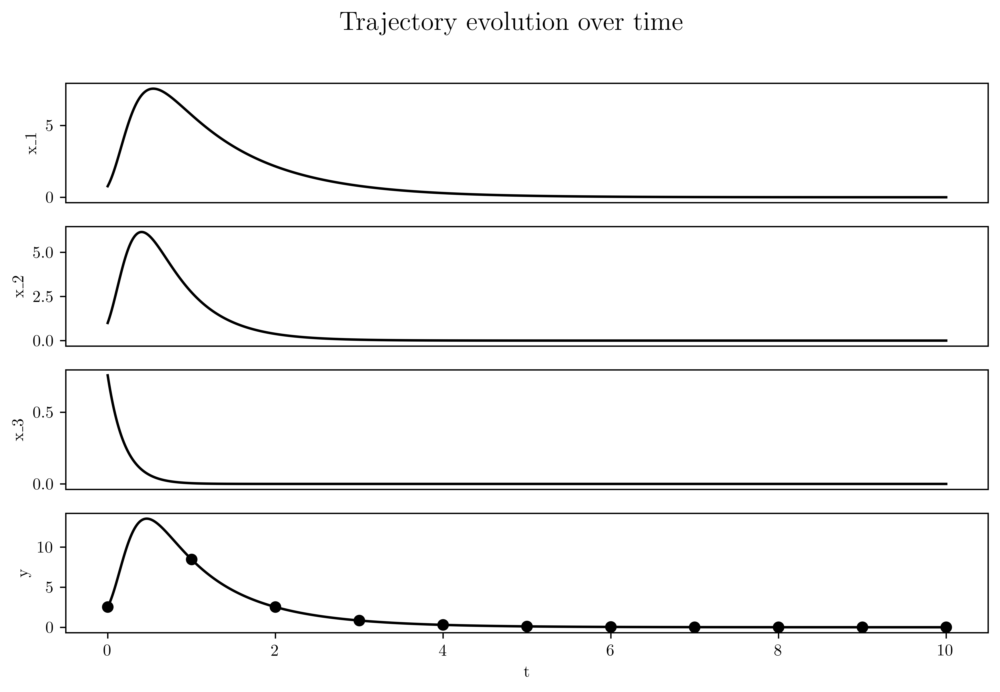

In [1074]:
fig = plt.figure(figsize=(10,6))
fig.suptitle('Trajectory evolution over time',fontsize=16)
ax = fig.add_subplot(4,1,1)
ax.plot(traj_time, FOM_x_trajs[k][:,0], 'k-')
ax.set_ylabel('x_1')
ax.set_xticks([])

ax = fig.add_subplot(4,1,2)
ax.plot(traj_time, FOM_x_trajs[k][:,1], 'k-')
ax.set_ylabel('x_2')
ax.set_xticks([])

ax = fig.add_subplot(4,1,3)
ax.plot(traj_time, FOM_x_trajs[k][:,2], 'k-')
ax.set_ylabel('x_3')
ax.set_xticks([])

ax = fig.add_subplot(4,1,4)
ax.plot(traj_time, FOM_y_trajs[k][:,0], 'k-')
ax.plot(t_data, y_traj_data[k][:,0], 'ko')
ax.set_ylabel('y')
ax.set_xlabel('t')

k = (k + 1) % n_traj
plt.show()

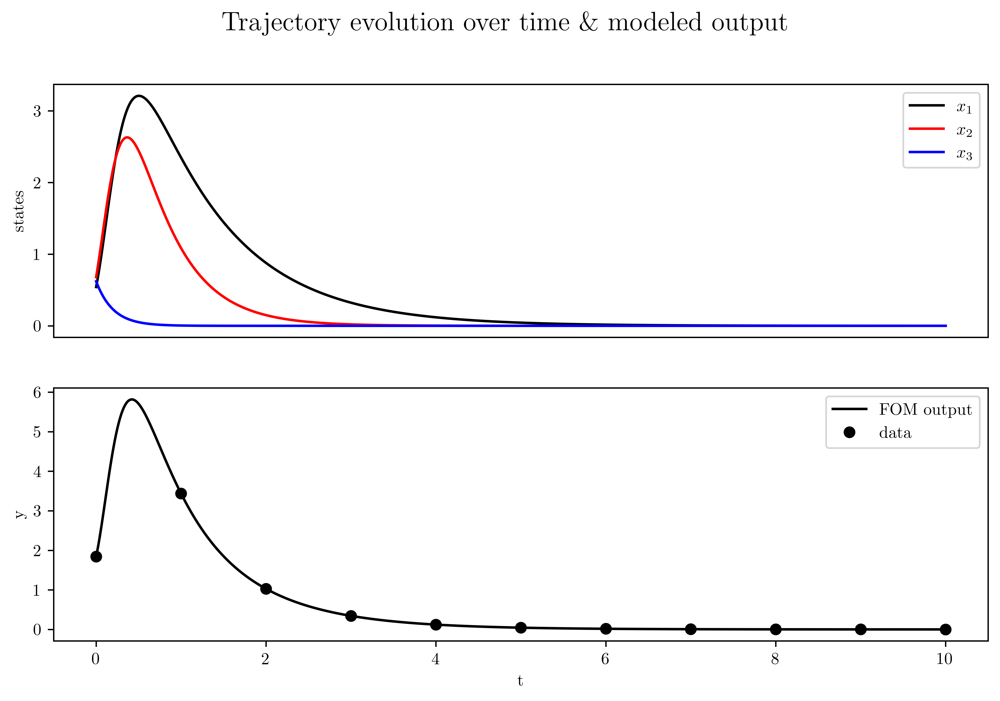

In [1075]:
fig = plt.figure(figsize=(10,6))
fig.suptitle('Trajectory evolution over time \& modeled output', fontsize=16)

# First plot: all states
ax = fig.add_subplot(2,1,1)
ax.plot(traj_time, FOM_x_trajs[k][:,0], 'k-', label=r'$x_1$')
ax.plot(traj_time, FOM_x_trajs[k][:,1], 'r-', label=r'$x_2$')
ax.plot(traj_time, FOM_x_trajs[k][:,2], 'b-', label=r'$x_3$')
ax.set_ylabel('states')
ax.set_xticks([])
ax.legend()

# Second plot: output
ax = fig.add_subplot(2,1,2)
ax.plot(traj_time, FOM_y_trajs[k][:,0], 'k-', label='FOM output')
ax.plot(t_data, y_traj_data[k][:,0], 'ko', label='data')
ax.set_ylabel('y')
ax.set_xlabel('t')
ax.legend()

k = (k + 1) % n_traj
plt.show()

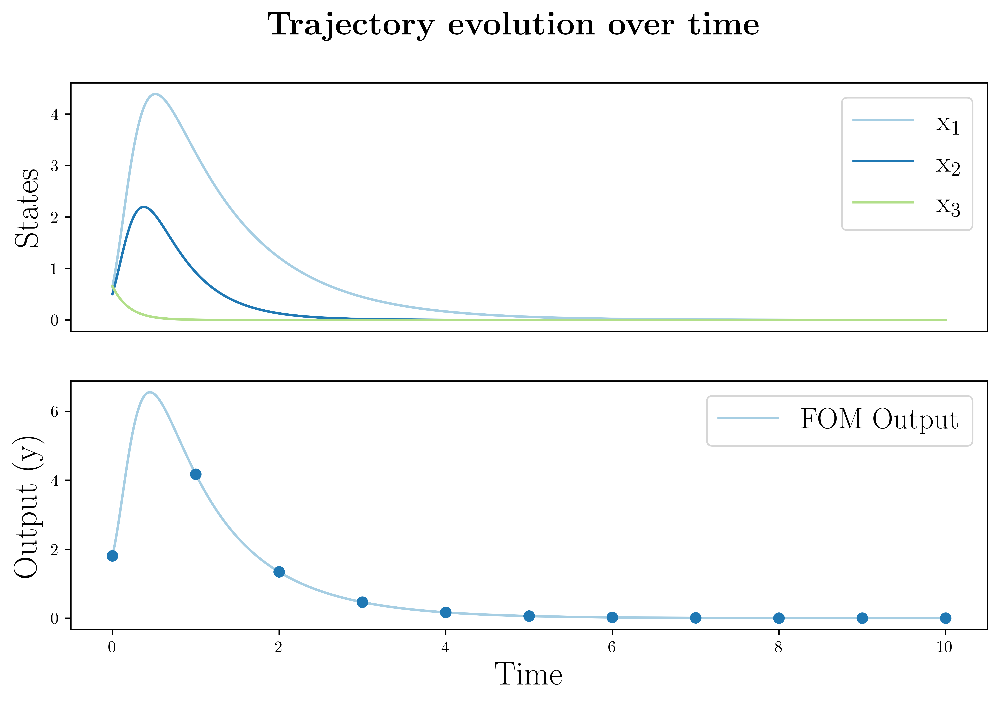

In [1076]:
fig = plt.figure(figsize=(10,6))
fig.suptitle(r'\textbf{Trajectory evolution over time}', fontsize=20)

# First plot: All states
ax = fig.add_subplot(2,1,1)
ax.plot(traj_time, FOM_x_trajs[k][:,0], label=r'$\mathrm{x}_1$')
ax.plot(traj_time, FOM_x_trajs[k][:,1], label=r'$\mathrm{x}_2$')
ax.plot(traj_time, FOM_x_trajs[k][:,2], label=r'$\mathrm{x}_3$')
ax.set_ylabel('States', fontsize=20)
ax.set_xticks([])
ax.legend(fontsize=18)

# Second plot: Output
ax = fig.add_subplot(2,1,2)
ax.plot(traj_time, FOM_y_trajs[k][:,0], label='FOM Output')
ax.plot(t_data, y_traj_data[k][:,0], 'o')
ax.set_ylabel('Output (y)', fontsize=20)
ax.set_xlabel('Time', fontsize=20)
ax.legend(fontsize=18)

k = (k + 1) % n_traj
plt.show()

In [1077]:
# Number of test trajectories extrapolation 
# This is what i will most likely use at the end
np.random.seed(24)
n_traj_test = 30

# Random initial conditions for the test
Initial_condition_test = [np.random.uniform(1, 1.5, size=n_states) for _ in range(n_traj_test)]

print(len(Initial_condition_test))

x0 = Initial_condition_test[:10]
print(x0)

30
[array([1.48000865, 1.34975602, 1.49993365]), array([1.11003365, 1.18052818, 1.3699205 ]), array([1.49822786, 1.15817349, 1.06827229]), array([1.19199001, 1.16025964, 1.18320738]), array([1.35482578, 1.45007122, 1.26705772]), array([1.12364688, 1.33590328, 1.28086455]), array([1.27127994, 1.4467238 , 1.42138977]), array([1.15300629, 1.31558489, 1.34011943]), array([1.48521378, 1.44678358, 1.47121293]), array([1.32111274, 1.30732382, 1.11384163])]


In [1078]:
# Number of test trajectories no extrapolation 
np.random.seed(24)
n_traj_test = 30

# Random initial conditions for the test
Initial_condition_test = [np.random.uniform(0.5, 1, size=n_states) for _ in range(n_traj_test)]

print(len(Initial_condition_test))

# I am showing 4 here cos I used to debug 
x0 = Initial_condition_test[4]
print(x0)

30
[0.85482578 0.95007122 0.76705772]


In [1079]:
print(atol)
print(rtol)

1e-09
1e-07


In [1080]:
# Gauss–Legendre nodes and weights for quadrature sampling of initial conditions in the space 0.5 to 1
def gauss_legendre_nodes_weights(N, a=0, b=1.0):
    """
    N-point Gauss–Legendre quadrature on [a,b].
    Returns nodes and weights w.
    """
    x, w = leggauss(N)               # Nodes/weights on [-1,1]
    nodes = 0.5*(b-a)*(x+1) + a      # Map nodes to [a,b]
    weights = 0.5*(b-a)*w            # Scale weights
    return nodes, weights

nodes_qs, weights_qs = gauss_legendre_nodes_weights(50, a=0.5 , b =1)


# Nonlinear Trajectory Optimization using Gauss–Legendre Quadrature and Barycentric Interpolation for the Non linear Case 
# Includes Jacobian in forward simulation and callback showing Cost/Gradient per iteration
# Generate Left Gauss-Radau nodes and weights 

def gauss_radau_left(N, a=-1.0, b=1.0, tol=1e-12):
    """
    Left Gauss–Radau quadrature on [a,b] including x = -1.
    Based on:
        roots of (P_{N-1}(x) + P_N(x)) = 0
        w_i = (1 - x_i) / [N * P_{N-1}(x_i)]^2
        w_1 = 2 / N^2
    """
    # Legendre polynomials
    Pn   = Legendre.basis(N)
    Pn_1 = Legendre.basis(N-1)

    # Internal nodes: roots of P_{N-1}(x) + P_N(x)
    poly = Pn_1 + Pn
    roots = np.sort(poly.roots())

    # Remove any root numerically equal to -1
    roots = roots[roots > -1 + tol]

    # Combine with exact endpoint -1
    x_nodes = np.concatenate(([-1.0], roots))

    # Compute weights
    w = np.zeros_like(x_nodes)
    w[0]  = 2.0 / (N**2)
    w[1:] = (1 - roots) / ((N * Pn_1(roots))**2)

    # Map from [-1,1] → [a,b]
    t_nodes = 0.5 * (b - a) * (x_nodes + 1) + a
    w *= 0.5 * (b - a)
    return t_nodes, w

# System setup 
n = A_FOM .shape[0]
m = B_FOM.shape[1]
p = C_FOM.shape[0]

Q = np.eye(p)
# Large R means control is expensive and the decay really slow 
R = 1e2 * np.eye(m)

# Time grid: Gauss–Legendre nodes and weights
t0, tf = 0.0, 10
N = 200
t, w = gauss_radau_left(N, a=t0, b=tf)

def pack_u(U):
    return U.reshape(-1)

def unpack_u(u_vec):
    return u_vec.reshape(N, m)

def make_u_fun(u_vec):
    U = unpack_u(u_vec)
    return BarycentricInterpolator(t, U, axis=0)

# Forward simulation (nonlinear FOM with Jacobian)
# No t_eval since it returns the values only at those node points  

def forward_trajectory(u_vec,x0):
    u_fun = make_u_fun(u_vec)

    def f(tq, x):
        return FOM(x, u_fun(tq))  # Nonlinear dynamics

    sol = solve_ivp(f,
                    (t0, tf),
                    x0,   
                    dense_output=True,          
                    method='RK45',          # Explicit solver
                    rtol=rtol,
                    atol=atol)
    return sol.sol  # returns object as a function x(t) and not N,n

# Cost functional
# Since the X is a function returned above the X passed in here should be evaluated at the quadrature nodes 
def total_cost(u_vec, X):
    U = unpack_u(u_vec)
    Y = (C_FOM @ X.T).T
    stage_y = np.einsum('ij,ij->i', Y @ Q, Y)
    stage_u = np.einsum('ij,ij->i', U @ R, U)
    J = np.dot(w, stage_y + stage_u)
    return J

# Gradient (Adjoint Method) 
def gradient(u_vec, X, return_adj=False):
    u_fun = make_u_fun(u_vec)

    def adj_rhs(tq, p):
        xq = X(tq)
        return - d_FOM_adj(xq, u_fun(tq), p) - 2 * d_FOM_obs_adj(xq, Q @ FOM_obs(xq))

    pT = np.zeros(n)
    sol = solve_ivp(lambda tq, p: adj_rhs(tq, p),
                    (tf, t0), pT, dense_output=True,
                    method='RK45', rtol=rtol, atol=atol)
    P = sol.sol(t).T #Retuns p(t) Evaluates the continous adjoints at the quadrature nodes

    U = unpack_u(u_vec)
    BtP = np.array([B_FOM.T @ P[i] for i in range(len(P))])
    Gi = (BtP + 2.0 * (U @ R)) * w[:, None]

    if return_adj:
        return Gi.reshape(-1), P
    else:
        return Gi.reshape(-1)
    
# Objective and Callbacks 
def objective_with_grad(u_vec,x0):
    X_fun = forward_trajectory(u_vec,x0)
    X = X_fun(t).T                  # Evaluate at nodes - X_fun returns n by N and transpose to get N by n 
    J = total_cost(u_vec, X)
    g = gradient(u_vec, X_fun)
    return J, g

def fun_only(u_vec,x0):
    return objective_with_grad(u_vec,x0)[0] # Returns the cost 

def jac_only(u_vec,x0):
    return objective_with_grad(u_vec,x0)[1] # Returns the gradient of the cost with respect to control parameters 

# Callback for logging iteration progress
iteration_data = []

def callback(u_vec,x0):
    J, g = objective_with_grad(u_vec,x0)
    grad_norm = np.linalg.norm(g)
    iteration_data.append((len(iteration_data), J, grad_norm))
    print(f"Iter {len(iteration_data):3d}: Cost = {J:.6f}, ||grad|| = {grad_norm:.3e}")

In [1081]:
def verify_adjoint_gradient(x0, N, m, t, forward_trajectory, gradient, total_cost, eps=1e-5):

    u_vec = np.random.randn(N * m)

    # Forward returns function and evaluate at quadrature nodes
    x_fun = forward_trajectory(u_vec, x0)
    X = x_fun(t).T

    # Adjoint gradient - pass function
    g_analytic = gradient(u_vec, x_fun)

    # Random direction
    v = np.random.randn(*u_vec.shape)
    v /= np.linalg.norm(v)

    adj_deriv = np.dot(g_analytic, v)

    # Cost at base point
    J0 = total_cost(u_vec, X)

    # Perturb control in the direction of v
    u_pert = u_vec + eps * v

    # Forward for perturbed control
    x_fun_pert = forward_trajectory(u_pert, x0)
    X_pert = x_fun_pert(t).T

    J1 = total_cost(u_pert, X_pert)

    # Finite difference check
    fd_deriv = (J1 - J0) / eps

    # Relative error
    rel_err = np.abs(adj_deriv - fd_deriv) / np.abs(fd_deriv)

    return rel_err, adj_deriv, fd_deriv

In [1082]:
rel_err, adj_deriv, fd_deriv= verify_adjoint_gradient(x0,N,m,t,forward_trajectory,gradient,total_cost,eps=1e-5)
print("\nAdjoint Gradient Verification")
print(f"Adjoint directional derivative : {adj_deriv:.6e}")
print(f"Finite diff directional deriv. : {fd_deriv:.6e}")
print(f"Ratio (adj/fd)                 : {adj_deriv/(fd_deriv + 1e-12):.6f}")
print(f"Relative error                 : {rel_err:.6e}")

# Use a smale relative error 
if rel_err < 1e-3:
        print("✅ Gradient check PASSED")
else:
        print("⚠️ Gradient check FAILED")


Adjoint Gradient Verification
Adjoint directional derivative : -7.201258e+00
Finite diff directional deriv. : -7.202045e+00
Ratio (adj/fd)                 : 0.999891
Relative error                 : 1.092609e-04
✅ Gradient check PASSED


In [1083]:
# eps_values = [1e-4, 1e-5, 1e-6, 1e-7, 1e-8]
# rel_errors = []
# for eps in eps_values:
#     print(f"Running epsilon value {eps}")
#     rel_err, _, _ = verify_adjoint_gradient(x0, N,m,t,forward_trajectory,gradient,total_cost,eps=eps)
#     rel_errors.append(rel_err)

In [1084]:
# plt.figure(figsize=(6,4))
# plt.semilogx(eps_values, rel_errors, 'o-', linewidth=2)
# plt.xlabel(r'Finite Difference Step Size ($\epsilon$)')
# plt.ylabel('Relative Error')
# plt.title('Adjoint Gradient Verification')
# plt.grid(False)
# plt.minorticks_off()
# plt.show()

In [1085]:
print(x0)

[0.85482578 0.95007122 0.76705772]


Iter   1: Cost = 92.818767, ||grad|| = 4.724e+01
Iter   2: Cost = 80.001835, ||grad|| = 4.626e+01
Iter   3: Cost = 79.777692, ||grad|| = 4.120e+01
Iter   4: Cost = 77.630102, ||grad|| = 3.936e+01
Iter   5: Cost = 73.646141, ||grad|| = 3.622e+01
Iter   6: Cost = 67.216390, ||grad|| = 3.029e+01
Iter   7: Cost = 59.600411, ||grad|| = 2.142e+01
Iter   8: Cost = 54.221305, ||grad|| = 1.389e+01
Iter   9: Cost = 51.483571, ||grad|| = 9.805e+00
Iter  10: Cost = 49.569018, ||grad|| = 6.974e+00
Iter  11: Cost = 48.683677, ||grad|| = 5.744e+00
Iter  12: Cost = 47.808687, ||grad|| = 3.883e+00
Iter  13: Cost = 47.485362, ||grad|| = 3.776e+00
Iter  14: Cost = 47.140585, ||grad|| = 2.535e+00
Iter  15: Cost = 47.065979, ||grad|| = 2.608e+00
Iter  16: Cost = 46.954008, ||grad|| = 2.008e+00
Iter  17: Cost = 46.844726, ||grad|| = 1.624e+00
Iter  18: Cost = 46.821111, ||grad|| = 1.342e+00
Iter  19: Cost = 46.787262, ||grad|| = 9.826e-01
Iter  20: Cost = 46.760859, ||grad|| = 8.463e-01
Iter  21: Cost = 46.

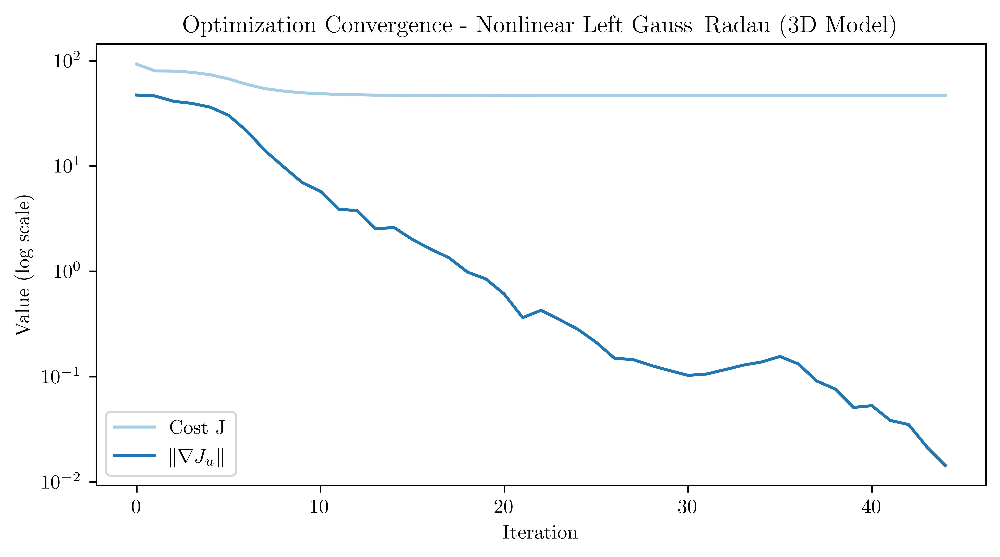

In [1086]:
# Optimization
U0 = 0 * np.ones((N, m))   # Initial guess (zeros)
u0 = pack_u(U0)

#Minimize cost function while passing the cost and gradient to BFGS
res = minimize(fun_only, u0, args=(x0,), jac=jac_only, method='BFGS',
               tol=1e-6,
               options=dict(maxiter=800, gtol=1e-12, disp=True),
               callback=lambda u: callback(u, x0))

# Check why optimization stopped
print("\n--- Optimizer Status ---")
print("Success:", res.success)
print("Message:", res.message)
print("Status:", res.status)
print("Iterations:", res.nit)
print("Function evaluations:", res.nfev)
print("Gradient evaluations:", res.njev)
print("Final gradient norm:", np.linalg.norm(res.jac))

#Results
u_star = unpack_u(res.x)
X_star_fun = forward_trajectory(res.x,x0)
X = X_star_fun(t).T                  # Evaluate at nodes - X_fun returns n by N and transpose to get N by n 
J_star = total_cost(res.x, X)
Grad_star, P_star = gradient(res.x, X_star_fun, return_adj=True)
print("\nOptimization complete.")
print("Final cost J* =", J_star)

# print("res.fun =", res.fun)
# print("Recomputed J* =", J_star)
# print("Difference =", J_star - res.fun)

# Plot convergence 
if iteration_data:
    iters, costs, grads = zip(*iteration_data)
    plt.figure(figsize=(8,4))
    plt.semilogy(iters, costs, label="Cost J")
    plt.semilogy(iters, grads, label=r"$\|\nabla J_u\|$")
    plt.xlabel("Iteration")
    plt.ylabel("Value (log scale)")
    plt.title("Optimization Convergence - Nonlinear Left Gauss–Radau (3D Model)")
    plt.legend()
    plt.minorticks_off()
    plt.grid(False)
    plt.show()

In [1087]:
# custom_colors = ["#2166ac", "#762a83", "#1b7837", "#b2182b"]
# Add "#a50f15" at the front if there is a FOM to compare
custom_colors = ["#a6cee3", "#1f78b4", "#b2df8a", "#33a02c"]
custom_colors = ["#a6cee3", "#1f78b4", "#b2df8a", "#33a02c", "#000000"]
# custom_colors = ["#a6cee3", "#1f78b4", "#b2df8a", "#33a02c", "#fb9a99"]
# custom_colors = ["#0072B2", "#009E73", "#CC79A7", "#E69F00"] # Okabe Ito 
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=custom_colors)

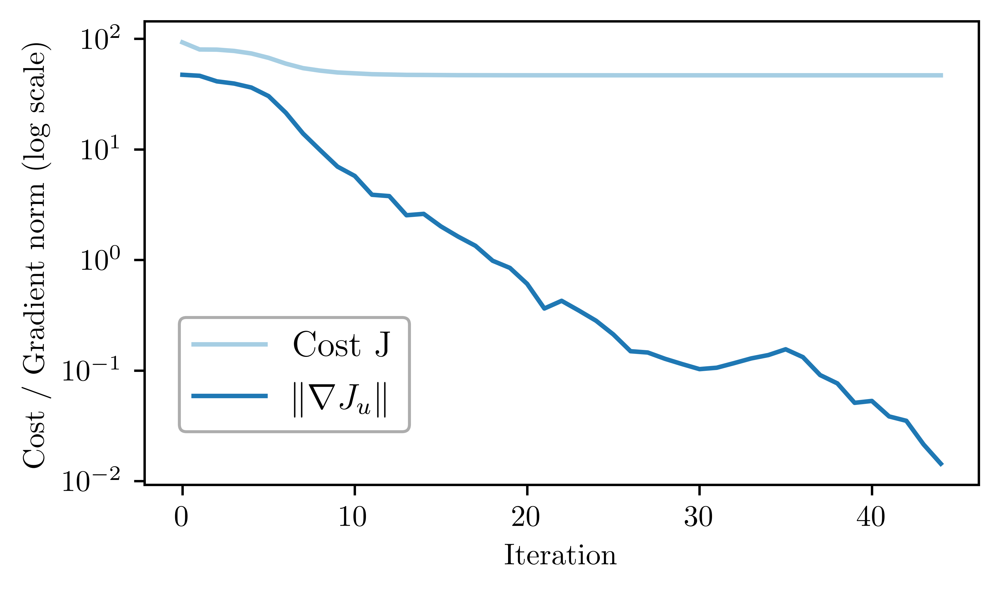

In [1088]:
# Plot convergence 
if iteration_data:
    iters, costs, grads = zip(*iteration_data)
    plt.figure(figsize=(5,2.8))
    plt.semilogy(iters, costs, label="Cost J")
    plt.semilogy(iters, grads, label=r"$\|\nabla J_u\|$")
    plt.xlabel("Iteration")
    plt.ylabel("Cost / Gradient norm (log scale)")
    # plt.title("Optimization Convergence - Nonlinear Left Gauss–Radau (3D Model)")
    
    # Place legend directly above the gray box
    plt.legend(
        loc='upper left',
        bbox_to_anchor=(0.02, 0.4),  # x,y in axes coordinates
        fontsize=12,
        frameon=True,
        edgecolor='0.6'
    )

    plt.minorticks_off()
    plt.grid(False)
    plt.show()

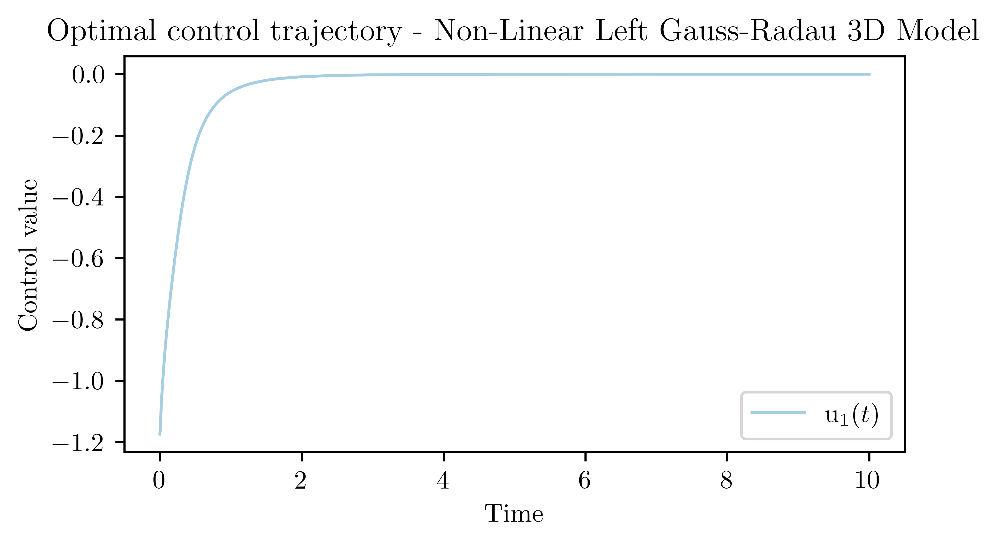

In [1089]:
plt.figure(figsize=(5,3), dpi=800)
for j in range(u_star.shape[1]):
    plt.plot(t, u_star[:, j], label = fr"$\mathrm{{u}}_{{{j+1}}}(t)$", linewidth=1.1)   
plt.xlabel("Time")
plt.ylabel("Control value")
plt.title("Optimal control trajectory - Non-Linear Left Gauss-Radau 3D Model")
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()

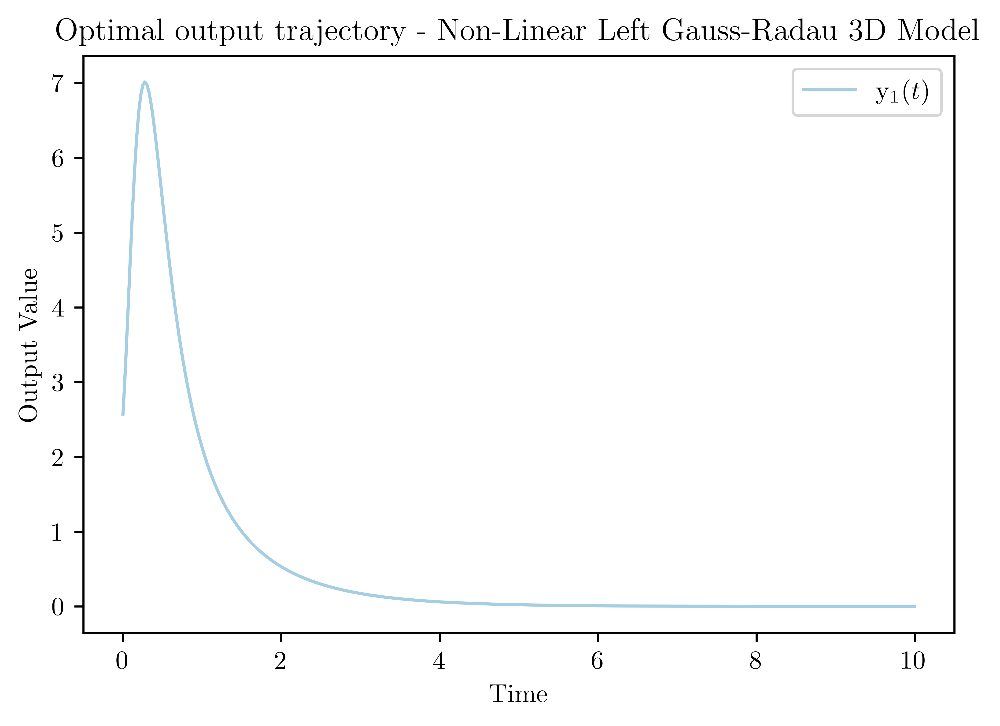

In [1090]:
# Compute outputs from Optimal states
Y_star = (C_FOM @ X.T).T  
plt.figure(figsize=(6,4), dpi=800)
for j in range(Y_star.shape[1]):    
    plt.plot(t, Y_star[:, j], label=fr"$\mathrm{{y}}_{{{j+1}}}(t)$", linewidth=1.2)    
plt.xlabel("Time")
plt.ylabel("Output Value")
plt.title("Optimal output trajectory - Non-Linear Left Gauss-Radau 3D Model")
plt.legend()
plt.grid(False)
plt.show()

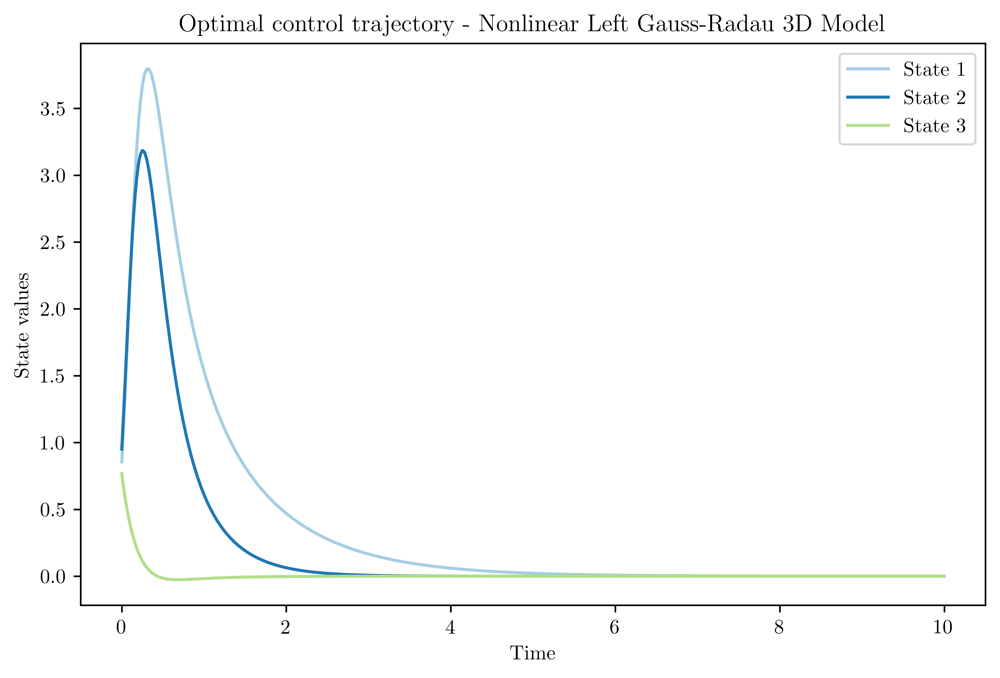

In [1091]:
plt.figure(figsize=(8,5), dpi=800)
for j in range(X.shape[1]):  
    plt.plot(t, X[:, j] ,label=f"State {j+1}")
plt.xlabel("Time")
plt.ylabel("State values")
plt.title("Optimal control trajectory - Nonlinear Left Gauss-Radau 3D Model")
plt.grid(False)
plt.legend()
plt.show()

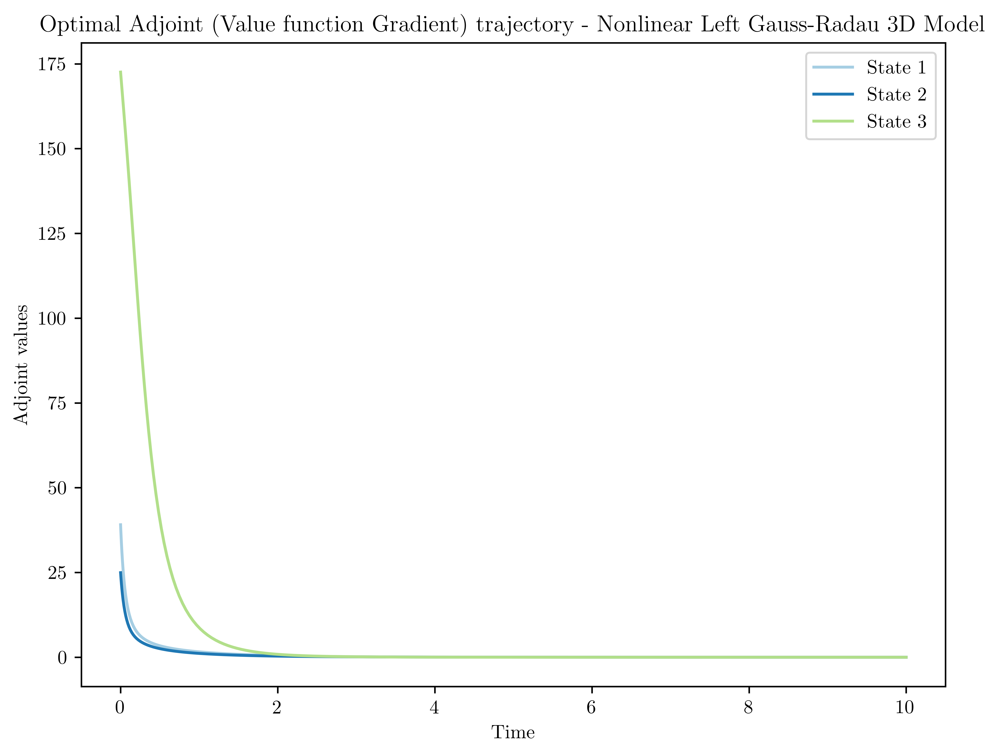

In [1092]:
plt.figure(figsize=(8,6), dpi=800)
for j in range(P_star.shape[1]):  
    plt.plot(t, P_star[:, j],label=f"State {j+1}")
plt.xlabel("Time")
plt.ylabel("Adjoint values")
plt.title("Optimal Adjoint (Value function Gradient) trajectory - Nonlinear Left Gauss-Radau 3D Model")
plt.grid(False)
plt.legend()
plt.show()

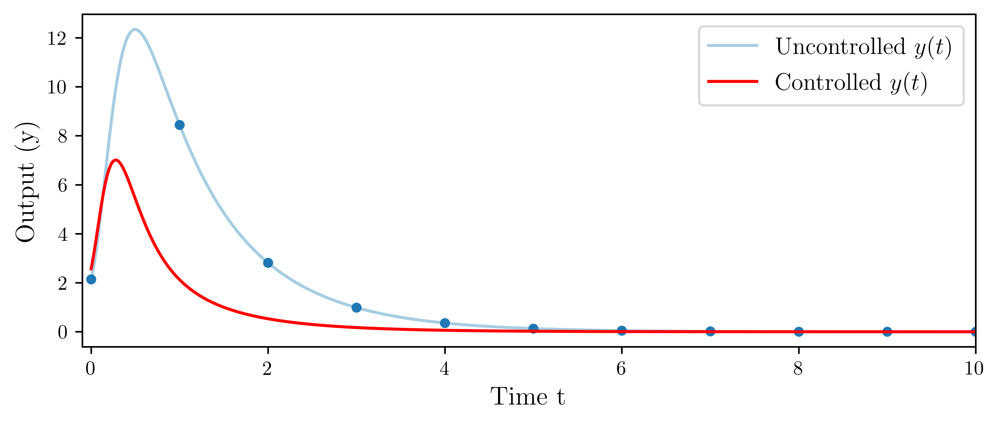

In [1093]:
# Controlled vs Uncontrolled system output for the nonlinear toy model 
Y_star = (C_FOM @ X.T).T  

plt.figure(figsize=(8,3), dpi=800)

plt.plot(traj_time, FOM_y_trajs[k][:,0], linewidth=1.5, label=r"$\mathrm{Uncontrolled}\ y(t)$")
plt.plot(t_data, y_traj_data[k][:, 0], "o", markersize=4)
plt.plot(t, Y_star[:, 0], linewidth=1.5, color='r', label=r"$\mathrm{Controlled}\ y(t)$")

# plt.xlabel("Time t", fontsize=13, fontweight="bold")
plt.xlabel("Time t", fontsize=13)
# plt.ylabel("Output (y)", fontsize=13, fontweight="bold")
plt.ylabel("Output (y)", fontsize=13)
# plt.title(r'$\mathbf{Controlled\ vs\ Uncontrolled\ Output}$', fontsize=12)
plt.legend(fontsize=12)
plt.grid(False)
plt.xlim(-0.1, 10)
plt.show()

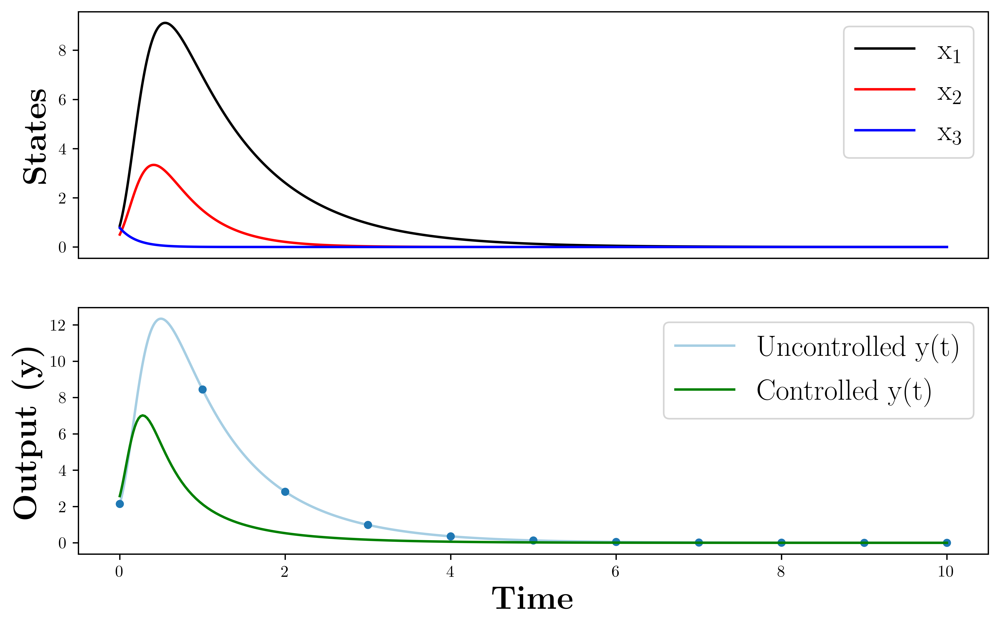

In [1094]:
fig = plt.figure(figsize=(10,6))
# fig.suptitle(r'\textbf{Trajectory evolution over time}', fontsize=20)

# First plot: All states
ax = fig.add_subplot(2,1,1)
ax.plot(traj_time, FOM_x_trajs[k][:,0], 'k-', label=r'$\mathrm{x}_1$')
ax.plot(traj_time, FOM_x_trajs[k][:,1], 'r-', label=r'$\mathrm{x}_2$')
ax.plot(traj_time, FOM_x_trajs[k][:,2], 'b-', label=r'$\mathrm{x}_3$')
ax.set_ylabel(r'\textbf{States}', fontsize=20)
ax.set_xticks([])
ax.legend(fontsize=18)

# Second plot: Output
ax = fig.add_subplot(2,1,2)
ax.plot(traj_time, FOM_y_trajs[k][:,0], linewidth=1.5, label=r"$\mathrm{Uncontrolled}\ \mathrm{y(t)}$")
ax.plot(t_data, y_traj_data[k][:,0], "o", markersize=4)
ax.plot(t, Y_star[:,0], linewidth=1.5, color='g', label=r"$\mathrm{Controlled}\ \mathrm{y(t)}$")
ax.set_ylabel(r'\textbf{Output ($\mathbf{y}$)}', fontsize=20)
ax.set_xlabel(r'\textbf{Time}', fontsize=20)
ax.legend(fontsize=18)

k = (k + 1) % n_traj
plt.show()

In [1095]:
# Solve Algebraic Riccati Equation for infinite-horizon LQR
Q_tilde = C_FOM.T @ Q @ C_FOM
P = solve_continuous_are(A_FOM, B_FOM, Q_tilde, R)
K = np.linalg.inv(R) @ B_FOM.T @ P
print(f"The shape of the solution to the ARE is {P.shape}")
def state_dynamics_with_riccati(t, x):
    u = -K @ x
    dx = FOM(x,u)
    return dx

sol_x_with_riccati = solve_ivp( state_dynamics_with_riccati, [t0, tf], x0, t_eval = t, method='RK45', rtol=1e-9, atol=1e-12)

x_vals_with_riccati = sol_x_with_riccati.y.T
u_vals_with_riccati = (-x_vals_with_riccati @ K.T) 
total_cost_with_riccati = total_cost (u_vals_with_riccati, x_vals_with_riccati)
print(total_cost_with_riccati)

The shape of the solution to the ARE is (3, 3)
124.30547723363414


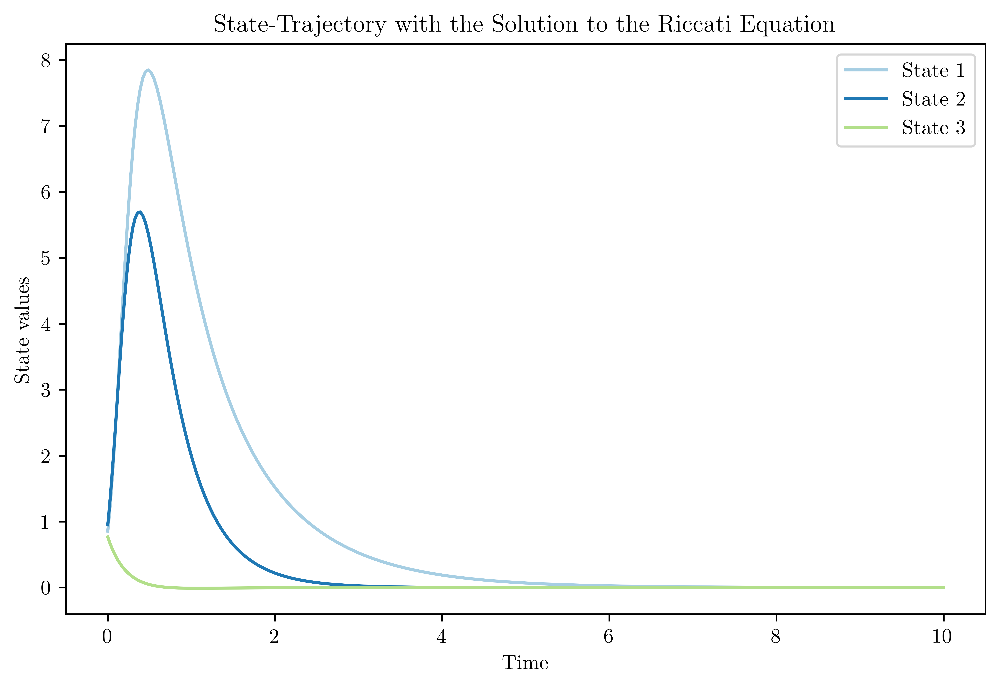

In [1096]:
plt.figure(figsize=(8,5), dpi=800)
for j in range(x_vals_with_riccati.shape[1]):  
    plt.plot(t, x_vals_with_riccati[:, j] ,label=f"State {j+1}")
plt.xlabel("Time")
plt.ylabel("State values")
plt.title("State-Trajectory with the Solution to the Riccati Equation")
plt.grid(False)
plt.legend()
plt.show()

In [1097]:
# import time

# # Number of trajectories 
# n_samples_MC = 50

# # Optimization for Multiple Random Samples
# dataset_toy = []   
# optimization_times = []
# np.random.seed(42) 

# # Start total timer
# total_start = time.perf_counter()

# for k in range(n_samples_MC):
#     # Clear the screen
#     clear_output(wait=True) 
    
#     if k>0 :
#         prev_cost = dataset_toy[k-1]['cost']
#         prev_x0 = dataset_toy[k-1]['x0']
#         prev_time = dataset_toy[k-1]['optimization_time']
#         print(f"Previous Sample {k}: J* = {prev_cost:.6f}, x0 = {prev_x0}, optimization time = {prev_time:.2f} seconds")

#     else:
#         print("Starting first sample...")

#     print(f"Sample {k+1}/{n_samples_MC} running...")
    
#     # Reset iteration tracker
#     iteration_data = []

#     # Pick a uniform starting state in the 3D domain
#     x0 = np.random.uniform(0.5, 1, size=n_states)

#     print(f"Initial condition x0 = {x0} for iteration {k}")
    
#     # Initial control guess
#     U0 = 0 * np.ones((N, m))   # Initial guess (zeros)
#     u0 = pack_u(U0)

#     # Start timer for this optimization
#     opt_start = time.perf_counter()

#     # Run optimization for this initial condition 
#     res = minimize(
#         fun_only, u0,
#         args=(x0,),
#         jac=jac_only,
#         method='BFGS',
#         tol=1e-6,
#         options=dict(maxiter=800, gtol=1e-8, disp=False),
#         callback=lambda u: callback(u, x0)
#     )

#     # End timer for this optimization
#     opt_time = time.perf_counter() - opt_start
#     optimization_times.append(opt_time)

#     # Compute final trajectories and adjoints
#     u_star = unpack_u(res.x)
#     X_star_fun = forward_trajectory(res.x,x0)
#     X_star = X_star_fun(t).T                  # Evaluate at nodes - X_fun returns n by N and transpose to get N by n 
#     J_star = total_cost(res.x, X_star)
#     Grad_star, P_star = gradient(res.x, X_star_fun, return_adj=True)

#     Y_star = (C_FOM @ X_star.T).T

#     # Stage cost (vectorized)
#     L = np.einsum('ij,ij->i', Y_star @ Q, Y_star) + \
#     np.einsum('ij,ij->i', u_star @ R, u_star)

#     # Value function (vectorized)
#     V = np.cumsum((w * L)[::-1])[::-1]

#     # Store structured dataset entry 
#     dataset_toy.append({
#         'x0': x0,
#         'state_history': X_star,
#         'control_history': u_star,
#         'gradient_history': P_star,
#         'cost': J_star,
#         'Value_function': V,
#         'optimization_time': opt_time,
#     })
    
#     print(f"\nSample {k+1}/{n_samples_MC} complete, J* = {J_star:.6f}")

# # Total time
# total_time = time.perf_counter() - total_start
        
# print(f"Optimization from {n_samples_MC} initial samples done and completed")
# print(f"Total optimization time = {total_time:.2f} seconds")
# print(f"Average time per optimization = {np.mean(optimization_times):.2f} seconds")

In [1098]:
# This was the previous way of getting test trajectories via monte carlo - No longer in use
# # Number of trajectories 
# n_samples_MC = 10

# # Optimization for Multiple Random Samples
# dataset_toy_test = []   
# np.random.seed(42) 

# for k in range(n_samples_MC):
#     # Clear the screen
#     clear_output(wait=True) 
    
#     if k>0 :
#         prev_cost = dataset_toy_test[k-1]['cost']
#         prev_idx = dataset_toy_test[k-1]['c']
#         print(f"Previous Sample {k}: J* = {prev_cost:.6f}, c = {prev_idx:.3f}")

#     else:
#         print("Starting first sample...")

#     print(f"Sample {k+1}/{n_samples_MC} running...")
    
#     # Reset iteration tracker
#     iteration_data = []

#     # Pick uniform starting state
#     c_MC = np.random.uniform(1.0, 1.5) 
#     x0 = np.ones(n_states) * c_MC

#     print(f"Initial condition scaling c = {c_MC:.3f} for iteration {k}")
    
#     # Initial control guess
#     U0 = 0 * np.ones((N, m))   # Initial guess (non-zero)
#     u0 = pack_u(U0)

#     # Run optimization for this initial condition 
#     res = minimize(
#         fun_only, u0,
#         args=(x0,),
#         jac=jac_only,
#         method='BFGS',
#         tol=1e-6,
#         options=dict(maxiter=800, gtol=1e-12, disp=False),
#         callback=lambda u: callback(u, x0)
#     )

#     # Compute final trajectories and adjoints
#     u_star = unpack_u(res.x)
#     X_star_fun = forward_trajectory(res.x,x0)
#     X_star = X_star_fun(t).T                  # Evaluate at nodes - X_fun returns n by N and transpose to get N by n 
#     J_star = total_cost(res.x, X_star)
#     Grad_star, P_star = gradient(res.x, X_star_fun, return_adj=True)

#     Y_star = (C_FOM @ X_star.T).T

#     # Stage cost (vectorized)
#     L = np.einsum('ij,ij->i', Y_star @ Q, Y_star) + \
#     np.einsum('ij,ij->i', u_star @ R, u_star)

#     # Value function (vectorized)
#     V = np.cumsum((w * L)[::-1])[::-1]

#     # Store structured dataset entry 
#     dataset_toy_test.append({
#         'c': c_MC,
#         'x0': x0,
#         'state_history': X_star,
#         'control_history': u_star,
#         'gradient_history': P_star,
#         'cost': J_star,
#         'Value_function': V,
#     })
#     print(f"\nSample {k+1}/{n_samples_MC} complete | c = {c_MC:.3f}, J* = {J_star:.6f}")
        
# print(f"Optimization from {n_samples_MC} initial samples done and completed")

# np.save("dataset_toy_test.npy", dataset_toy_test, allow_pickle=True)

In [1099]:
# import time

# # This is the right way to getting test trajectories 
# # Number of trajectories
# n_samples_test = len(Initial_condition_test)

# # Optimization for Multiple Samples
# dataset_toy_test = []
# optimization_times_test = []

# # Start total timer
# total_start = time.perf_counter()

# for k in range(n_samples_test):

#     clear_output(wait=True)

#     if k > 0:
#         prev_cost = dataset_toy_test[k-1]['cost']
#         prev_time = dataset_toy_test[k-1]['optimization_time']
#         print(f"Previous Sample {k}: J* = {prev_cost:.6f}, optimization time = {prev_time:.2f} seconds")
#     else:
#         print("Starting first sample...")

#     print(f"Sample {k+1}/{n_samples_test} running...")

#     # Reset iteration tracker
#     iteration_data = []

#     # Prescribed test initial condition
#     x0 = Initial_condition_test[k]

#     print(f"Initial condition for iteration {k}:")
#     print(x0)

#     # Initial control guess
#     U0 = 0 * np.ones((N, m))
#     u0 = pack_u(U0)

#     # Start timer for this optimization
#     opt_start = time.perf_counter()

#     # Run optimization for this initial condition
#     res = minimize(
#         fun_only, u0,
#         args=(x0,),
#         jac=jac_only,
#         method='BFGS',
#         tol=1e-6,
#         options=dict(maxiter=800, gtol=1e-8, disp=False),
#         callback=lambda u: callback(u, x0)
#     )

#     # End timer for this optimization
#     opt_time = time.perf_counter() - opt_start
#     optimization_times_test.append(opt_time)

#     # Compute final trajectories and adjoints
#     u_star = unpack_u(res.x)
#     X_star_fun = forward_trajectory(res.x, x0)
#     X_star = X_star_fun(t).T
#     J_star = total_cost(res.x, X_star)
#     Grad_star, P_star = gradient(res.x, X_star_fun, return_adj=True)

#     Y_star = (C_FOM @ X_star.T).T

#     # Stage cost
#     L = np.einsum('ij,ij->i', Y_star @ Q, Y_star) + \
#         np.einsum('ij,ij->i', u_star @ R, u_star)

#     # Value function
#     V = np.cumsum((w * L)[::-1])[::-1]

#     dataset_toy_test.append({
#         'x0': x0,
#         'state_history': X_star,
#         'control_history': u_star,
#         'gradient_history': P_star,
#         'cost': J_star,
#         'Value_function': V,
#         'optimization_time': opt_time,
#     })

#     print(f"\nSample {k+1}/{n_samples_test} complete | J* = {J_star:.6f}")
#     print(f"Optimization time = {opt_time:.2f} seconds")

# # Total time
# total_time = time.perf_counter() - total_start

# print(f"Optimization from {n_samples_test} initial conditions done and completed")
# print(f"Total optimization time = {total_time:.2f} seconds")
# print(f"Average time per optimization = {np.mean(optimization_times_test):.2f} seconds")

# # np.save("dataset_toy_test.npy", dataset_toy_test, allow_pickle=True)
# np.save("dataset_toy_test_no_extrapolation.npy", dataset_toy_test, allow_pickle=True)

Index of min test: 28
Index of max test: 0
Min cost test: 11.609934608574363
Max cost test: 105.5538830836548
Difference test: 93.94394847508043


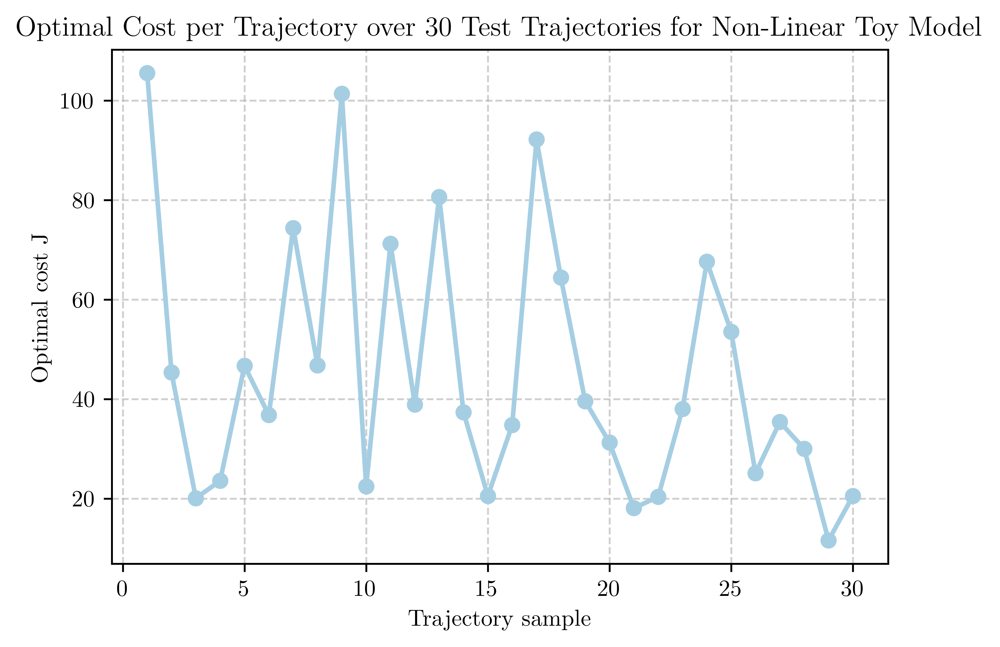

In [1100]:
# This is the dataset with extrapolation
# dataset_test = np.load("dataset_toy_test.npy", allow_pickle=True) 
dataset_test = np.load("dataset_toy_test_no_extrapolation.npy", allow_pickle=True)

J_all_test = [entry['cost'] for entry in dataset_test]

J_min_test = np.min(J_all_test)
J_max_test = np.max(J_all_test)
J_range_test = J_max_test - J_min_test

imin_test = np.argmin(J_all_test)
imax_test = np.argmax(J_all_test)

print("Index of min test:", imin_test)
print("Index of max test:", imax_test)
print("Min cost test:", J_min_test)
print("Max cost test:", J_max_test)
print("Difference test:", J_range_test)

samples_test = np.arange(1, len(J_all_test) + 1)

plt.figure(figsize=(6,4))
plt.plot(samples_test, J_all_test, 'o-', linewidth=2)
plt.xlabel("Trajectory sample")
plt.ylabel("Optimal cost J")
plt.title(f"Optimal Cost per Trajectory over {len(J_all_test)} Test Trajectories for Non-Linear Toy Model")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [1101]:
print(Initial_condition_test)
for i in range(10):
    print(dataset_test[i]['x0'])

[array([0.98000865, 0.84975602, 0.99993365]), array([0.61003365, 0.68052818, 0.8699205 ]), array([0.99822786, 0.65817349, 0.56827229]), array([0.69199001, 0.66025964, 0.68320738]), array([0.85482578, 0.95007122, 0.76705772]), array([0.62364688, 0.83590328, 0.78086455]), array([0.77127994, 0.9467238 , 0.92138977]), array([0.65300629, 0.81558489, 0.84011943]), array([0.98521378, 0.94678358, 0.97121293]), array([0.82111274, 0.80732382, 0.61384163]), array([0.74301593, 0.90360965, 0.92211008]), array([0.76734043, 0.87889902, 0.74983844]), array([0.92516395, 0.80984839, 0.93080709]), array([0.6158486 , 0.70110921, 0.81218753]), array([0.57151835, 0.56139924, 0.70841496]), array([0.77844149, 0.97070959, 0.70462951]), array([0.86837572, 0.99772534, 0.95833217]), array([0.50101164, 0.98566585, 0.94452409]), array([0.8497443 , 0.54876233, 0.78671452]), array([0.91001856, 0.78044553, 0.67538123]), array([0.77174988, 0.93979455, 0.55704828]), array([0.5157194 , 0.97640503, 0.64437174]), array([0.

In [1102]:
# np.save("dataset_toy.npy", dataset_toy, allow_pickle=True)
dataset=np.load("dataset_toy.npy", allow_pickle=True)

Index of min: 32
Index of max: 48
Min cost: 9.326946854438726
Max cost: 88.63887582354644
Difference: 79.31192896910771


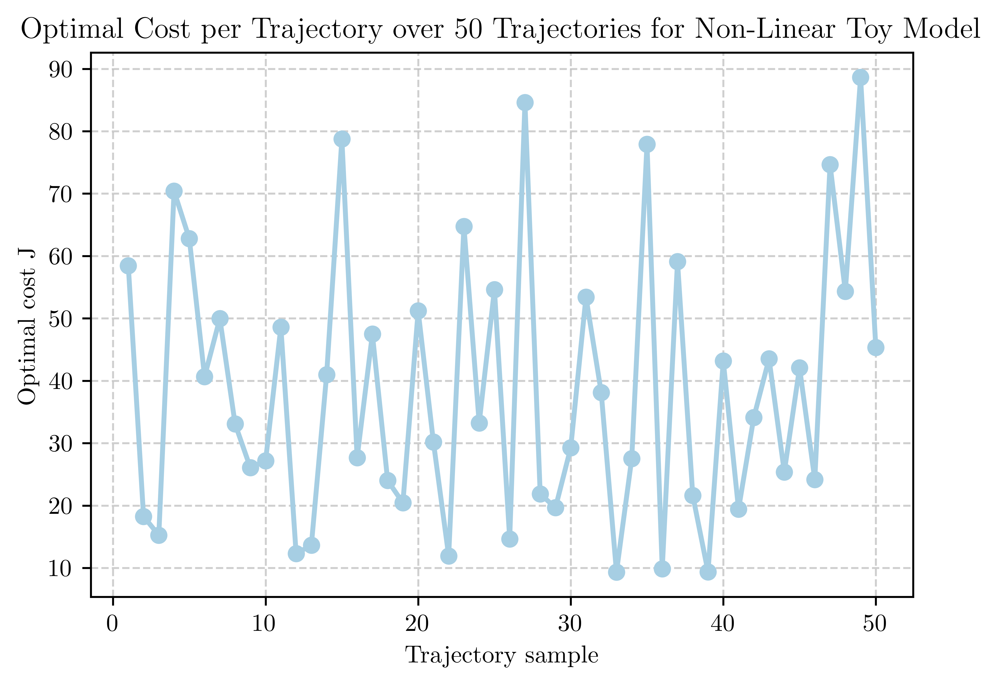

In [1103]:
J_all = [entry['cost'] for entry in dataset]

J_min = np.min(J_all)
J_max = np.max(J_all)
J_range = J_max - J_min
imin = np.argmin(J_all)
imax = np.argmax(J_all)

print("Index of min:", imin)
print("Index of max:", imax)
print("Min cost:", J_min)
print("Max cost:", J_max)
print("Difference:", J_range)


samples = np.arange(1, len(J_all) + 1)
plt.figure(figsize=(6,4))
plt.plot(samples, J_all, 'o-', linewidth=2)
plt.xlabel("Trajectory sample")
plt.ylabel("Optimal cost J")
plt.title(f"Optimal Cost per Trajectory over {len(J_all)} Trajectories for Non-Linear Toy Model")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [1104]:
# print(Initial_condition_test[:10])

In [1105]:
# for i in range(10):
#     print(dataset_test[i]['x0'])

In [1106]:
Wc = sp.linalg.solve_lyapunov(A_FOM, -np.dot(B_FOM, B_FOM.T))
Wo = sp.linalg.solve_lyapunov(A_FOM.T, -np.dot(C_FOM.T, C_FOM))

Uc, Sc, Vtc = np.linalg.svd(Wc, full_matrices=False)
Uo, So, Vto = np.linalg.svd(Wo, full_matrices=False)

# This factorization assumes Wc = Rc @ Rc.T and Wo = Ro @ Ro.T and takes an eigendecomposition factor UE^1/2 since Wc and Wo are square and PSD matrices
# W = UEU^T 

Rc = Uc @ np.diag(np.sqrt(Sc))
Ro = Uo @ np.diag(np.sqrt(So))

H_BT = Ro.T @ Rc

In [1107]:
# Check - Error should be very small 
print(np.linalg.norm(Wc - Rc @ Rc.T))
print(np.linalg.norm(Wo - Ro @ Ro.T))

2.5018537765542007e-16
2.5018537765542007e-16


In [1108]:
# SVD of H_BT
U_BT, S_BT, Vt_BT = np.linalg.svd(H_BT, full_matrices=False)
energy_bt = np.cumsum(S_BT) / np.sum(S_BT)
r_maxbt = np.searchsorted(energy_bt, 0.99) + 1
print("Chosen r (99% energy) for balanced truncation on A operator:", r_maxbt)

Chosen r (99% energy) for balanced truncation on A operator: 2


In [1109]:
# Truncation for unstable linear system
def compute_bt_basis(X, Y, U_BT, S_BT, Vt_BT, r):

    Ur = U_BT[:, :r]
    Sr = S_BT[:r]
    Vr = Vt_BT.T[:, :r]

    # Balanced Primal & adjoint modes using SVD of Y.T @ X for Unstable A matrix 
    Phi = X @ Vr @ np.diag(1/np.sqrt(Sr))
    Psi = Y @ Ur @ np.diag(1/np.sqrt(Sr))
    
    return Phi, Psi

In [1110]:
# MONTE CARLO 
# Stack gradients from dictionary
G_full = np.vstack([entry['gradient_history'] for entry in dataset])
X_full = np.vstack([entry['state_history'] for entry in dataset])

# Build full weights automatically
n_traj = len(dataset)
w_full = np.tile(w.reshape(-1,1), (n_traj, 1))

print("G_full:", G_full.shape)
print("w_full:", w_full.shape)

# Weighted gradients
G_full = G_full * np.sqrt(w_full)
X_full = X_full * np.sqrt(w_full)
 
# This gives the eigenvalues for comparison with Quadrature sampling 
G_full /= np.sqrt(n_traj)
X_full /= np.sqrt(n_traj)

# Interval scaling
G_full *= np.sqrt(0.5)
X_full *= np.sqrt(0.5)

print('G_tilde:', G_full.shape)
print("X_tilde:", X_full.shape)

G_full: (10000, 3)
w_full: (10000, 1)
G_tilde: (10000, 3)
X_tilde: (10000, 3)


In [1111]:
# Monte Carlo Sampling 
# SVD of G and X
Ug, Sg, Vtg = np.linalg.svd(G_full, full_matrices=False)
Vg = Vtg.T

Ux, Sx, Vtx = np.linalg.svd(X_full, full_matrices=False)
Vx = Vtx.T

# Factor of Wx = X^T X and Wg = G^T G
Rx = np.diag(Sx) @ Vx.T    # (n, n)
Rg = np.diag(Sg) @ Vg.T    # (n, n)

# Balanced Hankel product
H = Rg @ Rx.T    # (n, n)

# SVD of H
U_basoc, S_basoc, Vt_basoc = np.linalg.svd(H)

energy = np.cumsum(S_basoc) / np.sum(S_basoc)
energy = np.cumsum(S_basoc) / np.sum(S_basoc)
r_basoc_max = np.searchsorted(energy, 0.99) + 1
print("Chosen r (99% energy):", r_basoc_max)

Chosen r (99% energy): 2


[0.89197071 0.99854087 1.        ]


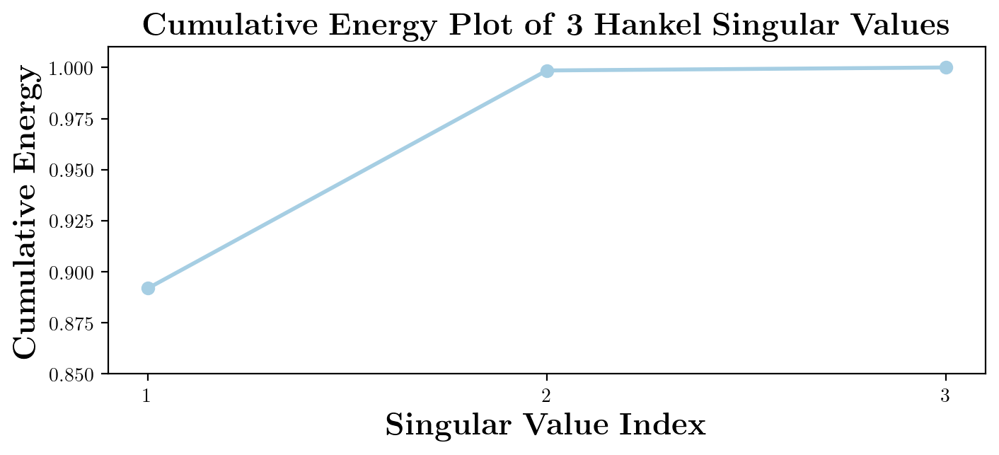

In [1112]:
# First K eigenvalues
K_evals_bal=3
evals_k = S_basoc[:K_evals_bal]
cum_energy = np.cumsum(evals_k) / np.sum(S_basoc)
print(cum_energy)
plt.figure(figsize=(8,3), dpi=200)
plt.plot(np.arange(1, K_evals_bal+1), cum_energy, 'o-', linewidth=2)   
plt.xlabel("Singular Value index")
plt.xlabel(r"$\mathbf{Singular\ Value\ Index}$", fontsize=16)
plt.ylabel("Cumulative energy")
plt.ylabel(r"$\mathbf{Cumulative\ Energy}$", fontsize=16)
# plt.xlabel(r"\textbf{Singular Value Index}")
# plt.ylabel(r"\textbf{Cumulative Energy}")
plt.title(f"Cumulative Energy Plot of {K_evals_bal} Hankel Singular Values")
plt.title(rf"$\mathbf{{Cumulative\ Energy\ Plot\ of\ {K_evals_bal}\ Hankel\ Singular\ Values}}$",fontsize=16)
plt.grid(True, linestyle="--", alpha=0.6)
plt.ylim(0.85, 1.01)
plt.xticks([1, 2, 3]) 
plt.grid(False)
plt.show()

[0.9859235  0.99999736 1.        ]


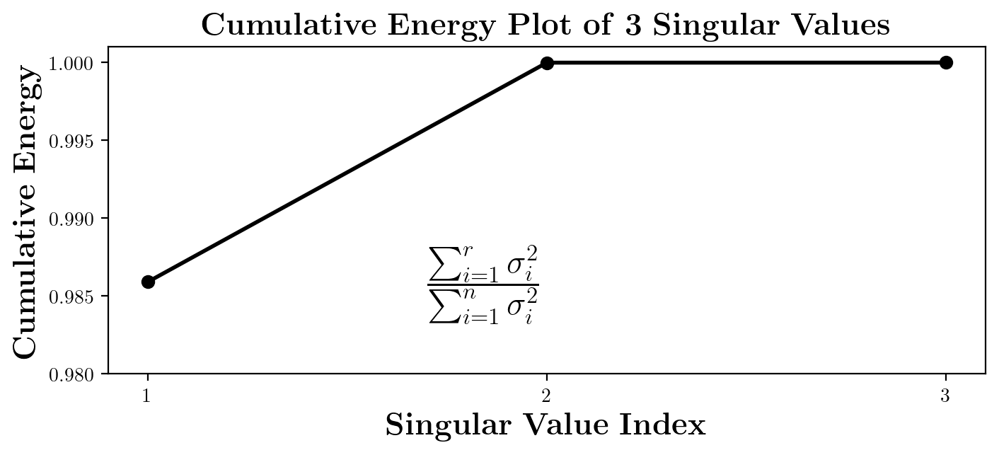

In [1113]:
# First K eigenvalues
K_evals_bal=3
evals_k = S_basoc[:K_evals_bal]
cum_energy = np.cumsum(evals_k**2) / np.sum(S_basoc**2)
print(cum_energy)
plt.figure(figsize=(8,3), dpi=200)
plt.plot(np.arange(1, K_evals_bal+1), cum_energy, 'o-', linewidth=2, color='black')   
plt.xlabel("Singular Value index")
plt.xlabel(r"$\mathbf{Singular\ Value\ Index}$", fontsize=16)
plt.ylabel("Cumulative energy")
plt.ylabel(r"$\mathbf{Cumulative\ Energy}$", fontsize=16)
# plt.xlabel(r"\textbf{Singular Value Index}")
# plt.ylabel(r"\textbf{Cumulative Energy}")
plt.title(f"Cumulative Energy Plot of {K_evals_bal} Hankel Singular Values")
plt.title(rf"$\mathbf{{Cumulative\ Energy\ Plot\ of\ {K_evals_bal}\  Singular\ Values}}$",fontsize=16)
plt.grid(True, linestyle="--", alpha=0.6)
plt.ylim(0.98, 1.001)
plt.xticks([1, 2, 3]) 
plt.grid(False)
plt.text(
    1.7, 0.985,
    r"$\frac{\sum_{i=1}^{r}\sigma_i^2}{\sum_{i=1}^{n}\sigma_i^2}$",
    fontsize=24
)
plt.show()

In [1114]:
K_evals_bal = 3
evals_k = S_basoc[:K_evals_bal]
cum_energy = np.cumsum(evals_k**2) / np.sum(S_basoc**2)
print(cum_energy)

[0.9859235  0.99999736 1.        ]


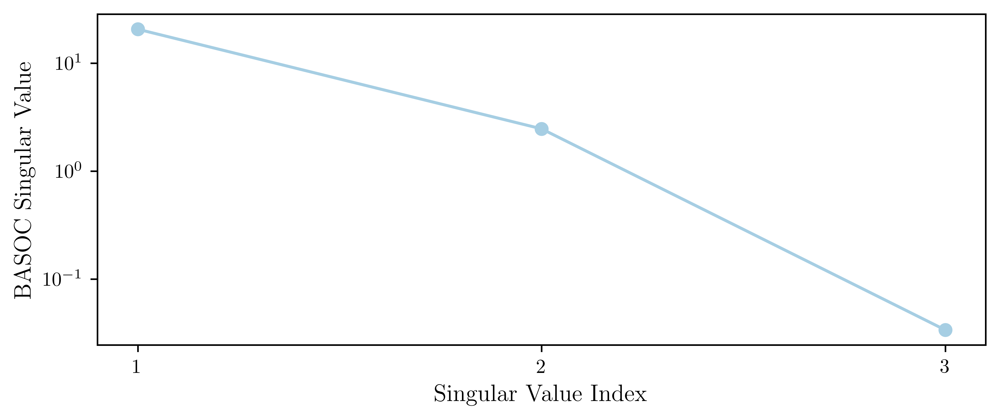

In [1115]:
plt.figure(figsize=(8,3))
plt.plot(np.arange(1, K_evals_bal+1), evals_k, 'o-')
plt.yscale('log')
plt.xlabel("Singular Value Index",fontsize=12)
plt.ylabel("BASOC Singular Value", fontsize=12)
# plt.title("Decay of BASOC Hankel Singular Values for 3 Singular Values 3D Model")
plt.minorticks_off()
plt.xticks([1, 2, 3])
plt.show()

In [1116]:
# Truncation for basoc basis   
def compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r):

    U_r = U_basoc[:, :r]
    S_r = S_basoc[:r]
    V_r = Vt_basoc.T[:, :r]

    # Balanced Primal & adjoint modes from Monte Carlo Sampling for basoc 
    Phi_basoc = Rx.T @ V_r @ np.diag(1/np.sqrt(S_r))
    Psi_basoc = Rg.T @ U_r @ np.diag(1/np.sqrt(S_r))
    
    return Phi_basoc, Psi_basoc

In [1117]:
# POD Optimal state trajectories 

Ux, Sx, Vtx = np.linalg.svd(X_full, full_matrices=False)
energy_x = np.cumsum(Sx) / np.sum(Sx)

# Rank selection (99% energy)
r_podmax = np.searchsorted(energy_x, 0.99) + 1
print(f"Optimal State POD rank (99% energy): {r_podmax}")

Optimal State POD rank (99% energy): 3


In [1118]:
print("First POD mode:")
print(Vtx.T[:, 0])

print("Second POD mode:")
print(Vtx.T[:, 1])

print("Third POD mode:")
print(Vtx.T[:, 2])

First POD mode:
[-0.86737875 -0.49722942 -0.02042091]
Second POD mode:
[-0.49583276  0.8599837   0.12073905]
Third POD mode:
[-0.04247335  0.11485185 -0.99247422]


In [1119]:
#Truncation for POD on optimal state trajectories 
def Pod_State_basis(Vtx, r):
    return Vtx[:r].T

In [1120]:
def Full_State_basis(n):
    return np.eye(n)

In [1121]:
#POD Optimal Adjoint trajectories 

Ug, Sg, Vtg = np.linalg.svd(G_full, full_matrices=False)

energy_g = np.cumsum(Sg) / np.sum(Sg)

# Rank selection (99% energy)
r_g = np.searchsorted(energy_g, 0.99) + 1
print(f"Optimal Adjoint POD rank (99% energy): {r_g}")

Optimal Adjoint POD rank (99% energy): 2


In [1122]:
# Truncation for POD on optimal Adjoint trajectories 
def Pod_Adjoint_basis(Vtg, r):
    return Vtg[:r].T

In [1123]:
# # LOAD DATA-SET FROM QUADRATURE SAMPLING

# # np.save("dataset_toy_qs.npy", dataset_toy_qs, allow_pickle=True)
# dataset_qs = np.load("dataset_toy_qs.npy", allow_pickle=True)

# J_all = [entry['cost'] for entry in dataset_qs]

# J_min = np.min(J_all)
# J_max = np.max(J_all)
# J_range = J_max - J_min
# imin = np.argmin(J_all)
# imax = np.argmax(J_all)

# print("Index of min:", imin)
# print("Index of max:", imax)
# print("Min cost:", J_min)
# print("Max cost:", J_max)
# print("Difference:", J_range)


# samples = np.arange(1, len(J_all) + 1)
# plt.figure(figsize=(6,4))
# plt.plot(samples, J_all, 'o-', linewidth=2)
# plt.xlabel("Trajectory sample")
# plt.ylabel("Optimal cost J")
# plt.title(f"Optimal Cost per Trajectory for {len(J_all)} Samples - Non-Linear Toy Model QS")
# plt.grid(True, linestyle="--", alpha=0.6)
# plt.show()

In [1124]:
# # Stack gradients from dictionary
# G_full_qs = np.vstack([entry['gradient_history'] for entry in dataset_qs])
# X_full_qs = np.vstack([entry['state_history'] for entry in dataset_qs])

# # Build full weights automatically
# # The weights here are left Gauss Radau weights for the integral 
# n_traj = len(dataset_qs)
# w_full = np.tile(w.reshape(-1,1), (n_traj, 1))

# print("G_full_qs:", G_full_qs.shape)
# print("w_full_qs:", w_full.shape)

# # Weighted gradients
# # APPLIES WEIGHTS IN TIME 
# G_full_qs = G_full_qs * np.sqrt(w_full)
# X_full_qs = X_full_qs * np.sqrt(w_full)

# # This repeats each of the 50 Gauss-legendre quadrature nodes 200 times 
# w_qs_full = np.repeat(weights_qs, len(w))  # Repeat per time samples
# w_qs_full = w_qs_full.reshape(-1,1)

# # APPLIES WEIGHTS IN SAMPLE SPACE
# G_full_qs = G_full_qs * np.sqrt(w_qs_full)
# X_full_qs = X_full_qs * np.sqrt(w_qs_full)

# print('G_tilde_full_qs:', G_full_qs.shape)
# print('X_tilde_full_qs:', X_full_qs.shape)

# # SVD of G and X (Quadrature Sampling)
# Ug_qs, Sg_qs, Vtg_qs = np.linalg.svd(G_full_qs, full_matrices=False)
# Vg_qs = Vtg_qs.T

# Ux_qs, Sx_qs, Vtx_qs = np.linalg.svd(X_full_qs, full_matrices=False)
# Vx_qs = Vtx_qs.T

# # Factors of Wx = X^T X and Wg = G^T G (QS version)
# Rx_qs = np.diag(Sx_qs) @ Vx_qs.T
# Rg_qs = np.diag(Sg_qs) @ Vg_qs.T

# # Balanced Hankel product (QS)
# H_qs = Rg_qs @ Rx_qs.T

# # SVD of H (QS)
# U_qs, S_qs, Vt_qs = np.linalg.svd(H_qs)

# energy_qs = np.cumsum(S_qs) / np.sum(S_qs)
# r_qs = np.searchsorted(energy_qs, 0.99) + 1
# print("Chosen r for quadrature sampling (99% energy):", r_qs)

In [1125]:
# # Truncation for basoc-qs basis 
# def compute_basoc_basis_qs(Rx_qs, Rg_qs, U_qs, S_qs, Vt_qs, r):

#     U_r_qs = U_qs[:, :r]
#     S_r_qs = S_qs[:r]
#     V_r_qs = Vt_qs.T[:, :r]

#     # Balanced Primal & Adjoint modes (QS)
#     Phi_bal_qs = Rx_qs.T @ V_r_qs @ np.diag(1/np.sqrt(S_r_qs))
#     Psi_bal_qs = Rg_qs.T @ U_r_qs @ np.diag(1/np.sqrt(S_r_qs))
    
#     return Phi_bal_qs, Psi_bal_qs

In [1126]:
# # First K eigenvalues
# num_evals= len(S_qs)
# evals_qs = S_qs[:num_evals]
# cum_energy_qs = np.cumsum(evals_qs) / np.sum(S_qs)
# plt.figure(figsize=(8,3), dpi=800)
# plt.plot(np.arange(1, num_evals+1), cum_energy_qs, 'o-', linewidth=2)   
# plt.xlabel("Singular Value index")
# plt.ylabel("Cumulative energy")
# plt.title(f"Cumulative Energy Plot of {num_evals} Hankel Singular Values with Balancing QS")
# plt.grid(True, linestyle="--", alpha=0.6)
# plt.ylim(0.85, 1.008)
# plt.grid(False)
# plt.show()

In [1127]:
# print("Cumulative energy captured by BASOC-QS modes:")
# print(cum_energy_qs)

# print("Cumulative energy captured by BASOC-MC modes:")
# print(cum_energy)

# print("Singular values from BASOC-QS decomposition:")
# print(S_qs)

# print("Singular values from BASOC-MC decomposition:")
# print(S_basoc)

In [1128]:
# Truncation
r = 2

In [1129]:
# Phi_bal_qs, Psi_bal_qs = compute_basoc_basis_qs(Rx_qs, Rg_qs, U_qs, S_qs, Vt_qs, r)
# print("Φ shape:", Phi_bal_qs.shape)
# print("Ψ shape:", Psi_bal_qs.shape)

In [1130]:
Phi_basoc, Psi_basoc = compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r)
print("Φ shape:", Phi_basoc.shape)
print("Ψ shape:", Psi_basoc.shape)

Φ shape: (3, 2)
Ψ shape: (3, 2)


In [1131]:
Phi_BT, Psi_BT = compute_bt_basis(Rc, Ro, U_BT, S_BT, Vt_BT, r)
print("Φ shape for BT:", Phi_BT.shape)
print("Ψ shape for BT:", Psi_BT.shape)

Φ shape for BT: (3, 2)
Ψ shape for BT: (3, 2)


In [1132]:
Phi_POD = Pod_State_basis(Vtx, r)
print("Φ shape for POD State:", Phi_POD.shape)

Φ shape for POD State: (3, 2)


In [1133]:
Phi_POD_Adjoint = Pod_Adjoint_basis(Vtg, r)
print("Φ shape for POD Adjoint:", Phi_POD_Adjoint.shape)

Φ shape for POD Adjoint: (3, 2)


In [1134]:
Phi_full_state = Full_State_basis(r)
print("Φ shape for full state:", Phi_full_state.shape)

Φ shape for full state: (2, 2)


In [1135]:
# # This code is for comparing subspace angles
# from scipy.linalg import subspace_angles
# Phi_POD_adjoint_angle = Pod_Adjoint_basis(Vtg,r)
# Phi_basoc_angle, Psi_basoc_angle = compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r)

# # Principal angles between the POD-adjoint and BASOC trial subspaces
# angles_rad = subspace_angles(Phi_POD_adjoint_angle, Phi_basoc_angle)

# angles_deg = np.degrees(angles_rad)

# print("Subspace angles in radians:")
# print(angles_rad)

# print("\nSubspace angles in degrees:")
# print(angles_deg)


In [1136]:
# BT Unstable and basoc have both Phi and Psi - Petrov Galerkin basis , POD_State and POD-Adjoint have only Phi-basis hence Galerkin projection
# names = ["BT", "POD State", "POD Adjoint", "Basoc" , "Basoc-qs", "Full_State"]
# names = ["BT", "POD State", "POD Adjoint", "Basoc", "Full_State"]
names = ["BT", "POD State", "POD Adjoint", "Basoc"]
# names = ["BT", "POD State", "POD Adjoint", "Basoc" , "Basoc-qs"]
basis_name = names[3]
Phi_basis = Phi_basoc
Psi_basis = Psi_basoc

In [1137]:
print(f"Φ shape for {basis_name}:", Phi_basis.shape)
print(f"Ψ shape for {basis_name}:", Psi_basis.shape)

# Check biorthogonality
M = Psi_basis.T @ Phi_basis
print(f"||Ψᵀ Φ − I|| for {basis_name}", np.linalg.norm(M - np.eye(r)))

Φ shape for Basoc: (3, 2)
Ψ shape for Basoc: (3, 2)
||Ψᵀ Φ − I|| for Basoc 3.026885905225296e-16


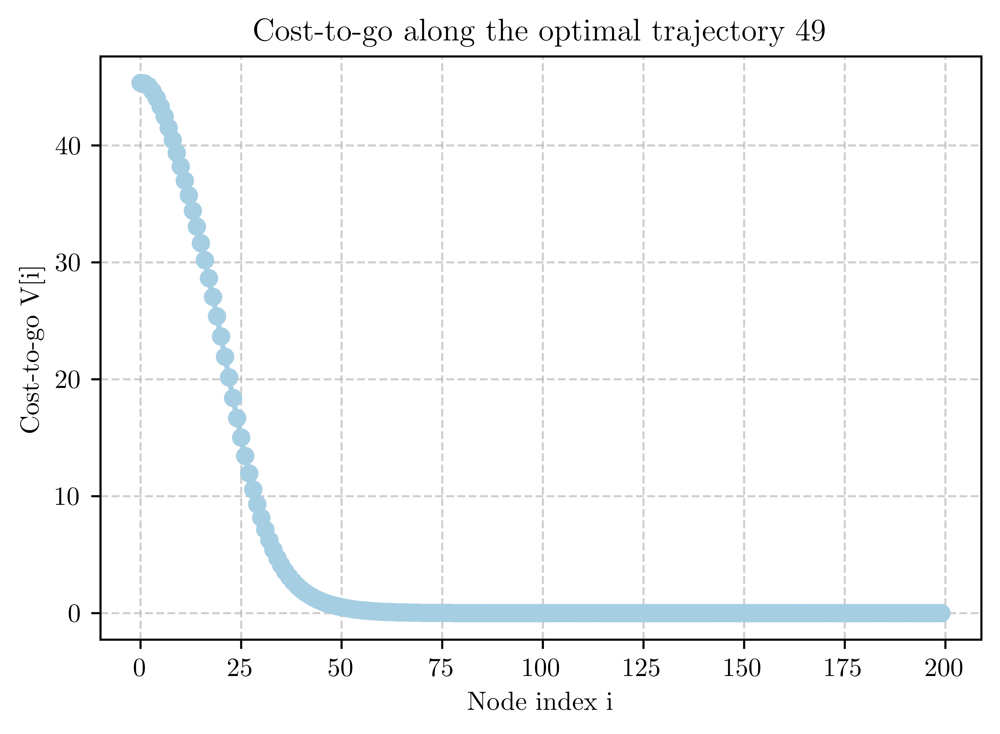

In [1138]:
def compute_value_function(traj, C, Q, R, w):
    X_star = traj['state_history']
    u_star = traj['control_history']
    N = u_star.shape[0]
    
    Y_star = (C @ X_star.T).T  # Outputs
    L = np.zeros(N)
    
    for i in range(N):
        y = Y_star[i]
        u = u_star[i]
        L[i] = y @ Q @ y + u @ R @ u

    V = np.zeros(N)
    V[-1] = w[-1] * L[-1]

    for i in range(N-2, -1, -1):
        V[i] = w[i]*L[i] + V[i+1]

    return V, L, Y_star

K_traj = 49   # Choose any stored trajectory index 
V, L, Y = compute_value_function(dataset[K_traj], C_FOM, Q, R, w)

plt.figure(figsize=(6,4))
plt.plot(V, 'o-', linewidth=2)
plt.xlabel("Node index i")
plt.ylabel("Cost-to-go  V[i]")
plt.title(f"Cost-to-go along the optimal trajectory {K_traj}")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

In [1139]:
def project_dataset(dataset, Psi_basis, C, Q, R, w):
    
    Y_list = [] # Projected states
    V_list = [] # Value function along trajectories
    U_list = [] # Optimal control along all trajectories 
    x0_all = [] # Initial conditions
    X_all = []  # Optimal state trajectories

    for data in dataset:

        X_k = data['state_history']
        X_all.append(X_k)

        V_k, _ , _ = compute_value_function(data, C, Q, R, w)

        # Projection (depends on Psi_basis → depends on r)
        Y_k = X_k @ Psi_basis

        U_list.append(data['control_history'])
        x0_all.append(data['x0'])
        Y_list.append(Y_k)
        V_list.append(V_k.reshape(-1))

    Y = np.vstack(Y_list)
    V = np.concatenate(V_list).reshape(-1, 1)
    U = np.vstack(U_list)
    x0_all = np.vstack(x0_all)
    X = np.vstack(X_all)

    return Y, V, U, X, x0_all

In [1140]:
Y, V, U, X, x0 = project_dataset(dataset, Psi_basis, C_FOM, Q, R, w)

print(f"The folowing shapes are for {basis_name}")
print("Y shape:", Y.shape)
print("V shape:", V.shape)
print("U shape:", U.shape)
print("X shape:", X.shape)
print("x0 shape:", x0.shape)

The folowing shapes are for Basoc
Y shape: (10000, 2)
V shape: (10000, 1)
U shape: (10000, 1)
X shape: (10000, 3)
x0 shape: (50, 3)


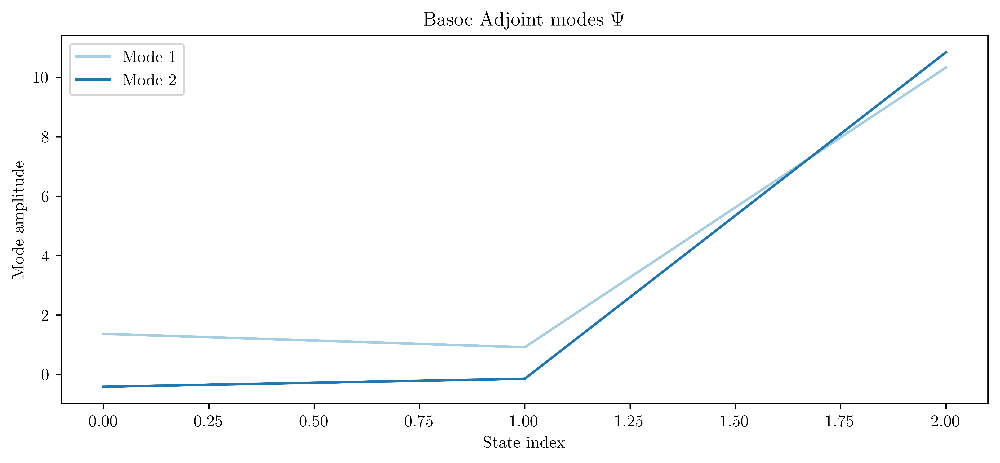

In [1141]:
plt.figure(figsize=(10,4))
for k in range(Psi_basis.shape[1]):
    plt.plot(Psi_basis[:, k], label=f"Mode {k+1}")
plt.legend()
plt.title(f"{basis_name} Adjoint modes $\Psi$")
plt.xlabel("State index")
plt.ylabel("Mode amplitude")
plt.grid(False)
plt.show()

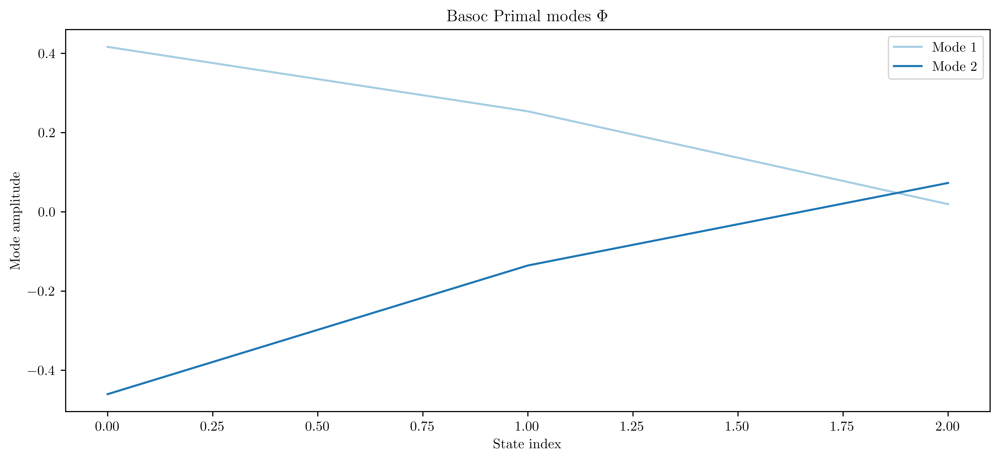

In [1142]:
plt.figure(figsize=(12,5))
for k in range(Phi_basis.shape[1]):
    plt.plot(Phi_basis[:, k], label=f"Mode {k+1}")
plt.title(f"{basis_name} Primal modes $\Phi$")
plt.xlabel("State index")
plt.ylabel("Mode amplitude")
plt.grid(False)
plt.legend()
plt.show()

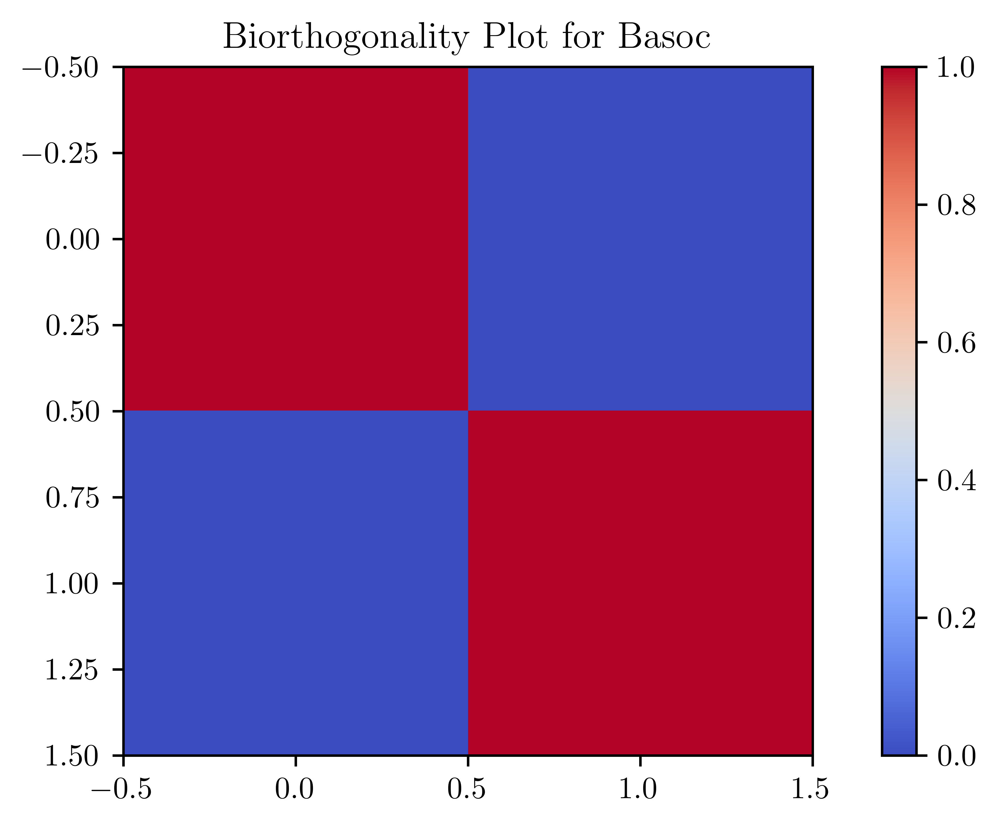

In [1143]:
plt.figure(figsize=(8,4), dpi=800)
plt.imshow(Psi_basis.T @ Phi_basis, cmap="coolwarm")
plt.colorbar()
plt.title(f"Biorthogonality Plot for {basis_name}")
plt.show()

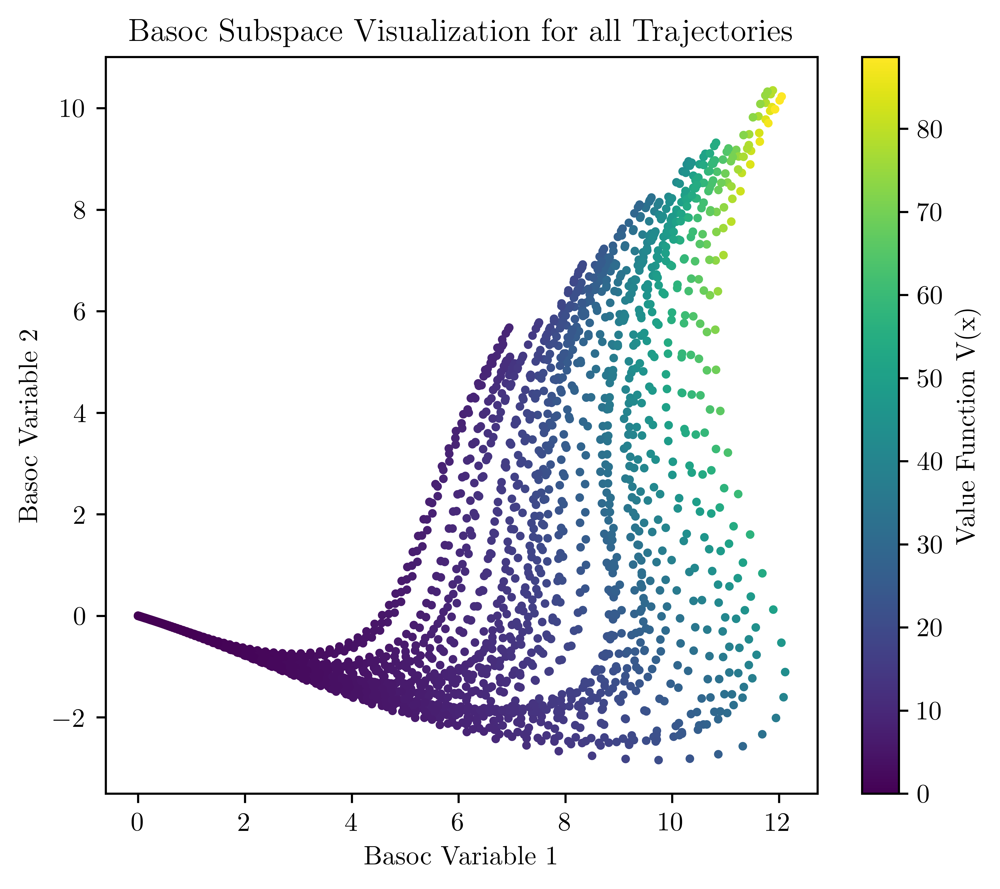

In [1144]:
#2D Subspace Visualization of the Value function for all Trajectories

def plot_Vprojection(Y, V, basis_name):
    x1 = Y[:, 0]
    x2 = Y[:, 1]
    val = V[:, 0]

    plt.figure(figsize=(6,5))
    sc = plt.scatter(x1, x2, c=val, cmap='viridis', s=5)
    plt.colorbar(sc, label="Value Function V(x)")
    plt.xlabel(f"{basis_name} Variable 1")
    plt.ylabel(f"{basis_name} Variable 2")
    plt.title(f"{basis_name} Subspace Visualization for all Trajectories")
    plt.grid(False)
    plt.show()
    
plot_Vprojection(Y, V, basis_name)

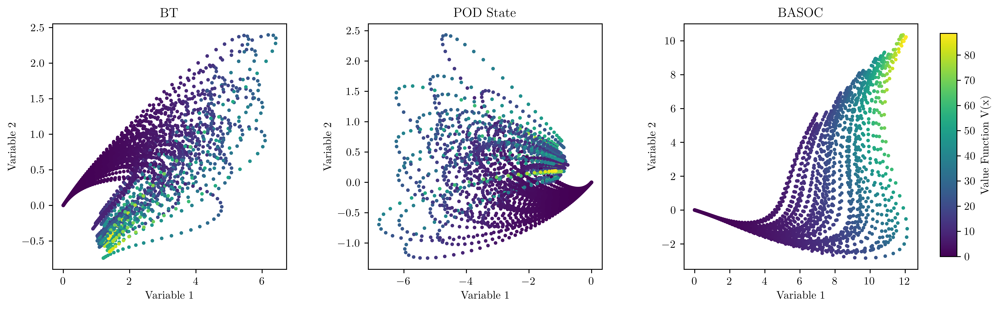

In [1145]:
plot_names = ["BT", "POD State", "Basoc"]

r = 2
fig, axes = plt.subplots(1, len(plot_names), figsize=(14,4), dpi=600)

for ax, basis_name in zip(axes, plot_names):

    if basis_name == "BT":
        Phi, Psi = compute_bt_basis(Rc, Ro, U_BT, S_BT, Vt_BT, r)
    elif basis_name == "POD State":
        Phi = Pod_State_basis(Vtx, r); Psi = Phi
    elif basis_name == "Basoc":
        Phi, Psi = compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r)

    Y, V, U, X, x0_all = project_dataset(dataset, Psi, C_FOM, Q, R, w)

    sc = ax.scatter(Y[:,0], Y[:,1], c=V[:,0], s=5, cmap='viridis')
    ax.set_title("BASOC" if basis_name == "Basoc" else basis_name)
    ax.set_xlabel("Variable 1")
    ax.set_ylabel("Variable 2")

plt.subplots_adjust(right=0.90, wspace=0.35)

cax = fig.add_axes([0.92, 0.15, 0.015, 0.70])
fig.colorbar(sc, cax=cax, label="Value Function V(x)")
plt.show()

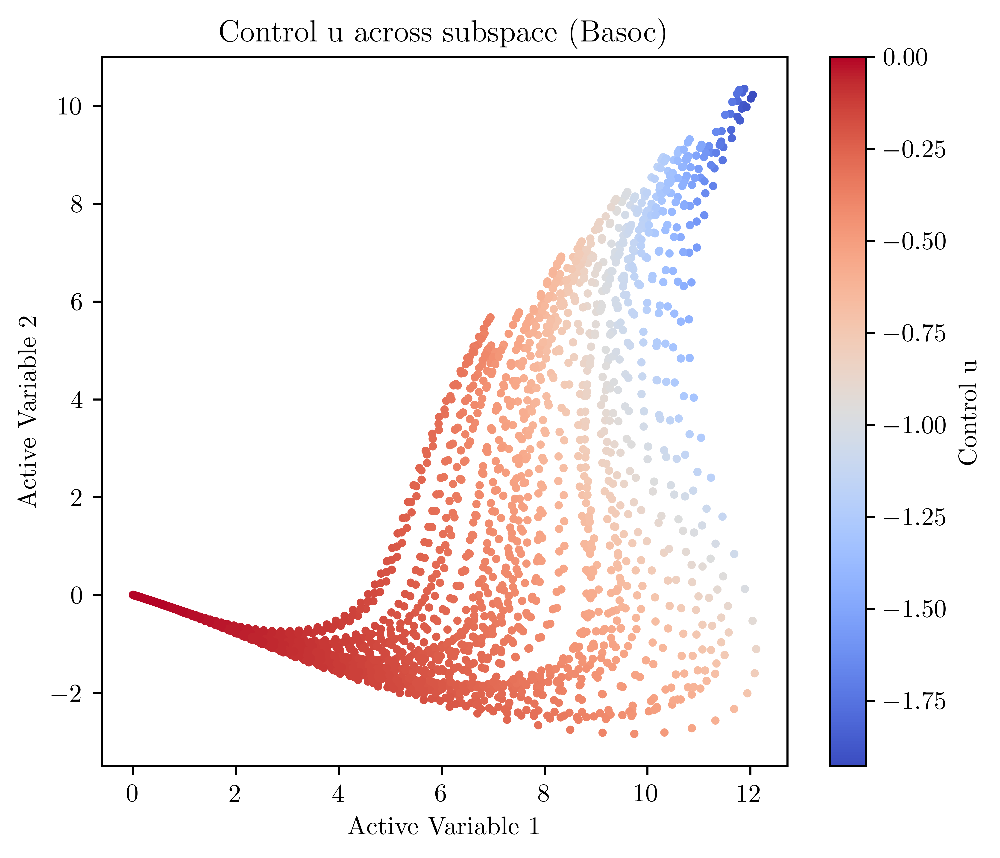

In [1146]:
def plot_controlprojection(Y, U, basis_name):

    x1 = Y[:, 0]
    x2 = Y[:, 1]

    plt.figure(figsize=(6,5))

    sc = plt.scatter(x1, x2, c=U.flatten(),cmap='coolwarm', s=5)

    plt.colorbar(sc, label="Control u")

    plt.xlabel("Active Variable 1")
    plt.ylabel("Active Variable 2")

    plt.title(f"Control u across subspace ({basis_name})")

    plt.grid(False)
    plt.show()

plot_controlprojection(Y, U, basis_name)

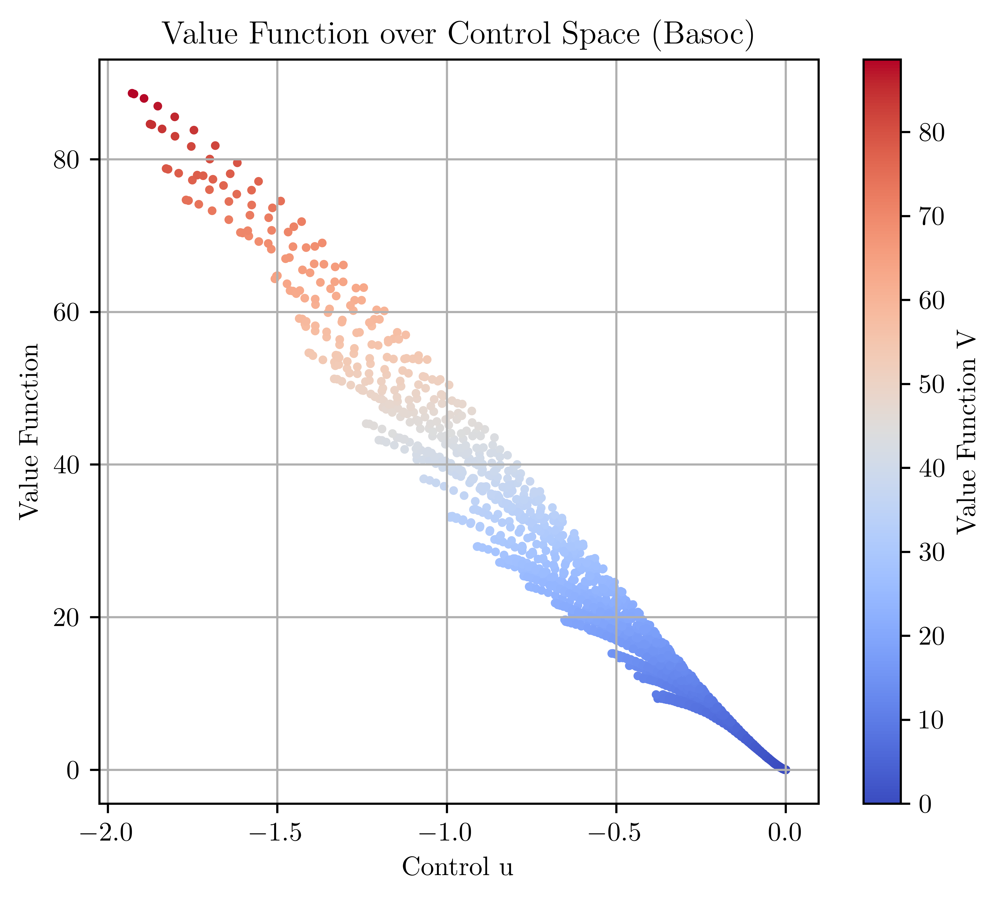

In [1147]:
def plot_value_over_control(U, V, basis_name):

    u1 = U.flatten()
    val = V.flatten()

    plt.figure(figsize=(6,5), dpi=800)

    sc = plt.scatter(u1, val,c=val, cmap='coolwarm', s=5)

    plt.colorbar(sc, label="Value Function V")

    plt.xlabel("Control u")
    plt.ylabel("Value Function")

    plt.title(f"Value Function over Control Space ({basis_name})")

    plt.grid(True)
    plt.show()

plot_value_over_control(U, V, basis_name)

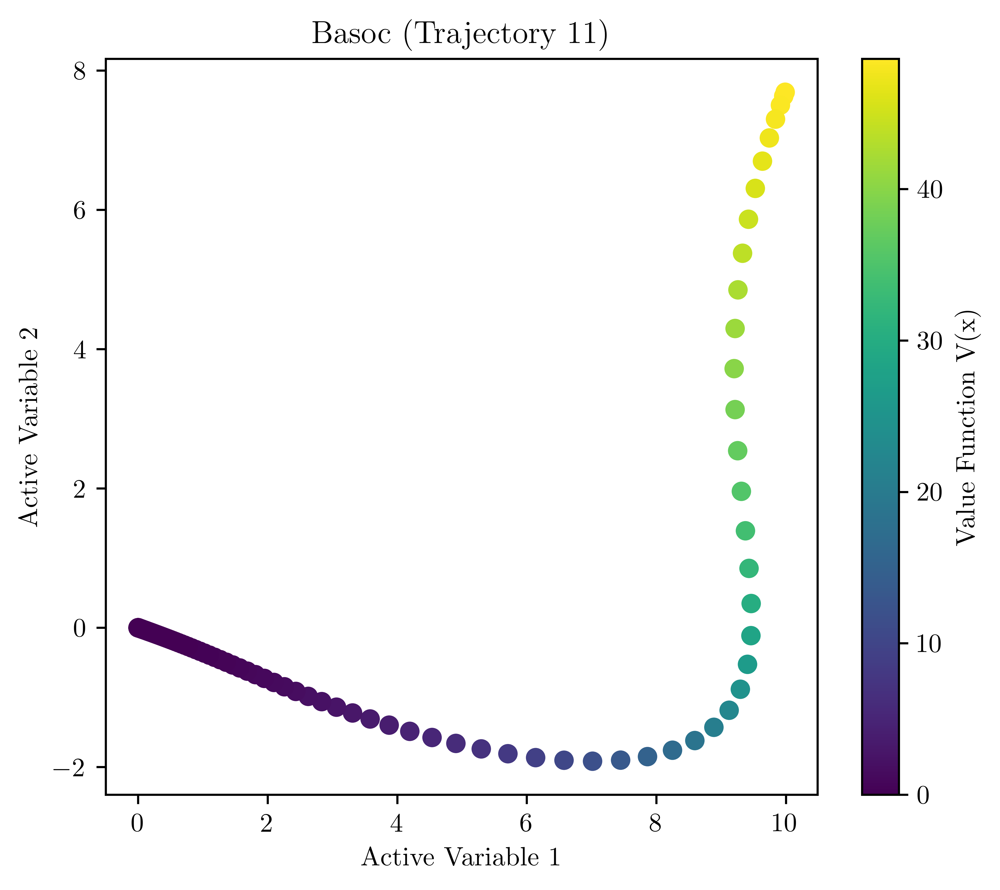

In [1148]:
def plot_block(Y, V, basis_name, block_id, block_size=200):
    
    start = block_id * block_size
    end   = start + block_size

    Y_block = Y[start:end, :]
    V_block = V[start:end, :]

    x1 = Y_block[:, 0]
    x2 = Y_block[:, 1]
    val = V_block[:, 0]

    plt.figure(figsize=(6,5))
    sc = plt.scatter(x1, x2, c=val, cmap='viridis', s=40)
    plt.colorbar(sc, label="Value Function V(x)")
    plt.xlabel("Active Variable 1")
    plt.ylabel("Active Variable 2")
    plt.title(f"{basis_name} (Trajectory {block_id+1})")
    plt.grid(False)
    plt.show()
    
plot_block(Y, V, basis_name, block_id=10)

In [1149]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score

def train_value_models(Y, V, degree=2):
    
    # Split dataset
    Y_train, Y_test, V_train, V_test = train_test_split(
        Y, V, test_size=0.30, random_state=30, shuffle=False
    )

    # Full model
    model_1 = Pipeline([
        ("poly", PolynomialFeatures(degree=degree)),
        ("linreg", LinearRegression(fit_intercept=True))
    ])
    model_1.fit(Y_train, V_train)

    V_train_pred_1 = model_1.predict(Y_train)
    V_test_pred_1  = model_1.predict(Y_test)

    print("Full Model:")
    print("  Train R² =", r2_score(V_train, V_train_pred_1))
    print("  Test  R² =", r2_score(V_test, V_test_pred_1))

    # Trimmed model
    poly = PolynomialFeatures(degree=degree, include_bias=True)

    Phi_train = poly.fit_transform(Y_train)
    d = Y_train.shape[1]
    Phi_train_reduced = Phi_train[:, (d+1):]

    model_2 = LinearRegression(fit_intercept=False)
    model_2.fit(Phi_train_reduced, V_train)

    Phi_test = poly.transform(Y_test)
    Phi_test_reduced = Phi_test[:, (d+1):]

    V_train_pred_2 = model_2.predict(Phi_train_reduced)
    V_test_pred_2  = model_2.predict(Phi_test_reduced)

    print("\nTrimmed Model (no constant, no linear terms):")
    print("  Train R² =", r2_score(V_train, V_train_pred_2))
    print("  Test  R² =", r2_score(V_test, V_test_pred_2))
    print(f'Train data is size {Y_train.shape}')
    print(f'Test data is size {Y_test.shape}')

    # Shapes of predictions and test inputs 
    print(f"V_test_pred_1 shape: {V_test_pred_1.shape}")
    print(f"V_test_pred_2 shape: {V_test_pred_2.shape}")
    print(f"Y_test shape: {Y_test.shape}")

    return model_1, model_2, Y_test, V_test, V_test_pred_1, V_test_pred_2

V_degree = 6
model1, model2, Y_test, V_test, V_pred1, V_pred2 = train_value_models(Y, V , degree=V_degree)

Full Model:
  Train R² = 0.9999908365248825
  Test  R² = 0.999989725013982

Trimmed Model (no constant, no linear terms):
  Train R² = 0.9999907488890621
  Test  R² = 0.9999902276002721
Train data is size (7000, 2)
Test data is size (3000, 2)
V_test_pred_1 shape: (3000, 1)
V_test_pred_2 shape: (3000, 1)
Y_test shape: (3000, 2)


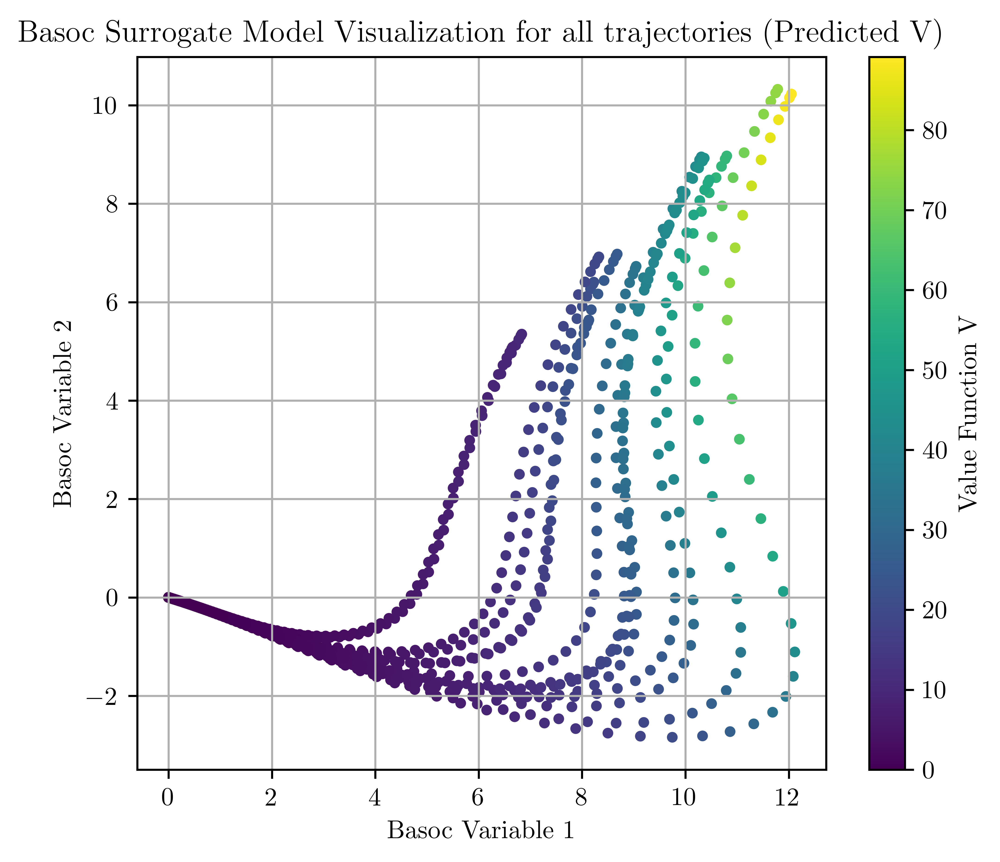

In [1150]:
def plot_surrogate_prediction(Y_test, V_pred, basis_name):
    
    x1  =  Y_test[:, 0]
    x2  =  Y_test[:, 1]
    val =  V_pred[:, 0]

    plt.figure(figsize=(6,5))
    sc = plt.scatter(x1, x2, c=val, cmap='viridis', s=10)
    plt.colorbar(sc, label="Value Function V")
    plt.xlabel(f"{basis_name} Variable 1")
    plt.ylabel(f"{basis_name} Variable 2")
    plt.title(f"{basis_name} Surrogate Model Visualization for all trajectories (Predicted V)")
    plt.grid(True)
    plt.show()

plot_surrogate_prediction(Y_test, V_pred1, basis_name)

In [1151]:
def train_control_model_polynomial(Y, U, degree):
    
    # Split
    Y_train, Y_test, U_train, U_test = train_test_split(
        Y, U, test_size=0.30,shuffle=False
    )

    # Model
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=degree)),
        ("linreg", LinearRegression(fit_intercept=True))
    ])

    model.fit(Y_train, U_train)

    # Predictions
    U_train_pred = model.predict(Y_train)
    U_test_pred  = model.predict(Y_test)

    return model, Y_test, U_test, U_test_pred , U_train, U_train_pred

u_degree = 6
model3, Y_test, U_test, U_test_pred, U_train, U_train_pred = train_control_model_polynomial(Y, U, u_degree)

print("Full Model for surrogate control law:")
print(f"  Train R² {basis_name} dim {r} =", r2_score(U_train, U_train_pred))
print(f"  Test  R² {basis_name} dim {r} =", r2_score(U_test, U_test_pred))

Full Model for surrogate control law:
  Train R² Basoc dim 2 = 0.9999771464858469
  Test  R² Basoc dim 2 = 0.9999536075125224


In [1152]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, ConstantKernel as CK, WhiteKernel
import warnings
warnings.filterwarnings("ignore")

def train_control_model_gpr(Y, U, k=1600, K_test=200):

    # Split
    Y_train, Y_test, U_train, U_test = train_test_split(
        Y, U, test_size=0.30, shuffle=False
    )

    # Model
    gpr = GaussianProcessRegressor(
        # kernel=CK(1.0) * RBF(1.0) + WhiteKernel(),
        kernel = CK(1.0) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(),
        normalize_y = False,
        # n_restarts_optimizer=2
    )

    # Train (subsample)
    gpr.fit(Y_train[:k, :], U_train[:k, :])

    # Predictions
    U_train_pred = gpr.predict(Y_train[:k, :])
    U_mean, U_std = gpr.predict(Y_test[:K_test, :], return_std=True)

    # Scores 
    r2_train = r2_score(U_train[:k, :], U_train_pred)
    r2_test  = r2_score(U_test[:K_test, :], U_mean)

    return (gpr, r2_train,r2_test)

gpr_model, r2_train_gpr, r2_test_gpr = train_control_model_gpr(Y, U, k=2400, K_test=200)
print(f"GPR Results for {basis_name} dim {r}:")
print("Train R² =", r2_train_gpr)
print("Test  R² =", r2_test_gpr)

GPR Results for Basoc dim 2:
Train R² = 0.9999895178430397
Test  R² = 0.9997634550433516


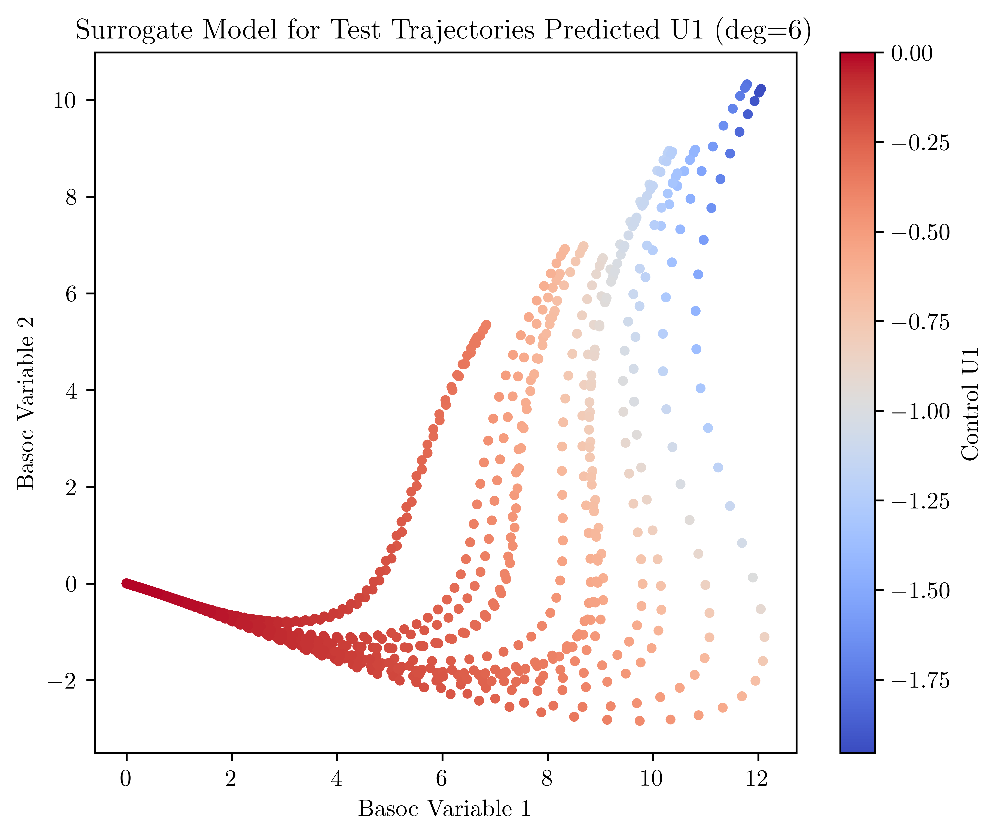

In [1153]:
def plot_control_surrogate(Y_test, U_pred, basis_name, degree):

    x1 = Y_test[:, 0]
    x2 = Y_test[:, 1]
    u1 = U_pred[:, 0]

    fig, ax = plt.subplots(figsize=(6,5))

    sc1 = ax.scatter(x1, x2, c=u1, cmap='coolwarm', s=10)
    fig.colorbar(sc1, ax=ax, label="Control U1")

    ax.set_xlabel(f"{basis_name} Variable 1")
    ax.set_ylabel(f"{basis_name} Variable 2")

    ax.set_title(f"Surrogate Model for Test Trajectories Predicted U1 (deg={degree})")

    plt.tight_layout()
    plt.show()

plot_control_surrogate(Y_test, U_test_pred, basis_name, degree=u_degree)

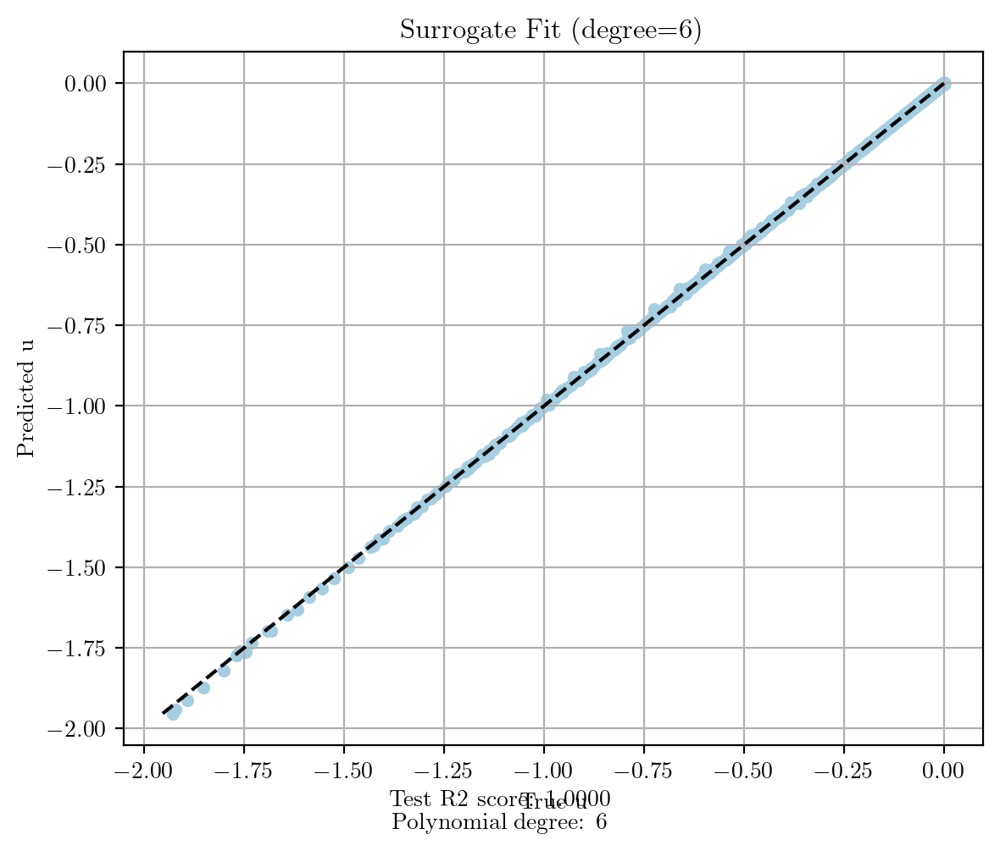

In [1154]:
def plot_control_fit(U_test, U_pred, degree):

    u1_true = U_test[:, 0]
    u1_pred = U_pred[:, 0]

    mn1 = min(u1_true.min(), u1_pred.min())
    mx1 = max(u1_true.max(), u1_pred.max())

    fig, ax = plt.subplots(figsize=(6,5), dpi=200)

    ax.scatter(u1_true, u1_pred, s=20)

    ax.plot([mn1, mx1],[mn1, mx1],'k--')

    ax.set_xlabel("True u")
    ax.set_ylabel("Predicted u")

    ax.set_title(f"Surrogate Fit (degree={degree})")

    ax.grid(True)

    textstr = (f"Test R2 score: {r2_score(U_test, U_pred):.4f}\n" f"Polynomial degree: {degree}")

    fig.text(0.5, 0.01, textstr, ha='center')

    plt.tight_layout()
    plt.show()
    
plot_control_fit(U_test, U_test_pred, degree=u_degree)

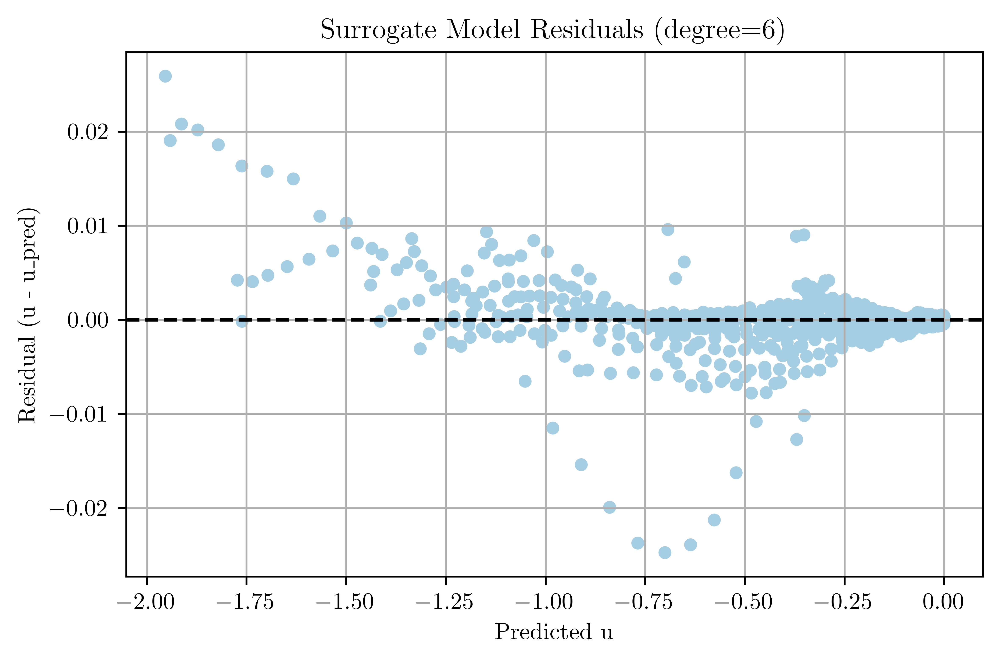

In [1155]:
def plot_control_residuals(U_test, U_pred, degree):

    res1 = U_test[:, 0] - U_pred[:, 0]

    fig, ax = plt.subplots(figsize=(6,4))
    ax.scatter(U_pred[:, 0], res1, s=20)
    ax.axhline(0, color='k', linestyle='--')

    ax.set_xlabel("Predicted u")
    ax.set_ylabel("Residual (u - u_pred)")
    ax.set_title(f"Surrogate Model Residuals (degree={degree})")
    ax.grid(True)

    plt.tight_layout()
    plt.show()

plot_control_residuals(U_test, U_test_pred, degree=u_degree)

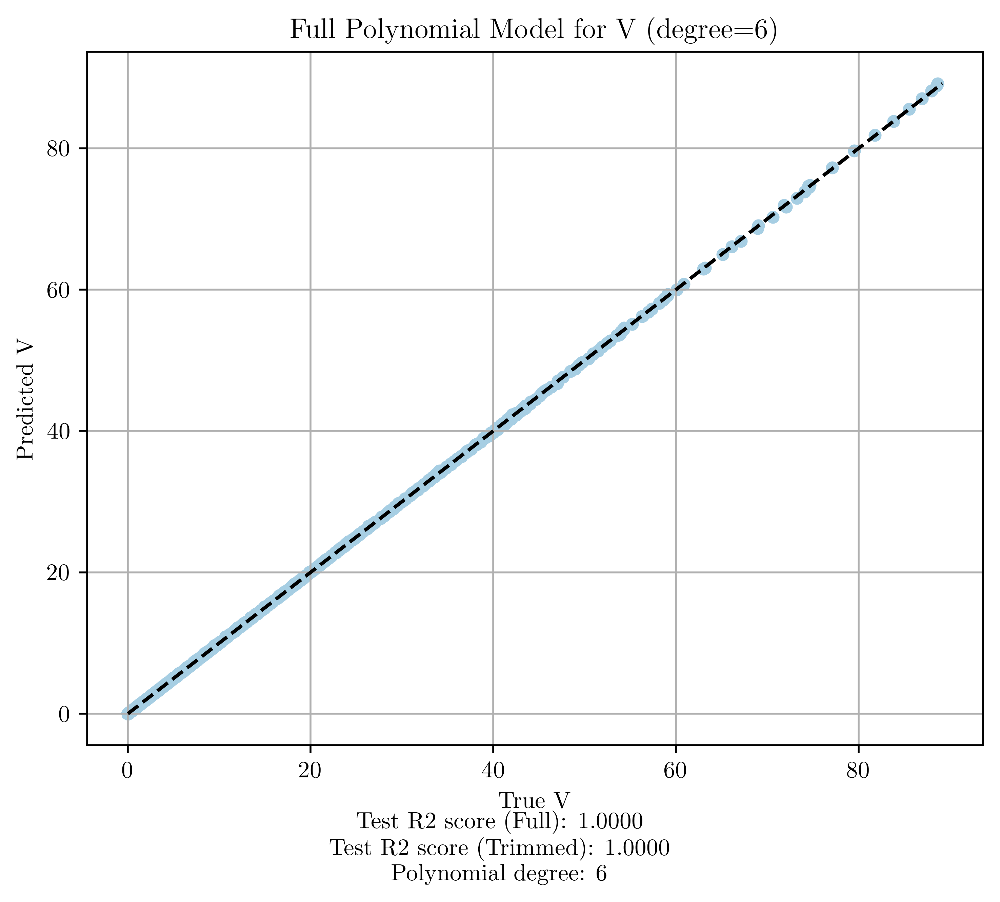

In [1156]:
def plot_value_fit(V_test, V_pred1, V_pred2, degree):

    fig, ax = plt.subplots(figsize=(6,5), dpi=500)

    ax.scatter(V_test, V_pred1, s=20)

    mn1 = min(V_test.min(), V_pred1.min())
    mx1 = max(V_test.max(), V_pred1.max())
    ax.plot([mn1, mx1],[mn1, mx1], 'k--')
    ax.set_xlabel("True V")
    ax.set_ylabel("Predicted V")
    ax.set_title(f"Full Polynomial Model for V  (degree={degree})")
    ax.grid(True)

    textstr = (f"Test R2 score (Full): {r2_score(V_test, V_pred1):.4f}\n"
        f"Test R2 score (Trimmed): {r2_score(V_test, V_pred2):.4f}\n"
        f"Polynomial degree: {degree}"
    )

    fig.text(0.5, -0.05, textstr, ha='center')

    plt.tight_layout()
    plt.show()

plot_value_fit(V_test, V_pred1, V_pred2, degree=V_degree)

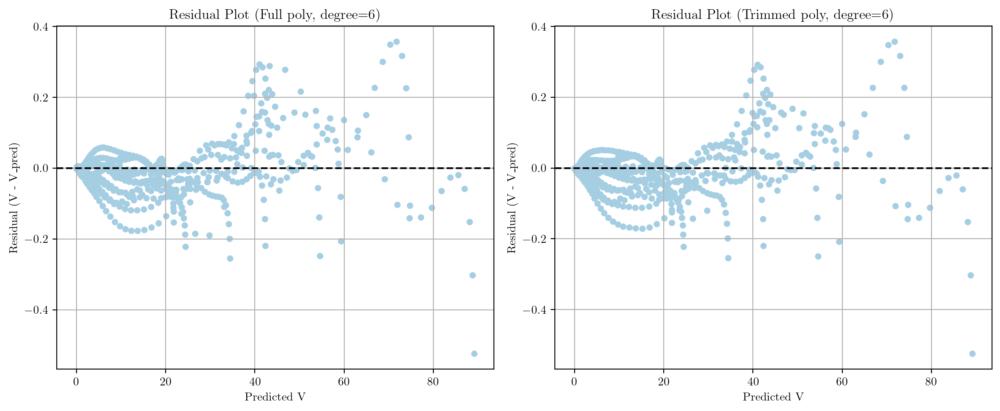

In [1157]:
def plot_value_residuals(V_test, V_pred1, V_pred2, degree):

    res1 = V_test - V_pred1
    res2 = V_test - V_pred2

    fig, axs = plt.subplots(1, 2, figsize=(12,5), dpi=200)

    # Full model 
    axs[0].scatter(V_pred1, res1, s=20)
    axs[0].axhline(0, color='k', linestyle='--')
    axs[0].set_xlabel("Predicted V")
    axs[0].set_ylabel("Residual (V - V_pred)")
    axs[0].set_title(f"Residual Plot (Full poly, degree={degree})")
    axs[0].grid(True)

    # Trimmed model 
    axs[1].scatter(V_pred2, res2, s=20)
    axs[1].axhline(0, color='k', linestyle='--')
    axs[1].set_xlabel("Predicted V")
    axs[1].set_ylabel("Residual (V - V_pred)")
    axs[1].set_title(f"Residual Plot (Trimmed poly, degree={degree})")
    axs[1].grid(True)

    plt.tight_layout()
    plt.show()

plot_value_residuals(V_test, V_pred1, V_pred2, degree=V_degree)

In [1158]:
# Choose control model
control_model = gpr_model # Could be model3 or gpr_model

In [1159]:
def learned_controller(x, Psi_basis, control_model):
    z = (x @ Psi_basis).reshape(1, -1)  # Reduce from 3 → r and reshape to (1, r)
    u = control_model.predict(z)
    u = np.asarray(u).reshape(1, -1)    # forces (1,1) regardless of model
    return u[0]                         # output shape (1,) for Polynomial control law or gaussian process 

In [1160]:
def simulate_fullstate_surrogate_feedback(x0 , Psi_basis,control_model):
    U_traj = []
    T_traj = []

    def f(t, x):
        u = learned_controller(x,Psi_basis,control_model)

        # Store
        U_traj.append(u.copy())
        T_traj.append(t)

        fx = FOM(x, u)
        return fx

    sol = solve_ivp(
        f,
        (t0, tf),
        x0,
        t_eval=t,
        method='RK45',
        rtol=rtol,
        atol=atol,
    )

    X_traj = sol.y.T
    U_traj = np.array(U_traj)
    T_traj = np.array(T_traj)

    # Print
    print("Returned sol.y.T =", X_traj.shape)
    print("Success:", sol.success)
    print("Message:", sol.message)

    return X_traj, U_traj, T_traj

IC_test = Initial_condition_test[4]
print(IC_test.shape)
X_traj, U_traj, T_traj = simulate_fullstate_surrogate_feedback(IC_test,Psi_basis,control_model)
U_star = np.array([learned_controller(x,Psi_basis,control_model) for x in X_traj])
cost = total_cost(U_star, X_traj)

print(f"The cost is {cost} for {basis_name} dim {r}")
print(f"U_star shape: {U_star.shape}")
print(f"X_traj shape: {X_traj.shape}")
print(f"U_traj shape: {U_traj.shape}")
# print(U_star)

(3,)
Returned sol.y.T = (200, 3)
Success: True
Message: The solver successfully reached the end of the integration interval.
The cost is 46.717986886379734 for Basoc dim 2
U_star shape: (200, 1)
X_traj shape: (200, 3)
U_traj shape: (650, 1)


In [1161]:
x0 = Initial_condition_test[4]

# Closed-loop surrogate trajectory
X_feedback, _, _ = simulate_fullstate_surrogate_feedback(
    x0, Psi_basis, control_model
)

U_feedback = np.array([
    learned_controller(x, Psi_basis, control_model)
    for x in X_feedback
])

J_feedback = total_cost(U_feedback, X_feedback)

# Same 200 control values, but through optimization forward solver
u_vec = pack_u(U_feedback)

X_fun = forward_trajectory(u_vec, x0)
X_open = X_fun(t).T

J_open = total_cost(u_vec, X_open)

print("J feedback =", J_feedback)
print("J open replay =", J_open)
print("Cost difference =", J_open - J_feedback)

print("Max state difference =",
      np.max(np.abs(X_open - X_feedback)))

Returned sol.y.T = (200, 3)
Success: True
Message: The solver successfully reached the end of the integration interval.
J feedback = 46.717986886379734
J open replay = 46.71797542701667
Cost difference = -1.145936306556905e-05
Max state difference = 2.899410250112311e-06


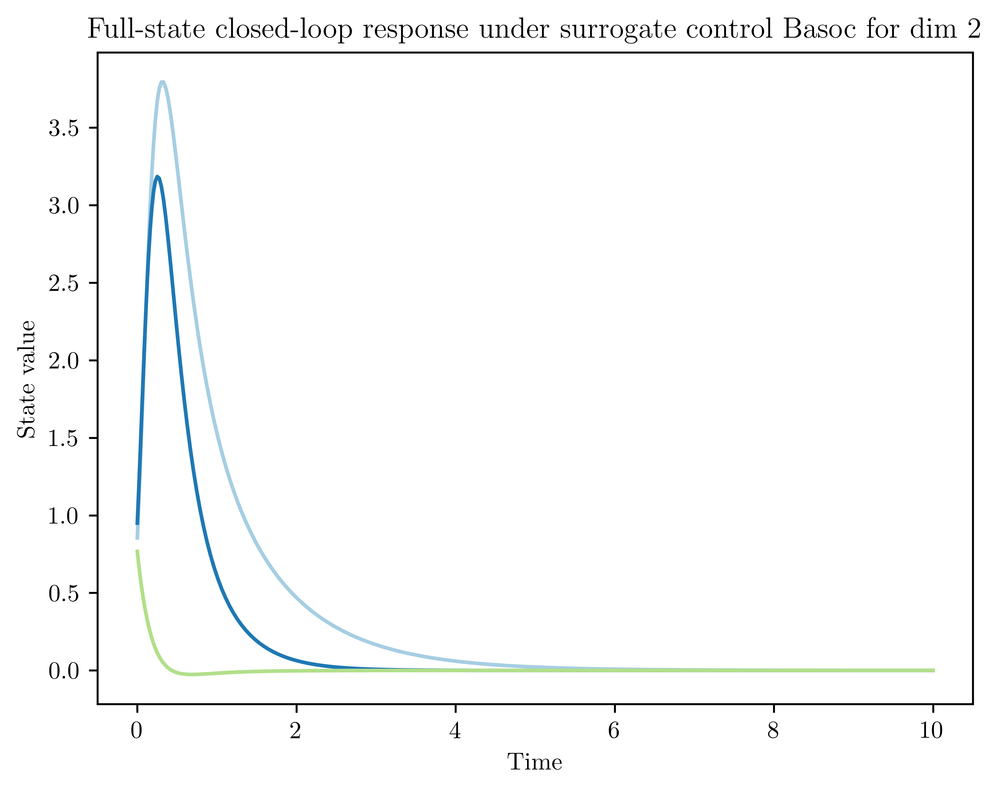

In [1162]:
def plot_state_trajectories(t, X_traj):
    plt.figure()
    for j in range(X_traj.shape[1]):
        plt.plot(t, X_traj[:, j])
        
    plt.xlabel("Time")
    plt.ylabel("State value")
    plt.title(f"Full-state closed-loop response under surrogate control {basis_name} for dim {r}")
    plt.grid(False)
    plt.show()
plot_state_trajectories(t, X_traj)

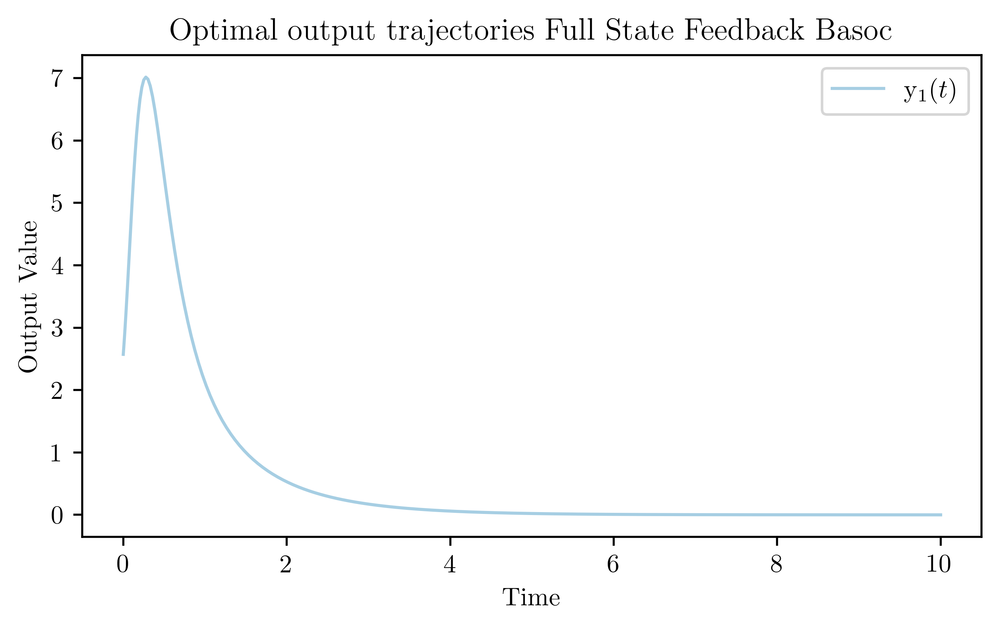

In [1163]:
def plot_output_trajectories(C, X_traj, t):
    
    # Compute outputs
    Y_star = (C @ X_traj.T).T

    plt.figure(figsize=(5.5,3.5), dpi=500)
    for j in range(Y_star.shape[1]):
        plt.plot(t, Y_star[:, j], label=fr"$\mathrm{{y}}_{{{j+1}}}(t)$", linewidth=1.2)

    plt.xlabel("Time")
    plt.ylabel("Output Value")
    plt.title(f"Optimal output trajectories Full State Feedback {basis_name}")
    plt.legend()
    plt.tight_layout()
    plt.grid(False)
    plt.show()

plot_output_trajectories(C_FOM, X_traj, t)

In [1164]:
# r_values = list(range(2, 3))

# # Cost comparison across methods for full state feedback 
# # For a new r across the methods, train a new surrogate 

# J_true_trajectory_optimization = 500.762

# results_rombasedfeedback = {name: {"r": [], "J": [], "err": [], "err_abs_rel": [], "r2_test": []} for name in names}

# for basis_name in names:
#     for r in r_values:

#         print(f"Running {basis_name}, r = {r}")

#         # Build basis
#         if basis_name == "BT":
#             Phi_basis_romfeedback, Psi_basis_romfeedback = compute_bt_basis(
#                 Rc, Ro, U_BT, S_BT, Vt_BT, r
#             )

#         elif basis_name == "POD State":
#             Phi_basis_romfeedback = Pod_State_basis(Vtx, r)
#             Psi_basis_romfeedback = Phi_basis_romfeedback

#         elif basis_name == "POD Adjoint":
#             Phi_basis_romfeedback = Pod_Adjoint_basis(Vtg, r)
#             Psi_basis_romfeedback = Phi_basis_romfeedback

#         elif basis_name == "Basoc":
#             Phi_basis_romfeedback, Psi_basis_romfeedback = compute_basoc_basis(
#                 Rx, Rg, U_basoc, S_basoc, Vt_basoc, r
#             )
        
#         # elif basis_name == "Basoc-qs":
#         #     Phi_basis_romfeedback, Psi_basis_romfeedback = compute_basoc_basis_qs(
#         #       Rx_qs, Rg_qs, U_qs, S_qs, Vt_qs, r
#         #     )

#         # Project dataset
#         Y, V, U, X, x0_all = project_dataset( dataset, Psi_basis_romfeedback,C_FOM , Q , R , w )

#         # # Train surrogate polynomial
#         # model3, Y_test, U_test, U_test_pred, U_train, U_train_pred = train_control_model_polynomial(Y, U, u_degree)

#         #  Train surrogate gpr
#         gpr_model, r2_train_gpr, r2_test_gpr = train_control_model_gpr(Y, U, k=2400, K_test=200)

#         # Choose control surrogate model
#         control_model = gpr_model

#         # Simulate full state feedback with surrogate control
#         X_traj, U_traj, T_traj = simulate_fullstate_surrogate_feedback(IC_test,Psi_basis_romfeedback,control_model)

#         Z = X_traj @ Psi_basis_romfeedback
        
#         U_star = control_model.predict(Z)

#         # Full-state feedback cost 
#         J_fullstate_feedback = total_cost(U_star, X_traj)

#         # Error 
#         error = J_fullstate_feedback - J_true_trajectory_optimization

#         # Relative Error 
#         error_abs_relative = (J_fullstate_feedback - J_true_trajectory_optimization) / J_true_trajectory_optimization 

#         results_rombasedfeedback[basis_name]["r"].append(r)
#         results_rombasedfeedback[basis_name]["J"].append(J_fullstate_feedback)
#         results_rombasedfeedback[basis_name]["err"].append(error)
#         results_rombasedfeedback[basis_name]["r2_test"].append(U_test_pred)
#         results_rombasedfeedback[basis_name]["err_abs_rel"].append(error_abs_relative)

#         print(f"{basis_name}, r={r} → J={J_fullstate_feedback:.4f}, error={error:.4f}, abs_rel_error = {error_abs_relative}")

In [1165]:
# for basis_name in names:
#     print(f"{basis_name} Relative Error at r=2 = {results_rombasedfeedback[basis_name]['err_abs_rel'][1]}")

In [1166]:
# plt.figure(figsize=(8,5))
# for name in names:
#     plt.plot(
#         results_rombasedfeedback[name]["r"],
#         results_rombasedfeedback[name]["err_abs_rel"],
#         marker='o',
#         linewidth=2,
#         label=name
#     )
# plt.xlabel("Reduced dimension r", fontsize=20)
# plt.ylabel(r"$\mathbf{\frac{J - J^{*}}{J^{*}}}$", fontsize=20)
# plt.yscale('log')
# plt.title("Relative Cost Error vs Reduced Dimension - Full State Feedback", fontsize=20)
# plt.legend()
# plt.grid(False)
# plt.tight_layout()
# plt.minorticks_off()
# plt.show()

In [1167]:
# n_test_IC = 30

# results_rombasedfeedback = {name: {} for name in names}

# for basis_name in names:

#     r_values = [3] if basis_name == "Full_State" else [2]

#     for r in r_values:

#         print(f"\nRunning {basis_name}, r = {r}")

#         if basis_name == "Full_State":
#             Phi_basis_romfeedback = Full_State_basis(3)
#             Psi_basis_romfeedback = Phi_basis_romfeedback

#         elif basis_name == "BT":
#             Phi_basis_romfeedback, Psi_basis_romfeedback = compute_bt_basis(
#                 Rc, Ro, U_BT, S_BT, Vt_BT, r
#             )

#         elif basis_name == "POD State":
#             Phi_basis_romfeedback = Pod_State_basis(Vtx, r)
#             Psi_basis_romfeedback = Phi_basis_romfeedback

#         elif basis_name == "POD Adjoint":
#             Phi_basis_romfeedback = Pod_Adjoint_basis(Vtg, r)
#             Psi_basis_romfeedback = Phi_basis_romfeedback

#         elif basis_name == "Basoc":
#             Phi_basis_romfeedback, Psi_basis_romfeedback = compute_basoc_basis(
#                 Rx, Rg, U_basoc, S_basoc, Vt_basoc, r
#             )

#         Y, V, U, X, x0_all = project_dataset(dataset, Psi_basis_romfeedback, C_FOM, Q, R, w)

#         # Best data amont for the GPR is 2400
#         gpr_model, r2_train_gpr, r2_test_gpr = train_control_model_gpr(Y, U, k=2400, K_test=200)

#         control_model = gpr_model

#         J_rom_all = []
#         err_all = []
#         err_abs_rel_all = []

#         for i, x0 in enumerate(Initial_condition_test[:n_test_IC]):

#             print(f"\n--- Running {basis_name}, r={r}, IC={i+1} ---")

#             J_true = J_all_test[i]

#             X_traj, U_traj, T_traj = simulate_fullstate_surrogate_feedback(x0,Psi_basis_romfeedback,control_model)

#             Z = X_traj @ Psi_basis_romfeedback

#             U_star = control_model.predict(Z)

#             J_fullstate_feedback = total_cost(U_star, X_traj)
       
#             error = J_fullstate_feedback - J_true
#             print(error)
            
#             # Using the relative error here without the abs for convinience for the paper
#             error_abs_relative = abs(error) / J_true
#             # error_abs_relative = error / J_true
#             # error = error / J_true

#             J_rom_all.append(J_fullstate_feedback)
#             err_all.append(error)
#             err_abs_rel_all.append(error_abs_relative)

#             print(
#                 f"{basis_name}, r={r}, IC={i+1} "
#                 f"→ J_true={J_true:.8f}, "
#                 f"J_rom={J_fullstate_feedback:.8f}, "
#                 f"rel_error={error_abs_relative:.6e}"
#             )

#         results_rombasedfeedback[basis_name][f"r={r}"] = {
#             "J": J_rom_all,
#             "err": err_all,
#             "err_abs_rel": err_abs_rel_all,
#             "r2_test": r2_test_gpr,
#         }

#         print(
#             f"\n{basis_name}, r={r} complete | "
#             f"median rel error = {np.median(err_abs_rel_all):.6e}"
#             f"mean relative error = {np.mean(err_abs_rel_all):.6e}"
#         )

In [1168]:
# #  This is with Replay
# n_test_IC = 30

# results_rombasedfeedback = {name: {} for name in names}

# for basis_name in names:

#     r_values = [3] if basis_name == "Full_State" else [2]

#     for r in r_values:

#         print(f"\nRunning {basis_name}, r = {r}")

#         if basis_name == "Full_State":
#             Phi_basis_romfeedback = Full_State_basis(3)
#             Psi_basis_romfeedback = Phi_basis_romfeedback

#         elif basis_name == "BT":
#             Phi_basis_romfeedback, Psi_basis_romfeedback = compute_bt_basis(
#                 Rc, Ro, U_BT, S_BT, Vt_BT, r
#             )

#         elif basis_name == "POD State":
#             Phi_basis_romfeedback = Pod_State_basis(Vtx, r)
#             Psi_basis_romfeedback = Phi_basis_romfeedback

#         elif basis_name == "POD Adjoint":
#             Phi_basis_romfeedback = Pod_Adjoint_basis(Vtg, r)
#             Psi_basis_romfeedback = Phi_basis_romfeedback

#         elif basis_name == "Basoc":
#             Phi_basis_romfeedback, Psi_basis_romfeedback = compute_basoc_basis(
#                 Rx, Rg, U_basoc, S_basoc, Vt_basoc, r
#             )

#         Y, V, U, X, x0_all = project_dataset(dataset, Psi_basis_romfeedback, C_FOM, Q, R, w)

#         # Best data amont for the GPR is 2400
#         gpr_model, r2_train_gpr, r2_test_gpr = train_control_model_gpr(Y, U, k=2400, K_test=200)

#         control_model = gpr_model

#         J_rom_all = []
#         err_all = []
#         err_abs_rel_all = []

#         for i, entry in enumerate(dataset_test[:n_test_IC]):
            
#             x0 = entry['x0']

#             print(f"\n--- Running {basis_name}, r={r}, IC={i+1} ---")

#             J_true = J_all_test[i]

#             X_traj, U_traj, T_traj = simulate_fullstate_surrogate_feedback(x0,Psi_basis_romfeedback,control_model)

#             Z = X_traj @ Psi_basis_romfeedback

#             U_star = control_model.predict(Z)

#             # Replay surrogate controls using the same control representation
#             # as the trajectory optimization
#             u_vec = pack_u(U_star)
#             X_replay = forward_trajectory(u_vec, x0)(t).T

#             J_fullstate_feedback = total_cost(u_vec, X_replay)
       
#             error = J_fullstate_feedback - J_true
#             print(error)
            
#             # Using the relative error here without the abs for convinience for the paper
#             error_abs_relative = abs(error) / J_true
#             # error_abs_relative = error / J_true
#             # error = error / J_true

#             J_rom_all.append(J_fullstate_feedback)
#             err_all.append(error)
#             err_abs_rel_all.append(error_abs_relative)

#             print(
#                 f"{basis_name}, r={r}, IC={i+1} "
#                 f"→ J_true={J_true:.8f}, "
#                 f"J_rom={J_fullstate_feedback:.8f}, "
#                 f"rel_error={error_abs_relative:.6e}"
#             )

#         results_rombasedfeedback[basis_name][f"r={r}"] = {
#             "J": J_rom_all,
#             "err": err_all,
#             "err_abs_rel": err_abs_rel_all,
#             "r2_test": r2_test_gpr,
#         }

#         print(
#             f"\n{basis_name}, r={r} complete | "
#             f"median rel error = {np.median(err_abs_rel_all):.6e}"
#             f"mean relative error = {np.mean(err_abs_rel_all):.6e}"
#         )

In [1169]:
# r_plot = 2
# box_data = [
#     results_rombasedfeedback["BT"][f"r={r_plot}"]["err_abs_rel"],
#     results_rombasedfeedback["POD State"][f"r={r_plot}"]["err_abs_rel"],
#     results_rombasedfeedback["POD Adjoint"][f"r={r_plot}"]["err_abs_rel"],
#     results_rombasedfeedback["Basoc"][f"r={r_plot}"]["err_abs_rel"],
# ]

# plt.figure(figsize=(6,4))
# plt.boxplot(box_data, labels=["BT", "POD-State", "POD Adj", "BASOC"], showmeans=True)
# plt.yscale("log")
# plt.ylabel("Relative Cost Error", fontsize=16)
# plt.title(f"Full-State Feedback Absolute Cost Error Across Test Initial Conditions (r={r_plot})")
# plt.minorticks_off()
# plt.show()

In [1170]:
# plt.figure(figsize=(6,4))
# plt.boxplot(
#     box_data,
#     labels=["BT", "POD State", "POD Adjoint", "BASOC"],
#     showmeans=True,
#     meanprops=dict(
#         marker="^",
#         markerfacecolor="#fb9a99",
#         markeredgecolor= "black",
#         markersize=10.5
#     )
# )
# plt.xticks(fontsize=12)

# # plt.boxplot(
# #     box_data,
# #     labels=["BT", "POD State", "POD Adj", "BASOC"],
# #     showmeans=True
# # )

# for i, data in enumerate(box_data, start=1):
#     x = np.random.normal(i, 0.03, size=len(data))
#     plt.scatter(x, data, alpha=0.9, s=20)

# #This is without jitter and the above is with jitter 
# # for i, data in enumerate(box_data, start=1):
# #     plt.scatter(np.ones(len(data))*i, data, alpha=0.9, s=20)

# plt.yscale("log")
# plt.ylabel("Relative Cost Error (Log Scale)", fontsize=13)
# plt.ylabel(
#     r"$\mathbf{Relative\ Cost\ Error\ (Log\ Scale)}$",
#     fontsize=13
# )
# # plt.title(f"Full-State Feedback Cost Error Accross Test Initial Conditions (r={r_plot})")
# plt.title(f"Full-State Feedback Relative Cost Error (r={r_plot})", fontsize=13)
# plt.title(
#     rf"$\mathbf{{Full\!-\!State\ Feedback\ Relative\ Cost\ Error\ (r={r_plot})}}$",
#     fontsize=13
# )
# plt.minorticks_off()
# plt.show()

In [1171]:
# r_plot = 2

# box_data = [
#     results_rombasedfeedback["BT"][f"r={r_plot}"]["err_abs_rel"],
#     results_rombasedfeedback["POD State"][f"r={r_plot}"]["err_abs_rel"],
#     results_rombasedfeedback["POD Adjoint"][f"r={r_plot}"]["err_abs_rel"],
#     results_rombasedfeedback["Basoc"][f"r={r_plot}"]["err_abs_rel"],
#     results_rombasedfeedback["Full_State"]["r=3"]["err_abs_rel"],
# ]

# plt.figure(figsize=(6,4))
# plt.boxplot(box_data, labels=["BT", "POD State", "POD Adjoint", "BASOC", "Full"], showmeans=True, meanprops=dict( marker="^", markerfacecolor="#fb9a99",
#         markeredgecolor="black",
#         markersize=10.5
#     ))

# plt.xticks(fontsize=11)

# for i, data in enumerate(box_data, start=1):
#     x = np.random.normal(i, 0.03, size=len(data))
#     plt.scatter(x, data, alpha=0.9, s=20)

# plt.yscale("log")
# plt.ylabel("relative cost error", fontsize=12)
# # plt.ylabel(r"Relative Cost Error  $(\mathrm{J}-\mathrm{J}^*)/\mathrm{J}^*$", fontsize=12)
# # plt.title(f"Full-State Feedback Relative Cost Error (r={r_plot})",fontsize=12)
# plt.minorticks_off()
# plt.savefig("full_state_feedback_toy_extrapolate.pdf", bbox_inches="tight")
# plt.show()

In [1172]:
print(C_FOM.shape)
print (H_FOM.shape)

(1, 3)
(3, 3, 3)


In [1173]:
# Defining the ROM
def get_ROM_tensors(Phi, Psi , A_FOM, B_FOM , C_FOM, H_FOM, N_FOM):
    A_ROM = np.einsum('ji, jk, kl', Psi, A_FOM, Phi)
    B_ROM = np.einsum('ji, jk', Psi, B_FOM)
    C_ROM = np.einsum('ij, jk', C_FOM, Phi)
    H_ROM = np.einsum('ji,jkl,km,ln', Psi, H_FOM, Phi, Phi)
    N_ROM = np.einsum('ji,jkl,lm', Psi, N_FOM, Phi)
    return A_ROM, B_ROM, C_ROM, H_ROM, N_ROM

A_ROM, B_ROM, C_ROM, H_ROM, N_ROM = get_ROM_tensors(Phi_basis, Psi_basis, A_FOM, B_FOM, C_FOM, H_FOM, N_FOM)

print(f"A_ROM shape for {basis_name}: {A_ROM.shape}")  # r x r  
print(f"B_ROM shape for {basis_name}: {B_ROM.shape}")  # r x m
print(f"C_ROM shape for {basis_name}: {C_ROM.shape}")  # p x r
print(f"H_ROM shape for {basis_name}: {H_ROM.shape}")  # r x r x r
print(f"N_ROM shape for {basis_name}: {N_ROM.shape}")  # r x m x r  

A_ROM shape for Basoc: (2, 2)
B_ROM shape for Basoc: (2, 1)
C_ROM shape for Basoc: (1, 2)
H_ROM shape for Basoc: (2, 2, 2)
N_ROM shape for Basoc: (2, 1, 2)


In [1174]:
def forward_trajectory_ROM(u_traj, z_init, A_ROM, B_ROM, H_ROM, N_ROM):

    u_fun = make_u_fun(u_traj)
    def f_ROM(tq, z):
        
        u = u_fun(tq)
        f = np.einsum('ij,...j', A_ROM, z) + np.einsum('ij,...j', B_ROM, u) + \
        np.einsum('ijk,...j,...k', H_ROM, z, z) + np.einsum('ijk,...j,...k', N_ROM, u, z)
        return f

    sol_rom = solve_ivp(f_ROM, (t0, tf), z_init, t_eval=t, method='RK45', rtol=rtol, atol=atol)
    
    return sol_rom.y.T  # (Nt, r)

In [1175]:
x0_test = np.array([data['x0'] for data in dataset_test])
U_test  = np.array([data['control_history'] for data in dataset_test])
X_test  = np.array([data['state_history'] for data in dataset_test])
print(x0_test.shape)
print(U_test.shape)
print(x0_test[0])

(30, 3)
(30, 200, 1)
[0.98000865 0.84975602 0.99993365]


In [1176]:
def get_optimal_trajectory_data(x0, U, Psi_basis, traj_id, N):
    
    # Initial condition
    x_init = x0[traj_id]

    # Reduced initial condition
    z_init = Psi_basis.T @ x_init

    # Control segment
    start = traj_id * N
    end = start + N
    u_traj = U[start:end, :]

    return x_init, z_init, u_traj

def get_test_trajectory_data(x_init, u_traj, X_traj, Psi_basis):
    z_init = Psi_basis.T @ x_init
    return x_init, z_init, u_traj, X_traj

traj_id = 0
x_init, z_init, u_traj, X_traj = get_test_trajectory_data(x0_test[traj_id], U_test[traj_id], X_test[traj_id], Psi_basis)
solution_rom = forward_trajectory_ROM(u_traj, z_init, A_ROM, B_ROM, H_ROM, N_ROM)

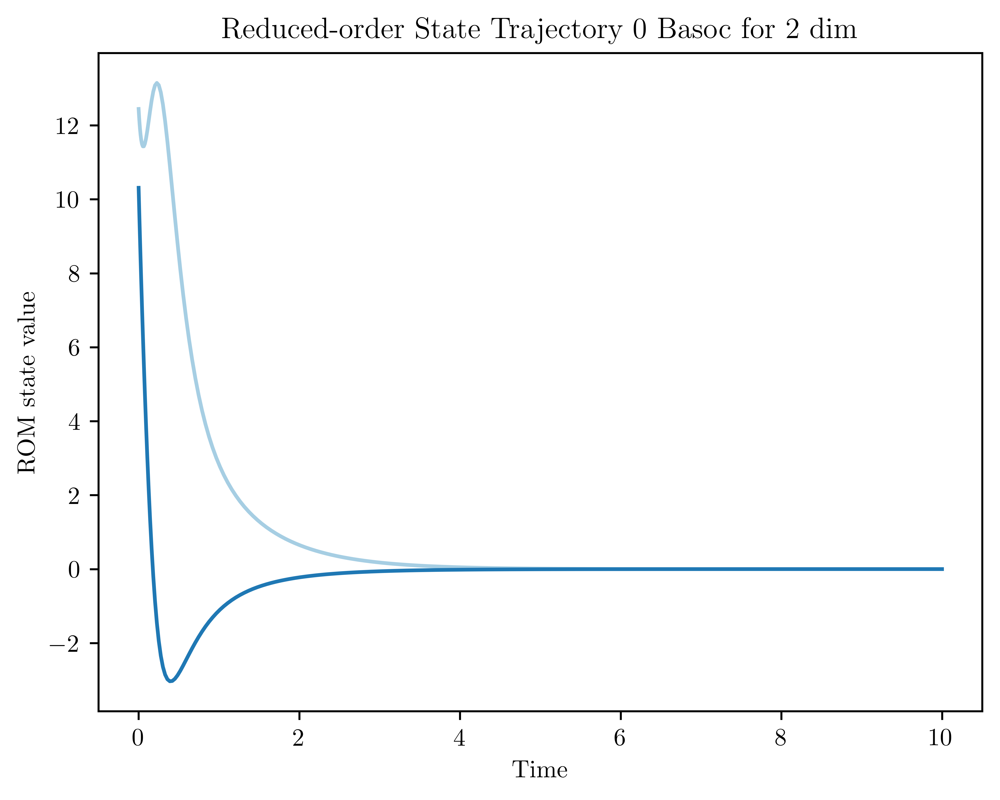

In [1177]:
def plot_rom_states(t, solution_rom, basis_name, r):
     
    for j in range(solution_rom.shape[1]):
        plt.plot(t, solution_rom[:, j])

    plt.xlabel("Time")
    plt.ylabel("ROM state value")
    plt.title(f"Reduced-order State Trajectory {traj_id} {basis_name} for {r} dim")
    plt.grid(False)
    plt.show()
    
plot_rom_states(t, solution_rom, basis_name, r)

In [1178]:
# FOM SIMULATION ALONG OPTIMAL TRAJECTORY FOR COMPARISON WITH ROM 

def simulate_FOM(x_init, u_traj, t0, tf, t):

    u_fun = make_u_fun(u_traj)

    def FOM_dynamics(tq, x):
        return FOM(x, u_fun(tq))

    sol = solve_ivp(FOM_dynamics, (t0, tf), x_init, t_eval=t, method='RK45', rtol=1e-7, atol=1e-9)
    return sol.y.T

fom = simulate_FOM(x_init, u_traj, t0, tf, t)
# x_rom_true = fom @ Psi_basis 
# e = x_rom_true - solution_rom    # (200, 2)
# Q_est = np.cov(e.T)

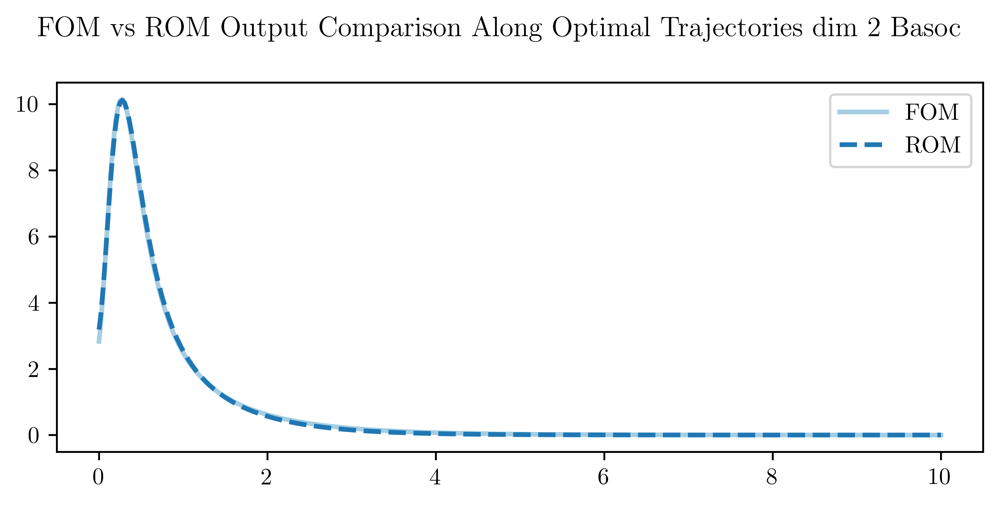

In [1179]:
def plot_fom_vs_rom_outputs(C_FOM, C_ROM, X_fom, solution_rom, t):

    # Compute outputs
    Y_fom = (C_FOM @ X_fom.T).T
    Y_rom = (C_ROM @ solution_rom.T).T

    fig, ax = plt.subplots(figsize=(6,3))

    # Output 1
    ax.plot(t, Y_fom[:, 0], label='FOM', linewidth=2)
    ax.plot(t, Y_rom[:, 0], '--', label='ROM', linewidth=2)
    ax.legend()

    plt.suptitle(f"FOM vs ROM Output Comparison Along Optimal Trajectories dim {r} {basis_name}")
    plt.tight_layout()
    plt.show()

plot_fom_vs_rom_outputs(C_FOM, C_ROM, fom, solution_rom, t)

In [1180]:
def compute_rom_error(solution_rom, Phi_basis, fom, C_FOM, C_ROM):
    
    # Lift ROM to full space 
    x_rom_lifted = solution_rom @ Phi_basis.T

    # State error 
    state_error = np.linalg.norm(fom - x_rom_lifted, 'fro') / np.linalg.norm(fom, 'fro')

    # Output error 
    Y_fom = (C_FOM @ fom.T).T
    Y_rom = (C_ROM @ solution_rom.T).T

    output_error = np.linalg.norm(Y_fom - Y_rom, 'fro') / np.linalg.norm(Y_fom, 'fro')

    return state_error, output_error

state_err, output_err = compute_rom_error(solution_rom, Phi_basis, fom, C_FOM, C_ROM)
print(f"Relative State error -fro (FOM vs ROM_lifted) Traj {traj_id}: {state_err} for dim {r} {basis_name}")
print(f"Relative Output error -fro (FOM vs ROM) Traj {traj_id}: {output_err} for dim {r} {basis_name}")

Relative State error -fro (FOM vs ROM_lifted) Traj 0: 0.11877857660089604 for dim 2 Basoc
Relative Output error -fro (FOM vs ROM) Traj 0: 0.025914585304552325 for dim 2 Basoc


In [1181]:
# all_state_errors = {}
# all_output_errors = {}
# all_y_rom = {}

# for basis_name in names:

#     for r in [2]:

#         # Select basis
#         if basis_name == "BT":
#             Phi_basis_r, Psi_basis_r = compute_bt_basis(Rc, Ro, U_BT, S_BT, Vt_BT, r)

#         elif basis_name == "POD State":
#             Phi_basis_r = Pod_State_basis(Vtx, r)
#             Psi_basis_r = Phi_basis_r

#         elif basis_name == "POD Adjoint":
#             Phi_basis_r = Pod_Adjoint_basis(Vtg, r)
#             Psi_basis_r = Phi_basis_r

#         elif basis_name == "Basoc":
#             Phi_basis_r, Psi_basis_r = compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r)

#         # Build ROM
#         A_ROM_r, B_ROM_r, C_ROM_r, H_ROM_r, N_ROM_r = get_ROM_tensors(Phi_basis_r, Psi_basis_r, A_FOM, B_FOM, C_FOM, H_FOM, N_FOM)

#         # Trajectory data
#         x_init, z_init, u_traj, X_traj = get_test_trajectory_data(x0_test[traj_id], U_test[traj_id], X_test[traj_id], Psi_basis_r)

#         # Simulations
#         solution_rom = forward_trajectory_ROM(u_traj, z_init, A_ROM_r, B_ROM_r, H_ROM_r, N_ROM_r)
#         y_rom = solution_rom @ C_ROM_r.T

#         # Making it X_traj is the same as simulating it. 
#         solution_fom = simulate_FOM(x_init, u_traj, t0, tf, t)
#         solution_fom = X_traj
#         y_fom = solution_fom @ C_FOM.T

#         # Store ROM outputs
#         all_y_rom[basis_name] = y_rom

#         # Store fom output
#         y_fom_reference = y_fom

#         # Errors
#         state_err, output_err = compute_rom_error(solution_rom, Phi_basis_r, solution_fom, C_FOM, C_ROM_r)

#         # Store errors
#         all_state_errors[basis_name] = state_err
#         all_output_errors[basis_name] = output_err

In [1182]:
# for basis_name in names:
#     print(f"\nMethod: {basis_name}")
#     print("Relative State Errors:")
#     print(all_state_errors[basis_name])
#     print("Relative Output Errors:")
#     print(all_output_errors[basis_name])

In [1183]:
# line_styles = ["-", ":", "-.", "--"]

# plt.figure(figsize=(6,3.5))
# plt.plot(t, y_fom_reference, color="black", linestyle="None", marker="o", markevery=5, markersize=5, label="Full Model")

# for i, basis_name in enumerate(names):

#     if basis_name in ["Basoc-qs", "Full_State"]:
#         continue

#     label = "BASOC" if basis_name == "Basoc" else basis_name
#     plt.plot(t, all_y_rom[basis_name], linestyle=line_styles[i], linewidth=2, label=label)


# plt.xlabel("Time $t$", fontsize=18)
# plt.ylabel(r"$y(t)$", fontsize=18)
# plt.xlim(0, 2.5)
# plt.legend()
# plt.grid(False)
# # plt.title(r"$\mathbf{Full\ Model\ vs\ ROM\ Output\ Trajectory\ -\ Single\ Trajectory}$", fontsize=15)
# # plt.title(r"$\mathbf{Full\ Model\ vs\ ROM\ Output\ Trajectory}$", fontsize=15)
# plt.tight_layout()
# plt.show()

In [1184]:
# all_state_errors = {}
# all_output_errors = {}
# all_y_rom = {}
# all_y_fom = {}
# all_x_rom = {}
# all_x_fom = {}

# # The original number of test initial conditions is 30. 
# n_test_IC = 30

# for basis_name in names:

#     for r in [2]:

#         if basis_name == "BT":
#             Phi_basis_r, Psi_basis_r = compute_bt_basis(Rc, Ro, U_BT, S_BT, Vt_BT, r)

#         elif basis_name == "POD State":
#             Phi_basis_r = Pod_State_basis(Vtx, r)
#             Psi_basis_r = Phi_basis_r

#         elif basis_name == "POD Adjoint":
#             Phi_basis_r = Pod_Adjoint_basis(Vtg, r)
#             Psi_basis_r = Phi_basis_r

#         elif basis_name == "Basoc":
#             Phi_basis_r, Psi_basis_r = compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r)
        
#         # elif basis_name == "Basoc-qs":
#         #     Phi_basis_r, Psi_basis_r = compute_basoc_basis_qs(Rx_qs, Rg_qs, U_qs, S_qs, Vt_qs, r)

#         A_ROM_r, B_ROM_r, C_ROM_r, H_ROM_r, N_ROM_r = get_ROM_tensors(Phi_basis_r, Psi_basis_r, A_FOM, B_FOM, C_FOM, H_FOM, N_FOM)

#         state_errors = []
#         output_errors = []

#         y_rom_all = []
#         y_fom_all = []

#         x_rom_all = []
#         x_fom_all = []

#         for traj_id in range(n_test_IC):

#             x_init, z_init, u_traj, X_traj = get_test_trajectory_data(x0_test[traj_id], U_test[traj_id], X_test[traj_id], Psi_basis_r)

#             solution_rom = forward_trajectory_ROM(u_traj, z_init, A_ROM_r, B_ROM_r, H_ROM_r, N_ROM_r)

#             x_rom_lifted = solution_rom @ Phi_basis_r.T

#             y_rom = solution_rom @ C_ROM_r.T

#             solution_fom = simulate_FOM(x_init, u_traj, t0, tf, t)
#             solution_fom = X_traj

#             y_fom = solution_fom @ C_FOM.T

#             state_err, output_err = compute_rom_error(solution_rom, Phi_basis_r, solution_fom, C_FOM, C_ROM_r)

#             state_errors.append(state_err)
#             output_errors.append(output_err)

#             x_rom_all.append(x_rom_lifted)
#             x_fom_all.append(solution_fom)

#             y_rom_all.append(y_rom)
#             y_fom_all.append(y_fom)

#         all_state_errors[basis_name] = state_errors
#         all_output_errors[basis_name] = output_errors

#         all_x_rom[basis_name] = x_rom_all
#         all_x_fom[basis_name] = x_fom_all

#         all_y_rom[basis_name] = y_rom_all

# all_y_fom = y_fom_all
# all_x_fom = x_fom_all

In [1185]:
# for basis_name, errors in all_state_errors.items():
#     print(f"{basis_name}: mean state error = {np.mean(errors):.4g}")

In [1186]:
# # Normalized square output error for 30 test initial conditions with a box plot - I did not use this plot 

# r_plot = 2
# box_data = [
#     all_state_errors["BT"],
#     all_state_errors["POD State"],
#     all_state_errors["POD Adjoint"],
#     all_state_errors["Basoc"],
#     all_state_errors["Basoc-qs"],
# ]
# plt.figure(figsize=(6,4))
# plt.boxplot(
#     box_data,
#     tick_labels=["BT", "POD State", "POD Adj", "BASOC" , "BASOC-QS"],
#     showfliers=True)
# plt.yscale("log")
# plt.ylim(8e-2, 1e1)
# plt.yticks([1e-1, 1e0, 1e1])
# plt.ylabel("Relative State Reconstruction Error")
# plt.title(f"State Reconstruction Error (r={r_plot}) for multiple initial conditions")
# plt.minorticks_off()
# plt.tight_layout()
# plt.show()

In [1187]:
# #  Normalized square output error for 30 test initial conditions in 4 different subplots for r=2 - I did not use this plot 

# fig, ax = plt.subplots(2, 2, figsize=(12,8), sharex=True, sharey=True)

# methods = ["BT", "POD State", "Basoc", "POD Adjoint"]

# colors = {
#     "BT": "red",
#     "POD State": "blue",
#     "Basoc": "green",
#     "POD Adjoint": "orange",
# }

# for k, method in enumerate(methods):

#     row = k // 2
#     col = k % 2

#     for traj_id in range(n_test_IC):

#         y_rom = all_y_rom[method][traj_id]
#         y_fom = all_y_fom[traj_id]

#         avg_output_energy = np.mean(y_fom[:,0]**2)

#         rel_err = ((y_rom[:,0] - y_fom[:,0])**2) / avg_output_energy

#         ax[row, col].plot(
#             t,
#             rel_err,
#             color=colors[method],
#             alpha=0.25,
#             linewidth=1
#         )

#     ax[row, col].set_title(method, fontsize=16)
#     ax[row, col].set_xlabel("Time", fontsize=14)
#     ax[row, col].set_yscale("log")

# ax[0,0].set_ylabel(r"$(\hat y-y)^2/\mathrm{avg}(y^2)$", fontsize=18)
# ax[1,0].set_ylabel(r"$(\hat y-y)^2/\mathrm{avg}(y^2)$", fontsize=18)

# fig.suptitle(f"ROM Normalized Squared Output Error Across 30 Test Trajectories (r={r})", fontsize=20,y=1.02)

# plt.tight_layout()
# plt.show()

In [1188]:
# #  Normalized squared state error for 30 test initial conditions in 4 different subplots for r=2 - I did not use this plot 

# fig, ax = plt.subplots(2, 2, figsize=(12,8), sharex=True, sharey=True)

# methods = ["BT", "POD State", "Basoc", "POD Adjoint"]

# colors = {
#     "BT": "red",
#     "POD State": "blue",
#     "Basoc": "green",
#     "POD Adjoint": "orange",
# }

# for k, method in enumerate(methods):

#     row = k // 2
#     col = k % 2

#     for traj_id in range(n_test_IC):

#         x_rom = all_x_rom[method][traj_id]
#         x_fom = all_x_fom[traj_id]

#         avg_state_energy = np.mean(np.linalg.norm(x_fom, axis=1)**2)

#         rel_err = np.linalg.norm(x_fom - x_rom, axis=1)**2 / avg_state_energy

#         ax[row, col].plot(t,rel_err,color=colors[method],alpha=0.3,linewidth=1)

#     ax[row, col].set_title(method, fontsize=16)
#     ax[row, col].set_xlabel("Time", fontsize=14)
#     ax[row, col].set_yscale("log")

# ax[0,0].set_ylabel(r"$\|x-\hat{x}\|_2^2/\mathrm{avg}(\|x\|_2^2)$", fontsize=18)
# ax[1,0].set_ylabel(r"$\|x-\hat{x}\|_2^2/\mathrm{avg}(\|x\|_2^2)$", fontsize=18)

# fig.suptitle(f"ROM Normalized Squared State Error Across 30 Test Trajectories (r={r})", fontsize=20, y=1.02)
# plt.tight_layout()
# plt.show()

In [1189]:
# mean_error_per_method = {}
# for method in methods:
    
#     trajectory_errors = []
#     for traj_id in range(n_test_IC):

#         x_rom = all_x_rom[method][traj_id]
#         x_fom = all_x_fom[traj_id]

#         avg_state_energy = np.mean(np.linalg.norm(x_fom, axis=1)**2)
#         rel_err = (np.linalg.norm(x_fom - x_rom, axis=1)**2 / avg_state_energy)

#         # Average error over time for this trajectory
#         trajectory_errors.append(np.mean(rel_err))

#     # Average over all test initial conditions
#     mean_error_per_method[method] = np.mean(trajectory_errors)

# for method, value in mean_error_per_method.items():
#     print(f"{method}: {value:}")

In [1190]:
# plt.figure(figsize=(7, 4), dpi=600)
# methods = ["BT", "POD State", "POD Adjoint", "Basoc"]
# for traj_id in range(n_test_IC):
#     x_fom = all_x_fom[traj_id]
#     avg_state_energy = np.mean(np.linalg.norm(x_fom, axis=1) ** 2)

#     for i, method in enumerate(methods):
#         x_rom = all_x_rom[method][traj_id]
#         rel_err = np.linalg.norm(x_rom - x_fom, axis=1) ** 2 / avg_state_energy
#         plt.plot(t, rel_err, color=custom_colors[i], alpha=0.8, linewidth=1.5)
# for i, method in enumerate(methods):
#     plt.plot([], [], color=custom_colors[i], label=method, linewidth=2)

# plt.xlabel("Time $t$", fontsize=18)
# plt.ylabel(r"$\|x-\hat{x}\|_2^2/\mathrm{avg}_t(\|x\|_2^2)$", fontsize=18)
# plt.yscale("log")
# plt.legend()
# plt.show()

In [1191]:
# line_styles = ["-", ":", "-.", "--"]
# plt.figure(figsize=(6,3.32), dpi=600)

# for traj_id in range(n_test_IC):

#     y_rom_bt = all_y_rom["BT"][traj_id]
#     y_rom_pod_state = all_y_rom["POD State"][traj_id]
#     y_rom_pod_adj = all_y_rom["POD Adjoint"][traj_id]
#     y_rom_basoc = all_y_rom["Basoc"][traj_id]

#     y_fom = all_y_fom[traj_id]

#     avg_output_energy = np.mean(y_fom[:,0]**2)

#     rel_err_bt = ((y_rom_bt[:,0] - y_fom[:,0])**2) / avg_output_energy
#     rel_err_pod_state = ((y_rom_pod_state[:,0] - y_fom[:,0])**2) / avg_output_energy
#     rel_err_pod_adj = ((y_rom_pod_adj[:,0] - y_fom[:,0])**2) / avg_output_energy
#     rel_err_basoc = ((y_rom_basoc[:,0] - y_fom[:,0])**2) / avg_output_energy

#     plt.plot(t, rel_err_bt, color=custom_colors[0], linestyle=line_styles[0], alpha=0.8, linewidth=1.5)
#     plt.plot(t, rel_err_pod_state, color=custom_colors[1], linestyle=line_styles[1], alpha=0.8, linewidth=1.5)
#     plt.plot(t, rel_err_pod_adj, color=custom_colors[2], linestyle=line_styles[2], alpha=0.8, linewidth=1.5)
#     plt.plot(t, rel_err_basoc, color=custom_colors[3], linestyle=line_styles[3], alpha=0.8, linewidth=1.5)

# # Legend handles — only once
# plt.plot([], [], color=custom_colors[0], linestyle=line_styles[0], label="BT", linewidth=2)
# plt.plot([], [], color=custom_colors[1], linestyle=line_styles[1], label="POD State", linewidth=2)
# plt.plot([], [], color=custom_colors[2], linestyle=line_styles[2], label="POD Adjoint", linewidth=2)
# plt.plot([], [], color=custom_colors[3], linestyle=line_styles[3], label="BASOC", linewidth=2)

# plt.xlabel("Time $t$", fontsize=18)
# plt.ylabel(r"$(\hat y-y)^2/\mathrm{avg}_t(y^2)$", fontsize=18)
# plt.yscale("log")
# # plt.title(f"ROM Normalized Squared Output Error Across 30 Test Trajectories (r={r})", fontsize=11)
# plt.legend()
# plt.show()

In [1192]:
# for basis_name in names:
#     errs = []
#     for i in range(n_test_IC):
#         y = all_y_fom[i][:,0]
#         y_rom = all_y_rom[basis_name][i][:,0]
#         errs.append(np.mean((y_rom-y)**2) / np.mean(y**2))
#     print(basis_name, "Mean:", np.mean(errs), "Median:", np.median(errs))

In [1193]:
def jacobian_ROM(z, u, A_ROM, H_ROM, N_ROM):

    J = A_ROM.copy()

    # Quadratic term H(z,z)
    # Note that term 1 ,2 and 3 are all matrices
    term1 = np.einsum('imk,k->im', H_ROM, z)
    term2 = np.einsum('ijm,j->im', H_ROM, z)

    # Bilinear term N(u,z)
    term3 = np.einsum('ijm,j->im', N_ROM, u)

    J += term1 + term2 + term3

    return J

# u here comes from the testing of the derivatives of the FOM and observation functions up the code
Jac_rom = jacobian_ROM (z_init, u, A_ROM, H_ROM, N_ROM)
print(f'The Jacobian of the ROM for {basis_name} has shape {Jac_rom.shape}')

The Jacobian of the ROM for Basoc has shape (2, 2)


In [1194]:
# Testing the Jacobian of the ROM using the Jacobian vector product test or taylor series expansion
# Finite-difference Jacobian check based on the first-order Taylor expansion:
# f(z + eps*v, u) = f(z, u) + eps*J(z, u)@v + O(eps^2)

# Rearranging gives: (f(z + eps*v, u) - f(z, u)) / eps = J(z, u)@v + O(eps)
# Therefore, the finite-difference approximation should agree with J@v
# The EKF linearizes the velocity field (f_rom), not the entire trip (forward_trajectory_ROM).

eps = 1e-7
z = np.random.randn(r)
u = np.random.randn(m)
v = np.random.randn(r)
J = jacobian_ROM(z, u, A_ROM, H_ROM, N_ROM)

def f_rom(z, u, A_ROM, B_ROM, H_ROM, N_ROM):
    return (
        A_ROM @ z
        + B_ROM @ u
        + np.einsum('ijk,j,k->i', H_ROM, z, z)
        + np.einsum('ijk,j,k->i', N_ROM, u, z)
    )

fd = (
    f_rom(z + eps*v, u, A_ROM, B_ROM, H_ROM, N_ROM)
    - f_rom(z, u, A_ROM, B_ROM, H_ROM, N_ROM)
) / eps

analytic = J @ v
print("FD norm     =", np.linalg.norm(fd))
print("Analytic norm =", np.linalg.norm(analytic))
print("Error       =", np.linalg.norm(fd - analytic))

FD norm     = 10.28394850496871
Analytic norm = 10.283948326014727
Error       = 6.377538148678167e-07


In [1195]:
class ExtendedKalmanFilter(object):
    
    #z0 - initial guess of the state 
    #P0 - initial guess of the covariance matrix for the state estimation error 
    #Q - covariance matrix of the process noise 
    #R - covariance matrix of the measurement noise 
    #dt - time discretization 
     
    def __init__(self,z0,P0, Q, R ,dt , A_ROM, B_ROM , C_ROM, H_ROM, N_ROM):

        # System Setup 
        self.A_ROM = A_ROM
        self.B_ROM = B_ROM
        self.C_ROM = C_ROM
        self.H_ROM = H_ROM
        self.N_ROM = N_ROM
        
        #Initialize vectors and matrices 
        self.z0=z0
        self.P0=P0
        self.Q=Q
        self.R=R
        self.dt=dt
        
        # To track the current time step k of the estimator 
        self.currentTimeStep=0

        #This list is for storing the a posteriori estinatres hat{x}_k^{+} after seeing measurements 
        # Note that this list is initialized from hat{x}_0^{+}=x0 - where x0 is an initial condition 
        self.estimates_aposteriori =[]
        self.estimates_aposteriori.append(z0)

        #This list is used to stored the apriori (now) estimates hat{x}_k^{-}
        #Note that hat{x}_0^{-} does not exist and that is the list starts from time index 1 
        self.estimates_apriori =[]


        #This list is for storing the a posteriori estimation error covariance matrix hat{x}_k^{+} after seeing measurements 
        # Note that this list is initialized from P_0^{+}=P) - where P0 is an initial guess of the covariance matrix 
        self.estimationErrorCovarianceMatricesAposterior = []
        self.estimationErrorCovarianceMatricesAposterior.append(P0)


        #This list is used to stored the a priori (now) estimation error covariance matrices P_k^{-}
        # Note that P{x}_0^{-} does not exist and so the list starts from P{x}_1^{-}, that is, it starts from the time index 1
        self.estimationErrorCovarianceMatricesAprior=[]

        #This list will store the kalman gain matrices K_k
        self.gainmatrices=[]

        # Summary
        # I initialized after seeing measurements, not before — that’s why the filter starts with a posterior 
        # So the filter starts with (z_hat_0_plus, P_0_plus) and there is no 
        # prior at time 0, i.e., (z_hat_0_minus, P_0_minus) does not exist...

        # This is used to store output errors between the true and the predicted 
        self.errors =[]

    def ROM_dynamics(self,z,u):
            return self.A_ROM @ z + self.B_ROM @ u + \
                   np.einsum('ijk,j,k->i', self.H_ROM, z, z) + \
                   np.einsum('ijk,j,k->i', self.N_ROM, u, z) # Nonlinear ROM dynamics
    
    def jacobian_ROM(self,z,u):

        J_z = self.A_ROM.copy()

        # Quadratic term H(z,z)
        term1 = np.einsum('imk,k->im', self.H_ROM, z)
        term2 = np.einsum('ijm,j->im', self.H_ROM, z)

        # Bilinear term N(u,z)
        term3 = np.einsum('ijm,j->im', self.N_ROM, u)

        J_z += term1 + term2 + term3

        return J_z
        
    def ROM_output (self,z):
            return self.C_ROM @ z

    # Propagate the aposteriori estimate to compute the a priori(now) estimate of the ROM state 
    # Note that propagating the covariance with Runge-Kutta can break the Covariance 
    def propagateDynamics(self,u):

        # Use a posteriori to get a priori now state estimation 
        z_plus = self.estimates_aposteriori[self.currentTimeStep]

        sol = solve_ivp(lambda t, z: self.ROM_dynamics(z, u), [0, self.dt], z_plus, method="RK45" , rtol=rtol, atol=atol)

        z_minus = sol.y[:, -1] 

        # Linearize the dynamics at the a posteriori estimate

        Jz=self.jacobian_ROM(z_plus,u)

        # Propagate the a posteriori covariance matrix in time to compute the a priori(now) covariance
        F = np.eye(len(z_plus)) + self.dt * Jz

        P_plus = self.estimationErrorCovarianceMatricesAposterior[self.currentTimeStep]

        P_minus = F @ P_plus @ F.T + self.Q

        # Append the computed values and increment the time step 
        self.estimates_apriori.append(z_minus)

        self.estimationErrorCovarianceMatricesAprior.append(P_minus)

        self.currentTimeStep+=1

      # CurrentMeasurement - Measurement at the time step k which is now 
    def computeAposterioriEstimate(self,currentMeasurement):
         
         P_minus=self.estimationErrorCovarianceMatricesAprior[self.currentTimeStep-1]

         # S matrix  also called the innovation covariance 
         Smatrix = self.C_ROM @ P_minus @ self.C_ROM.T + self.R 

         # Kalman gain matrix
         K_matrix = P_minus @ self.C_ROM.T @ np.linalg.inv(Smatrix)

        # Update the estimate

        # Prediction error
         error_k = currentMeasurement-self.ROM_output(self.estimates_apriori[self.currentTimeStep-1])
         
         z_minus = self.estimates_apriori[self.currentTimeStep-1]

         z_plus = z_minus + K_matrix @ error_k

        # Update the covariance matrix 
        # A posteriori covariance matrix update 
        # Joseph stabilized form of updating the covariance matrix 
         I_KC = np.eye(P_minus.shape[0]) - K_matrix @ self.C_ROM

         P_plus = I_KC @ P_minus @ I_KC.T + K_matrix @ self.R @ K_matrix.T

        # Kalman gain matrix
         self.gainmatrices.append(K_matrix)

        # Errors
         self.errors.append(error_k)
        
        # A posteriori estimates
         self.estimates_aposteriori.append(z_plus)

        # Aposteriori covariance matrix 
         self.estimationErrorCovarianceMatricesAposterior.append(P_plus)

In [1196]:
# P0 = np.eye(r,r)
# dt = 0.01

# # Check this out. 
# # Q_process_noise = 10 * np.eye(r)
# # Q_process_noise should be r identity 
# Q_process_noise = np.eye(r)
# # Q_process_noise = Q_est
# R_measurement_noise = 1e-3 * np.eye(1)

In [1197]:
P0 = np.zeros((r,r))
dt = 0.01

sigma = 1
Q_FOM = sigma**2 * np.eye(A_FOM.shape[0])
Q_process_noise = Psi_basis.T @ Q_FOM @ Psi_basis
R_measurement_noise = 1e-3 * np.eye(1)

In [1198]:
# x_init = x0[traj_id]
# z_init = Psi_basis.T @ x_init

In [1199]:
# THE NEXT 4 CELLS ARE FOR DEBUGGING 

In [1200]:
# dt_vec = np.diff(t)
# plt.figure(figsize=(7,4), dpi=600)
# plt.plot(dt_vec, marker="o")
# plt.xlabel("Interval index")
# plt.ylabel(r"$t_{k+1}-t_k$")
# plt.title("Radau node spacing")
# plt.grid(False)
# plt.show()

In [1201]:
def run_rom_ekf(X_traj, u_traj, x0, Psi_basis, Phi_basis, P0, Q_process_noise, R_measurement_noise, A_ROM, B_ROM, C_ROM, H_ROM, N_ROM, C_FOM, t_nodes, dt=0.01):
    
    z_init = Psi_basis.T @ x0
    Y_traj = (C_FOM @ X_traj.T).T

    t_ekf = np.arange(t_nodes[0], t_nodes[-1], dt)

    u_fun = BarycentricInterpolator(t_nodes, u_traj, axis=0)
    y_fun = BarycentricInterpolator(t_nodes, Y_traj, axis=0)

    U_ekf = u_fun(t_ekf)
    Y_ekf = y_fun(t_ekf)

    ekf_rom = ExtendedKalmanFilter(z_init, P0, Q_process_noise, R_measurement_noise, dt, A_ROM, B_ROM, C_ROM, H_ROM, N_ROM)

    xhat_history = []
    yrom_history = []

    for k in range(len(t_ekf) - 1):
        
        u = U_ekf[k]
        y = Y_ekf[k + 1]

        ekf_rom.propagateDynamics(u)
        ekf_rom.computeAposterioriEstimate(y)

        z_hat = ekf_rom.estimates_aposteriori[-1]
        x_hat = Phi_basis @ z_hat
        y_rom = C_ROM @ z_hat

        xhat_history.append(x_hat)
        yrom_history.append(y_rom)

    X_hat = np.array(xhat_history)
    Y_rom = np.array(yrom_history)

    # Interpolate FOM state to the same comparison grid t_ekf[1:]
    # The first stored estimate corresponds to t1 hence t_ekf[1:]

    x_fun = BarycentricInterpolator(t_nodes, X_traj, axis=0)
    X_ref = x_fun(t_ekf[1:])
    Y_ref = Y_ekf[1:]

    state_reconstruction_error = np.linalg.norm(X_ref - X_hat, "fro") / np.linalg.norm(X_ref, "fro")
    output_reconstruction_error = np.linalg.norm(Y_ref - Y_rom, "fro") / np.linalg.norm(Y_ref, "fro")

    avg_state_energy = np.mean(np.linalg.norm(X_ref, axis=1)**2)
    state_error_t = np.linalg.norm(X_ref - X_hat, axis=1)**2 / avg_state_energy

    return X_hat, Y_rom, state_reconstruction_error, output_reconstruction_error, state_error_t

In [1202]:
X_hat, Y_rom, state_err, output_err, state_err_t = run_rom_ekf(X_test[traj_id], U_test[traj_id], x0_test[traj_id], Psi_basis, Phi_basis, P0, Q_process_noise, R_measurement_noise,
    A_ROM, B_ROM, C_ROM, H_ROM, N_ROM, C_FOM, t)       # ← Nodes from Left Gauss Radau Quadrature Nodes
print(f"State error:  {state_err:.6f} for basis name {basis_name}")
print(f"Output error: {output_err:.6f} for basis name {basis_name}")

State error:  0.103888 for basis name Basoc
Output error: 0.000001 for basis name Basoc


In [1203]:
# Evaluate ROM-EKF reconstruction error on test trajectories

n_test_IC = 30

all_y_rom = {}
all_x_hat = {}
all_state_errors = {}
all_state_error_summary = {}

for basis_name in names:

    if basis_name == "BT":
        Phi_basis_r, Psi_basis_r = compute_bt_basis(Rc, Ro, U_BT, S_BT, Vt_BT, r)

    elif basis_name == "POD State":
        Phi_basis_r = Pod_State_basis(Vtx, r)
        Psi_basis_r = Phi_basis_r

    elif basis_name == "POD Adjoint":
        Phi_basis_r = Pod_Adjoint_basis(Vtg, r)
        Psi_basis_r = Phi_basis_r

    elif basis_name == "Basoc":
        Phi_basis_r, Psi_basis_r = compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r)

    A_ROM_r, B_ROM_r, C_ROM_r, H_ROM_r, N_ROM_r = get_ROM_tensors(Phi_basis_r, Psi_basis_r, A_FOM, B_FOM, C_FOM, H_FOM, N_FOM)

    state_errors = []
    output_errors = []

    all_y_rom[basis_name] = {}
    all_x_hat[basis_name] = {}
    all_state_errors[basis_name] = {} # Stores normalized state error curves: one 200-point state_error_t vector per test trajectory
    all_state_error_summary[basis_name] = []

    for traj_id in range(n_test_IC):

        x_init, z_init, u_traj, X_traj = get_test_trajectory_data(x0_test[traj_id], U_test[traj_id], X_test[traj_id], Psi_basis_r)

        sigma = 1
        Q_FOM = sigma**2 * np.eye(A_FOM.shape[0])
        Q_process_noise = Psi_basis_r.T @ Q_FOM @ Psi_basis_r

        # No need to pass dt in the next line since it is in the main function
        X_hat, Y_rom, state_reconstruction_error, output_reconstruction_error, state_error_t =  run_rom_ekf(X_traj, u_traj, x0_test[traj_id], Psi_basis_r, Phi_basis_r, P0, Q_process_noise, R_measurement_noise, A_ROM_r, B_ROM_r, C_ROM_r, H_ROM_r, N_ROM_r, C_FOM, t_nodes=t)

        state_errors.append(state_reconstruction_error)
        output_errors.append(output_reconstruction_error)

        all_state_error_summary[basis_name].append(state_reconstruction_error)  # Store the overall state reconstruction error for this test trajectory in initilized dictionary 

        all_x_hat[basis_name][traj_id] = X_hat
        all_y_rom[basis_name][traj_id] = Y_rom
        all_state_errors[basis_name][traj_id] = state_error_t # Stores normalized state error curves: one 200-point state_error_t vector per test trajectory

    print(f"{basis_name}, r={r}")
    print(f"Mean State Error  = {np.mean(state_errors)}")
    print(f"Mean Output Error = {np.mean(output_errors)}")
    print("-"*50)

BT, r=2
Mean State Error  = 0.23760449314555146
Mean Output Error = 1.2457159550106374e-06
--------------------------------------------------
POD State, r=2
Mean State Error  = 0.21157102181789525
Mean Output Error = 1.0468151624365753e-05
--------------------------------------------------
POD Adjoint, r=2
Mean State Error  = 0.19278553179799912
Mean Output Error = 8.224015165778087e-07
--------------------------------------------------
Basoc, r=2
Mean State Error  = 0.18060175305140838
Mean Output Error = 1.238081658490552e-06
--------------------------------------------------


In [8979]:
# plt.figure(figsize=(6,4))

# colors = {
#     "BT": "#0072B2",
#     "POD State": "#E69F00",
#     "POD Adjoint": "#009E73",
#     "Basoc": "#CC79A7"
# }

# for basis_name in ["BT", "POD State", "POD Adjoint", "Basoc"]:

#     for traj_id in range(n_test_IC):

#         # Plots normalized state error curves: a 200-point state_error_t vector per test trajectory - 30 per method
#         t_error = np.arange(t[0], t[-1], dt)[1:]
#         plt.plot(t_error, all_state_errors[basis_name][traj_id], color=colors[basis_name], alpha=0.9, linewidth=1)

# plt.yscale("log")
# plt.ylim(1e-3, 1e0)

# # Legend handles
# plt.plot([], [], color="#0072B2", label="BT", linewidth=2 )
# plt.plot([], [], color="#E69F00", label="POD State", linewidth=2)
# plt.plot([], [], color="#009E73", label="POD Adjoint", linewidth=2)
# plt.plot([], [], color="#CC79A7", label="BASOC", linewidth=2)

# plt.xlabel("Time")
# plt.ylabel(r"$\|x-\hat{x}\|_2^2 / \mathrm{avg}_t(\|x\|_2^2)$")
# plt.legend()
# plt.grid(True, alpha=0.3)
# plt.minorticks_off()
# plt.show()

In [8980]:
# plt.figure(figsize=(6,4))

# colors = {
#     "BT": "#0072B2",
#     "POD State": "#E69F00",
#     "POD Adjoint": "#009E73",
#     "Basoc": "#CC79A7"
# }

# for basis_name in ["BT", "POD State", "POD Adjoint", "Basoc"]:

#     for traj_id in range(n_test_IC):

#         # Plots normalized state error curves: a 200-point state_error_t vector per test trajectory - 30 per method
#         t_error = np.arange(t[0], t[-1], dt)[1:]
#         plt.plot(t_error, all_state_errors[basis_name][traj_id], color=colors[basis_name], alpha=0.9, linewidth=1)

# plt.yscale("log")
# plt.ylim(1e-5, 1e1)

# # Legend handles
# plt.plot([], [], color="#0072B2", label="BT", linewidth=2 )
# plt.plot([], [], color="#E69F00", label="POD State", linewidth=2)
# plt.plot([], [], color="#009E73", label="POD Adjoint", linewidth=2)
# plt.plot([], [], color="#CC79A7", label="BASOC", linewidth=2)

# plt.xlabel("Time")
# plt.ylabel(r"$\|x-\hat{x}\|_2^2 / \mathrm{avg}_t(\|x\|_2^2)$")
# plt.legend()
# plt.grid(True, alpha=0.3)
# plt.minorticks_off()
# plt.show()

In [8981]:
# # Box plot of the data for 
# box_data = [
#     all_state_error_summary["BT"],
#     all_state_error_summary["POD State"],
#     all_state_error_summary["POD Adjoint"],
#     all_state_error_summary["Basoc"]
# ]

# plt.figure(figsize=(7,5))
# plt.boxplot(box_data,labels=["BT", "POD", "POD-Adj", "BASOC"],showmeans=True)
# plt.yscale("log")
# plt.yticks([1.2e-1, 1.5e-1, 2.0e-1, 2.5e-1])
# plt.minorticks_off()
# plt.ylabel("State Reconstruction Error", fontsize=20)
# plt.title(f"Open loop ROM-EKF Relative State Reconstruction Error (r={r})")
# plt.title(
#     rf'$\mathbf{{Open\ Loop\ ROM\ EKF\ Relative\ State\ Reconstruction\ Error\ (r={r})}}$',
#     fontsize=14
# )
# plt.xticks(fontsize=16, fontweight="bold")
# plt.yticks(fontsize=14)
# plt.show()

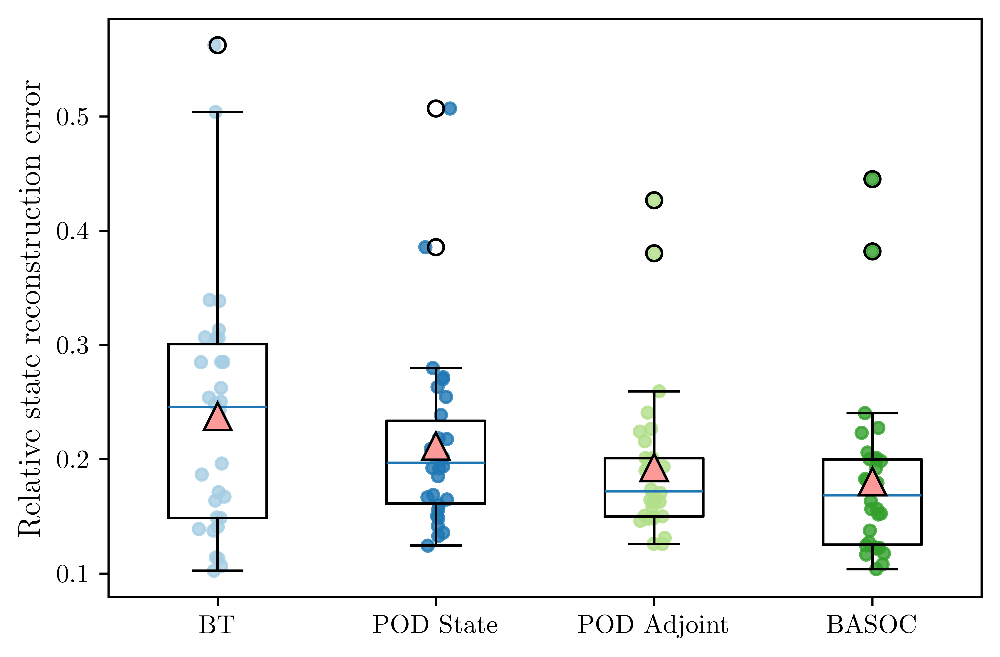

In [1204]:
#Same plot as above with jitters 
box_data = [
    all_state_error_summary["BT"],
    all_state_error_summary["POD State"],
    all_state_error_summary["POD Adjoint"],
    all_state_error_summary["Basoc"]
]
plt.figure(figsize=(6,4))
plt.boxplot(
    box_data,
    labels=["BT", "POD State", "POD Adjoint", "BASOC"], showmeans=True,
    meanprops=dict(marker="^", markerfacecolor="#fb9a99", markeredgecolor="black", markersize=10.5))

for i, data in enumerate(box_data, start=1):
    x = np.random.normal(i, 0.03, size=len(data))
    plt.scatter(x, data, alpha=0.8, s=20)

# plt.yscale("log")
# plt.yticks(
#     [0.12, 0.15, 0.20, 0.25],
#     ["0.12", "0.15", "0.20", "0.25"]
# )
plt.minorticks_off()
plt.ylabel("Relative state reconstruction error", fontsize=12)
# plt.title(f"Open loop ROM-EKF Relative State Reconstruction Error (r={r})")
plt.show()

In [8983]:
def learned_controller_KF(z,control_model):
    z = z.reshape(1, -1)  
    u = control_model.predict(z)
    u = np.asarray(u).reshape(1, -1)    # Forces (1,1) regardless of model
    return u[0]                         # output shape (1,) for Polynomial control law or gaussian process 

In [8984]:
x0_romfeedback = Initial_condition_test[0]
z0_romfeedback = Psi_basis.T @ x0_romfeedback
u0 = learned_controller_KF(z0_romfeedback,control_model)
print(u0)
print(x0_romfeedback)

[-2.07475573]
[0.98000865 0.84975602 0.99993365]


In [8985]:
# History alignment - this code is correct and output based closed loop feedback for the different methods has been updated:
# x_history : x_0, ..., x_N
# y_history : y_0, ..., y_N
# u_history : u_0, ..., u_{N-1}
# z_history : ẑ_1, ..., ẑ_N (posterior EKF estimates)


# ROM based closed loop feddback control with surrogate control law 
ekf = ExtendedKalmanFilter(z0_romfeedback, P0, Q_process_noise, R_measurement_noise, dt, A_ROM, B_ROM , C_ROM, H_ROM, N_ROM)

x = x0_romfeedback
u = u0                          # Initial control (e.g. shape (2,))

x_history = [x]
y_history = [C_FOM @ x]
u_history = []
z_history = []
P_history = []
z_true_history = []

Nt = 1000

# Main simulation Loop
for k in range(Nt):

    # Store u_k applied over [t_k, t_{k+1}]
    u_history.append(u)
    
    #FOM propagation
    sol = solve_ivp(lambda t, x: FOM(x, u), [0, dt], x, method="RK45")
    x = sol.y[:, -1]

    y = C_FOM @ x  # Measurement from FOM

    x_history.append(x)
    y_history.append(y)
    
    # EKF prediction (ROM)
    ekf.propagateDynamics(u)    # Produces z_{k+1}^- , P_{k+1}^-

    # EKF update (measurement)
    ekf.computeAposterioriEstimate(y)   # Produces z_{k+1}^+ , P_{k+1}^+

    # Store covariance
    P_current = ekf.estimationErrorCovarianceMatricesAposterior[-1] 
    P_history.append(P_current)

    # Controller (output feedback)
    z_hat = ekf.estimates_aposteriori[-1]   # ẑ_k^+
    z_true = Psi_basis.T @ x # This is added to be compared with the reduced state .
    z_true_history.append(z_true)
    z_history.append(z_hat)
           
    u = learned_controller_KF(z_hat,control_model)  # u_k

In [8986]:
def compute_cost_romfeedback(Y, U, Q, R, dt):
    
    Y = np.asarray(Y)
    U = np.asarray(U)

    stage_y = np.einsum("ti,ij,tj->t", Y, Q, Y)
    stage_u = np.einsum("ti,ij,tj->t", U, R, U)

    J_y = np.trapezoid(stage_y, dx=dt)
    J_u = dt * np.sum(stage_u)

    return J_y + J_u
J_romfeedback = compute_cost_romfeedback(y_history, u_history, Q, R, dt)
print(f"{J_romfeedback} for {basis_name} dim={r}")

105.76866459406426 for Basoc dim=2


In [8987]:
print(J_all_test[0])

105.5538830836548


(1001, 1)
(1001, 1)


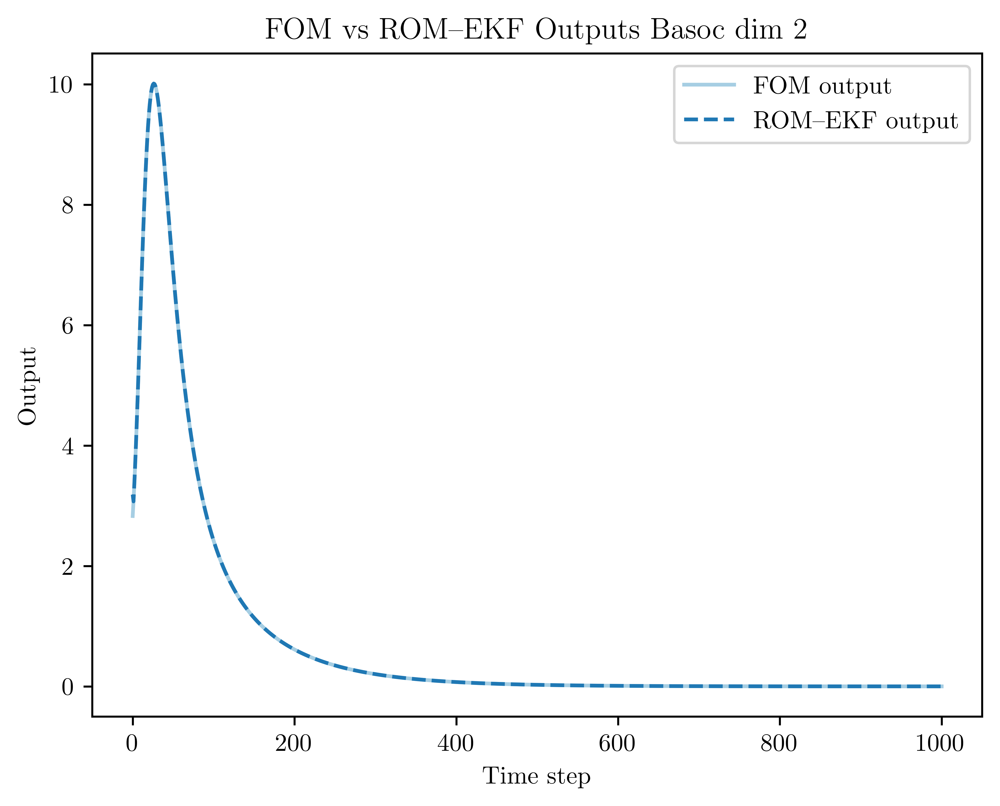

In [8988]:
y_rom = [C_ROM @ z for z in ekf.estimates_aposteriori]

y_fom = np.array(y_history)
y_rom = np.array(y_rom)

print(y_fom.shape)
print(y_rom.shape)

plt.figure()

plt.plot(y_fom[:,0], label="FOM output")
plt.plot(y_rom[:,0], '--', label="ROM–EKF output")

plt.legend(loc="upper right")
plt.xlabel("Time step")
plt.ylabel("Output")

plt.title(f"FOM vs ROM–EKF Outputs {basis_name} dim {r}")

plt.show()

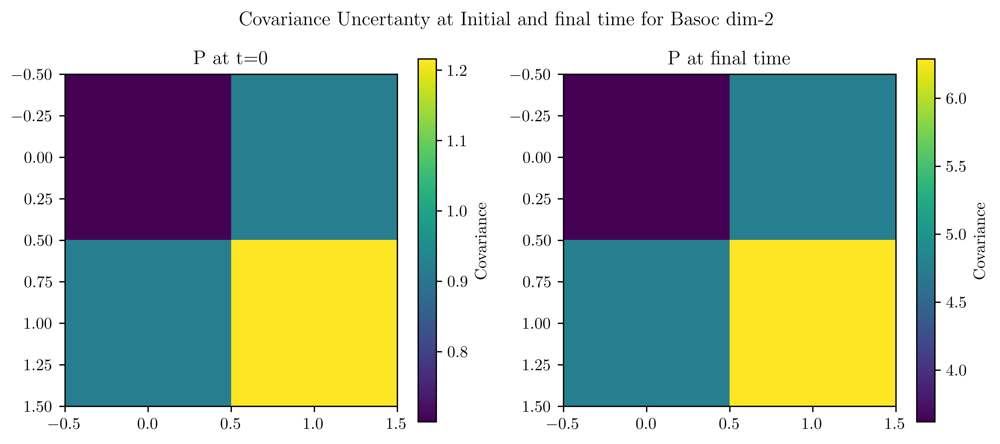

In [8989]:
fig, axes = plt.subplots(1,2, figsize=(10,4))

im1 = axes[0].imshow(P_history[0], cmap='viridis')
axes[0].set_title("P at t=0")

im2 = axes[1].imshow(P_history[-1], cmap='viridis')
axes[1].set_title("P at final time")

fig.colorbar(im1, ax=axes[0], label="Covariance")
fig.colorbar(im2, ax=axes[1], label="Covariance")

plt.suptitle(f"Covariance Uncertanty at Initial and final time for {basis_name} dim-{r}")

plt.show()

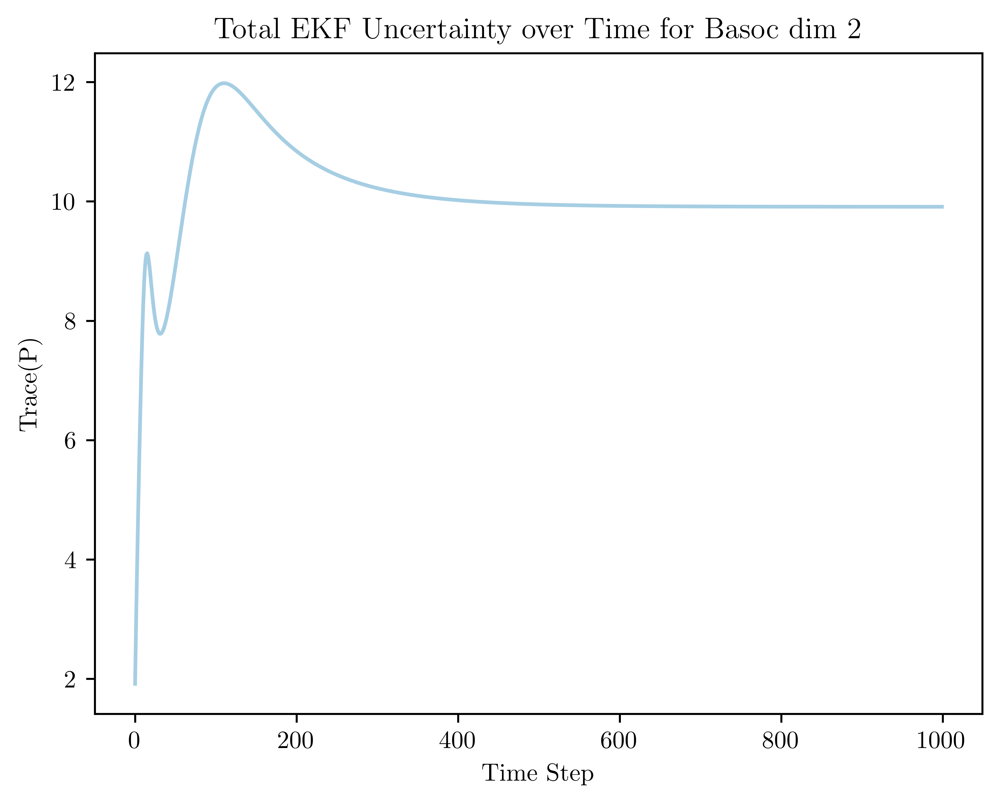

In [8990]:
P_diag = np.array([np.diag(P) for P in P_history])
traceP = np.sum(P_diag, axis=1)
plt.plot(traceP)
plt.xlabel("Time Step")
plt.ylabel("Trace(P)")
plt.title(f"Total EKF Uncertainty over Time for {basis_name} dim {r}")
plt.grid(False)

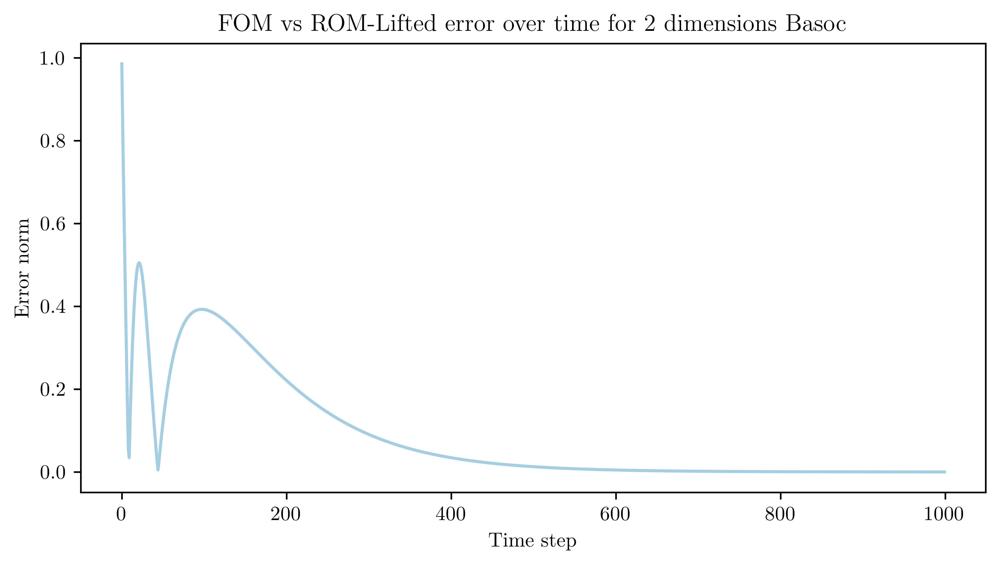

In [8991]:
x_rom_lifted = z_history @ Phi_basis.T
error_x_xrom = np.linalg.norm(x_history[1:] - x_rom_lifted, axis=1)
plt.figure(figsize=(8,4), dpi=600)
plt.plot(error_x_xrom)
plt.xlabel("Time step")
plt.ylabel("Error norm")
plt.title(f"FOM vs ROM-Lifted error over time for {r} dimensions {basis_name} ")
plt.show()

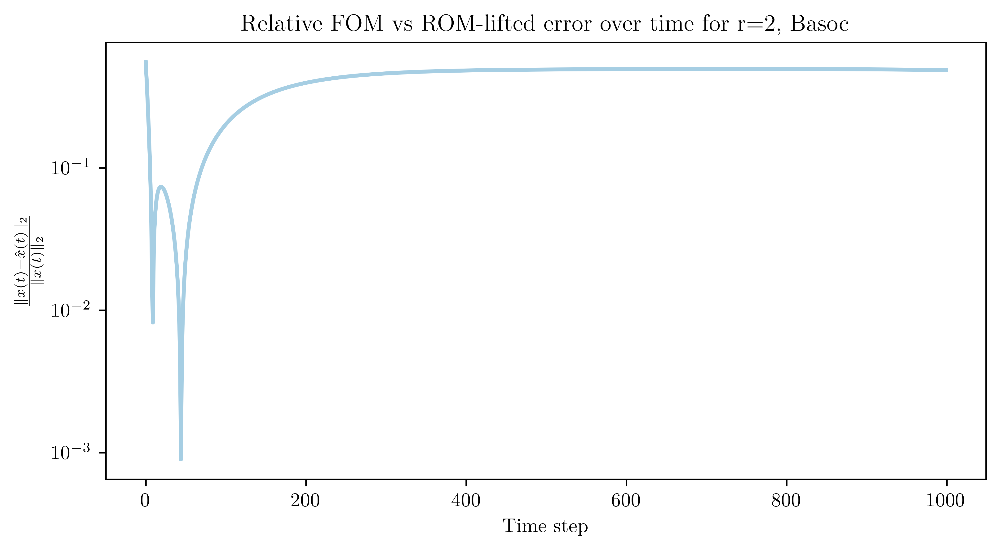

In [8992]:
x_rom_lifted = z_history @ Phi_basis.T   # shape: (Nt, n)

error_abs = np.linalg.norm(x_history[1:] - x_rom_lifted, axis=1)

x_norm = np.linalg.norm(x_history[1:], axis=1)

error_rel = error_abs / (x_norm)   

plt.figure(figsize=(8,4), dpi=600)
plt.plot(error_rel, linewidth=2)
plt.xlabel("Time step")
plt.ylabel(r"$\frac{\|x(t)-\hat{x}(t)\|_2}{\|x(t)\|_2}$")
plt.title(f"Relative FOM vs ROM-lifted error over time for r={r}, {basis_name}")
plt.yscale("log")
plt.minorticks_off()  
plt.show()

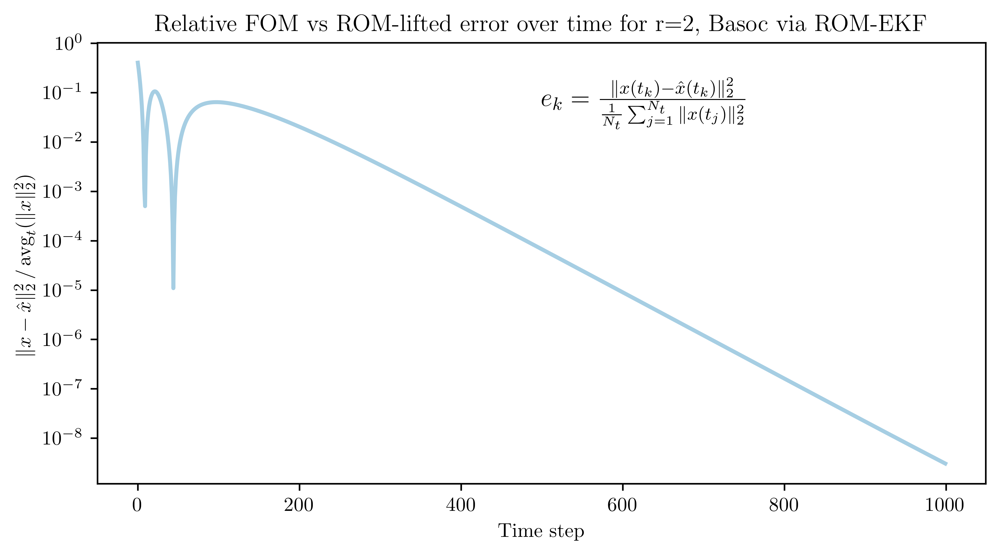

In [8993]:
x_rom_lifted = z_history @ Phi_basis.T   # shape: (Nt, n)

# numerator: ||x(t_k) - x_hat(t_k)||_2^2 at each time step
error_num = np.linalg.norm(x_history[1:] - x_rom_lifted, axis=1)**2

# denominator: avg_t( ||x(t)||_2^2 )
denom = np.mean(np.linalg.norm(x_history[1:], axis=1)**2)

# relative error along trajectory
error_rel_traj = error_num / denom

plt.figure(figsize=(8,4), dpi=600)

plt.plot(error_rel_traj, linewidth=2)

plt.xlabel("Time step")
plt.ylabel(r"$\|x-\hat{x}\|_2^2 \,/\, \mathrm{avg}_t(\|x\|_2^2)$")
plt.title(f"Relative FOM vs ROM-lifted error over time for r={r}, {basis_name} via ROM-EKF")

# Add formula inside the plot
formula = (
    r"$e_k = "
    r"\frac{\|x(t_k)-\hat{x}(t_k)\|_2^2}"
    r"{\frac{1}{N_t}\sum_{j=1}^{N_t}\|x(t_j)\|_2^2}$"
)

plt.text(
    0.5, 0.92, formula,
    transform=plt.gca().transAxes,
    fontsize=13,
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
)

plt.yscale("log")
plt.minorticks_off()
plt.show()

In [8994]:
n_test_IC = 30

r_values = [2]

results_rombasedfeedback = {name: {} for name in names}

for basis_name in names:

    for r in r_values:

        print(f"\nRunning {basis_name}, r = {r}")

        if basis_name == "BT":
            Phi_basis_romfeedback, Psi_basis_romfeedback = compute_bt_basis(Rc, Ro, U_BT, S_BT, Vt_BT, r)

        elif basis_name == "POD State":
            Phi_basis_romfeedback = Pod_State_basis(Vtx, r)
            Psi_basis_romfeedback = Phi_basis_romfeedback

        elif basis_name == "POD Adjoint":
            Phi_basis_romfeedback = Pod_Adjoint_basis(Vtg, r)
            Psi_basis_romfeedback = Phi_basis_romfeedback

        elif basis_name == "Basoc":
            Phi_basis_romfeedback, Psi_basis_romfeedback = compute_basoc_basis(Rx, Rg, U_basoc, S_basoc, Vt_basoc, r)

        Y, V, U, X, x0_all = project_dataset(dataset, Psi_basis_romfeedback, C_FOM, Q, R, w)

        gpr_model, r2_train_gpr, r2_test_gpr = train_control_model_gpr(Y, U, k=2400, K_test=200)
        print(f"{basis_name}, r={r} | R2 train = {r2_train_gpr:.6f}, R2 test = {r2_test_gpr:.6f}")

        control_model = gpr_model

        A_ROM_r, B_ROM_r, C_ROM_r, H_ROM_r, N_ROM_r = get_ROM_tensors(Phi_basis_romfeedback, Psi_basis_romfeedback, A_FOM, B_FOM, C_FOM, H_FOM, N_FOM)

        dt = 0.01
        Nt = 1000

        Q_process_noise = np.eye(r)
        R_measurement_noise = 1e-3 * np.eye(1)

        J_rom_all = []
        err_all = []
        err_abs_rel_all = []
        state_reconstruction_error_ROM_EKF_feedback_all = []

        for traj_id in range(n_test_IC):

            x0_romfeedback = x0_test[traj_id]

            J_true = J_all_test[traj_id]

            z0_romfeedback = Psi_basis_romfeedback.T @ x0_romfeedback

            u0 = learned_controller_KF(z0_romfeedback, control_model)

            P0 = np.eye(r)

            ekf = ExtendedKalmanFilter(z0_romfeedback, P0, Q_process_noise, R_measurement_noise, dt, A_ROM_r, B_ROM_r, C_ROM_r, H_ROM_r, N_ROM_r)

            x = x0_romfeedback.copy()
            u = u0.copy()

            # Node values: x0,...,xN and y0,...,yN
            x_history = [x]
            y_history = [C_FOM @ x]

            u_history = []
            z_history = []

            for k in range(Nt):
                u_history.append(u)

                sol = solve_ivp(lambda t, x: FOM(x, u), [0, dt], x, method="RK45", rtol=rtol, atol=atol)

                x = sol.y[:, -1]

                y = C_FOM @ x

                x_history.append(x)
                y_history.append(y)
                

                ekf.propagateDynamics(u)

                ekf.computeAposterioriEstimate(y)

                z_hat = ekf.estimates_aposteriori[-1]
                z_history.append(z_hat)

                u = learned_controller_KF(z_hat, control_model)

            x_history = np.array(x_history)
            z_history = np.array(z_history)

            x_rom_lifted = z_history @ Phi_basis_romfeedback.T

            state_reconstruction_error_ROM_EKF_feedback = (np.linalg.norm(x_history[1:] - x_rom_lifted, "fro") / np.linalg.norm(x_history[1:], "fro"))

            J_rom = compute_cost_romfeedback(y_history, u_history, Q, R, dt)

            error = J_rom - J_true

            # error_abs_relative = abs(error) / J_true

            error_abs_relative = error / J_true

            J_rom_all.append(J_rom)
            err_all.append(error)
            err_abs_rel_all.append(error_abs_relative)
            state_reconstruction_error_ROM_EKF_feedback_all.append(state_reconstruction_error_ROM_EKF_feedback)

            print(
                f"{basis_name}, r={r}, IC={traj_id+1} "
                f"→ J_true={J_true:.4f}, "
                f"J_rom={J_rom:.4f}, "
                f"rel_error={error_abs_relative:.6f}, "
                f"state_error={state_reconstruction_error_ROM_EKF_feedback:.6f}"
            )

        results_rombasedfeedback[basis_name][f"r={r}"] = {
            "J": J_rom_all,
            "err": err_all,
            "err_abs_rel": err_abs_rel_all,
            "state_reconstruction_error_ROM_EKF_feedback": state_reconstruction_error_ROM_EKF_feedback_all,
            "r2_test": r2_test_gpr,
        }

        print(
            f"\n{basis_name}, r={r} complete | "
            f"median rel error = {np.median(err_abs_rel_all):.6f}, "
            f"mean rel error = {np.mean(err_abs_rel_all):.6f}, "
            f"median state error = {np.median(state_reconstruction_error_ROM_EKF_feedback_all):.6f}" ,
            f"mean state error = {np.mean(state_reconstruction_error_ROM_EKF_feedback_all):.6f}"
        )


Running BT, r = 2
BT, r=2 | R2 train = 1.000000, R2 test = 0.676861
BT, r=2, IC=1 → J_true=105.5539, J_rom=481.9843, rel_error=3.566239, state_error=0.138398
BT, r=2, IC=2 → J_true=45.3735, J_rom=71.0616, rel_error=0.566146, state_error=0.200347
BT, r=2, IC=3 → J_true=20.0779, J_rom=22.5928, rel_error=0.125257, state_error=0.114864
BT, r=2, IC=4 → J_true=23.5952, J_rom=26.9378, rel_error=0.141664, state_error=0.159511
BT, r=2, IC=5 → J_true=46.7177, J_rom=77.2002, rel_error=0.652485, state_error=0.206616
BT, r=2, IC=6 → J_true=36.7952, J_rom=52.9007, rel_error=0.437706, state_error=0.297466
BT, r=2, IC=7 → J_true=74.4077, J_rom=203.4444, rel_error=1.734185, state_error=0.230308
BT, r=2, IC=8 → J_true=46.8021, J_rom=74.7741, rel_error=0.597665, state_error=0.252177
BT, r=2, IC=9 → J_true=101.3857, J_rom=468.8646, rel_error=3.624565, state_error=0.151280
BT, r=2, IC=10 → J_true=22.4892, J_rom=25.5256, rel_error=0.135014, state_error=0.177610
BT, r=2, IC=11 → J_true=71.2299, J_rom=201.17

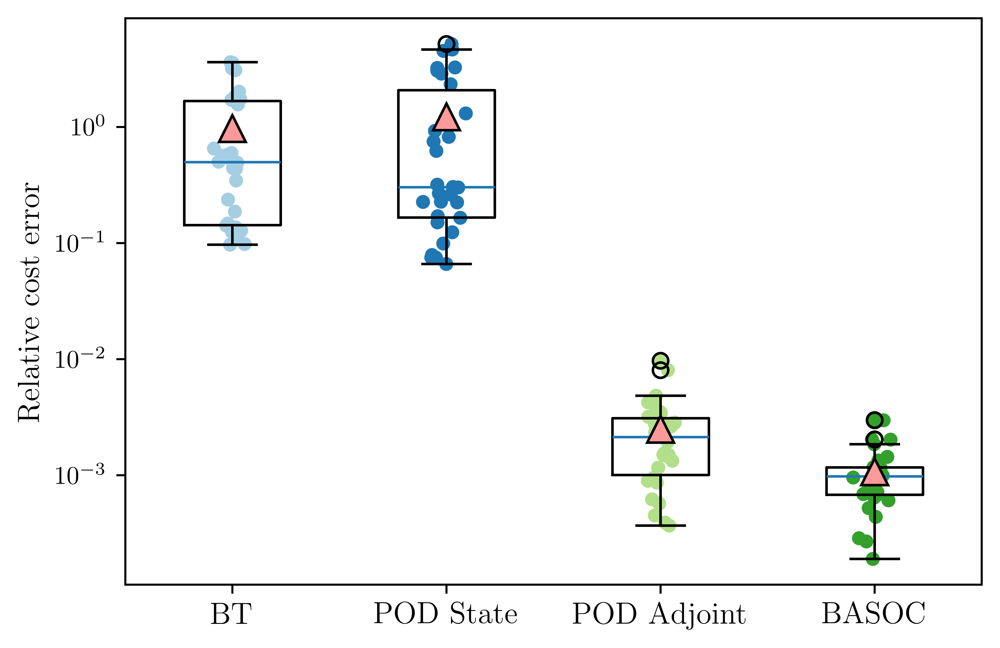

In [8995]:
box_data = [
    results_rombasedfeedback["BT"]["r=2"]["err_abs_rel"],
    results_rombasedfeedback["POD State"]["r=2"]["err_abs_rel"],
    results_rombasedfeedback["POD Adjoint"]["r=2"]["err_abs_rel"],
    results_rombasedfeedback["Basoc"]["r=2"]["err_abs_rel"]
]
plt.figure(figsize=(6,4))
plt.boxplot(
    box_data,
    labels=["BT", "POD State", "POD Adjoint", "BASOC"],
    showmeans=True,
    meanprops=dict(
        marker="^",
        markerfacecolor="#fb9a99",
        markeredgecolor= "black",
        markersize=10.5
    )
)
# Strip plot overlay
for i, data in enumerate(box_data, start=1):    
    # small horizontal jitter
    x = np.random.normal(i, 0.04, size=len(data))    
    plt.scatter(x,data,alpha=1,s=20)

plt.yscale("log")
plt.ylabel("Relative Cost Error (Log Scale )", fontsize=12)
plt.ylabel("Relative cost error", fontsize=12)
# plt.ylabel(
#     r"$\mathbf{Relative\ Cost\ Error\ (Log\ Scale)}$",
#     fontsize=13
# )
# plt.title("Output-based Closed-loop Feedback Control via EKF-ROM Relative Cost Error (r=2)")
# plt.title(
#     r'$\mathbf{Output\ Based\ Closed\ Loop\ Feedback\ Control\ Relative\ Cost\ Error\ (r=2)}$',
#     fontsize=12
# )
plt.minorticks_off()
plt.xticks(fontsize=12)
plt.savefig("output_based_closed_loop_control_toy_model_extrapolate.pdf", bbox_inches="tight")
plt.show()

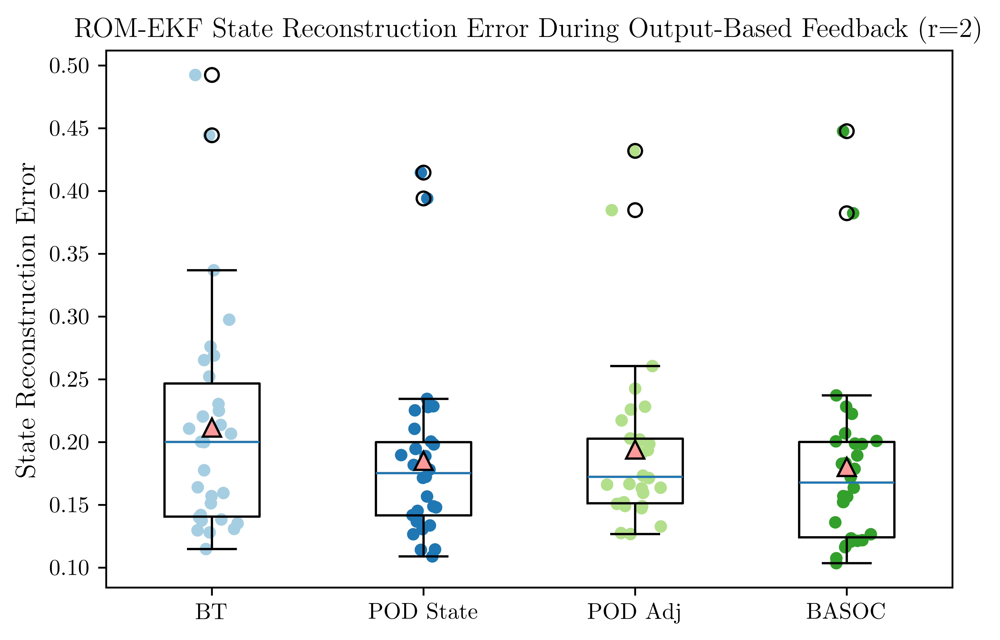

In [8996]:
box_data = [
    results_rombasedfeedback["BT"]["r=2"]["state_reconstruction_error_ROM_EKF_feedback"],
    results_rombasedfeedback["POD State"]["r=2"]["state_reconstruction_error_ROM_EKF_feedback"],
    results_rombasedfeedback["POD Adjoint"]["r=2"]["state_reconstruction_error_ROM_EKF_feedback"],
    results_rombasedfeedback["Basoc"]["r=2"]["state_reconstruction_error_ROM_EKF_feedback"]
]
labels = ["BT", "POD State", "POD Adj", "BASOC"]
plt.figure(figsize=(6,4))
plt.boxplot(
    box_data,
    labels=labels,
    showmeans=True,
    meanprops=dict(marker="^", markerfacecolor= "#fb9a99", markeredgecolor="black", markersize=8))

for i, data in enumerate(box_data, start=1):
    x = np.random.normal(i, 0.05, size=len(data))
    plt.scatter(x, data, alpha=1, s=20)
# plt.yscale("log")
plt.ylabel("State Reconstruction Error", fontsize = 12)
plt.title("ROM-EKF State Reconstruction Error During Output-Based Feedback (r=2)")
# plt.minorticks_off()
plt.tight_layout()
plt.show()

In [1942]:
# # Number of trajectories 
# n_samples_qs = len(nodes_qs)

# # Optimization for Multiple Random Samples
# dataset_toy_qs = []

# for k in range(n_samples_qs):

#     # Clear the screen
#     clear_output(wait=True) 
    
#     if k>0 :
#         prev_cost = dataset_toy_qs[k-1]['cost']
#         prev_node = dataset_toy_qs[k-1]['node_qs']
#         print(f"Previous Sample {k}: J* = {prev_cost:.6f}, node_qs = {prev_node:.3f}")

#     else:
#         print("Starting quadrature first sample...")

#     print(f"Quadrature Sample {k+1}/{n_samples_qs} running...")
    
#     # Reset iteration tracker
#     iteration_data = []

#     # Initial condition from quadrature node
#     node_q = nodes_qs[k]
#     x0 = np.ones(n_states) * node_q

#     print(f"Initial condition scaling node_qs = {node_q:.3f} for iteration {k}")
    
#     # Initial control guess
#     U0 = 0 * np.ones((N, m))   # Initial guess (non-zero)
#     u0 = pack_u(U0)

#     # Run optimization for this initial condition 
#     res = minimize(
#         fun_only, u0,
#         args=(x0,),
#         jac=jac_only,
#         method='BFGS',
#         tol=1e-6,
#         options=dict(maxiter=800, gtol=1e-8, disp=False),
#         callback=lambda u: callback(u, x0)
#     )

#     # Compute final trajectories and adjoints
#     u_star = unpack_u(res.x)
#     X_star_fun = forward_trajectory(res.x,x0)
#     X_star = X_star_fun(t).T                  # Evaluate at nodes - X_fun returns n by N and transpose to get N by n 
#     J_star = total_cost(res.x, X_star)
#     Grad_star, P_star = gradient(res.x, X_star_fun, return_adj=True)

#     Y_star = (C_FOM @ X_star.T).T

#     # Stage cost (vectorized)
#     L = np.einsum('ij,ij->i', Y_star @ Q, Y_star) + \
#         np.einsum('ij,ij->i', u_star @ R, u_star)

#     # Value function (vectorized)
#     V = np.cumsum((w * L)[::-1])[::-1]

#     # Store structured dataset entry 
#     dataset_toy_qs.append({
#         'node_qs': node_q,
#         'weight': weights_qs[k],
#         'x0': x0,
#         'state_history': X_star,
#         'control_history': u_star,
#         'gradient_history': P_star,
#         'cost': J_star,
#         'Value_function': V,
#     })
#     print(f"\nSample {k+1}/{n_samples_qs} complete | node_qs = {node_q:.3f}, J* = {J_star:.6f}")
        
# print(f"Optimization from {n_samples_qs} initial samples done and completed")

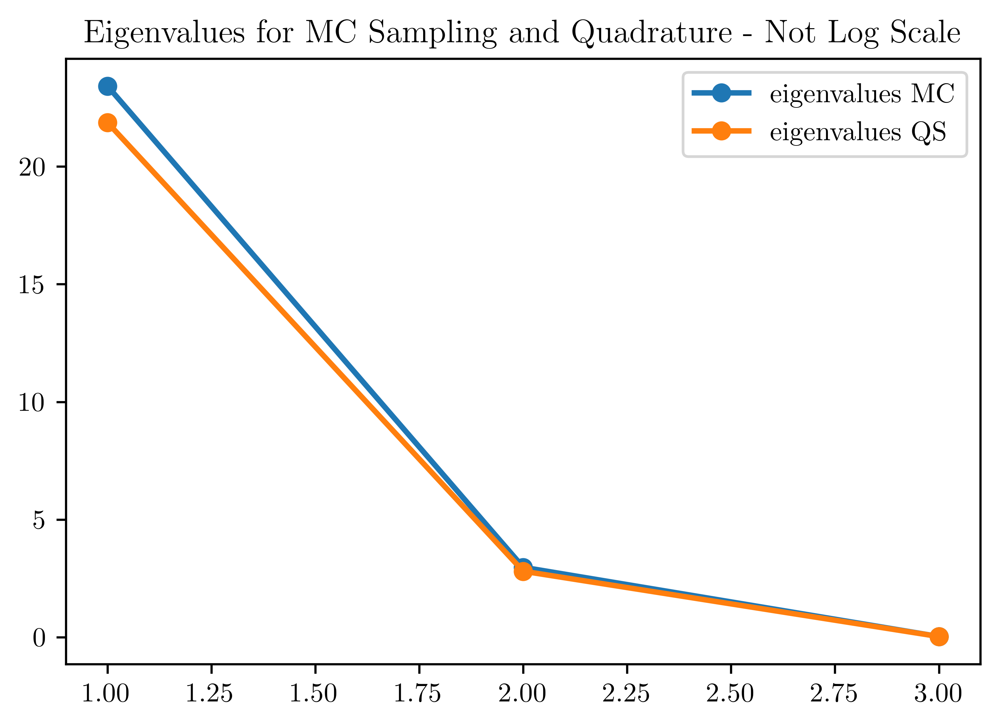

In [391]:
plt.figure(figsize=(6,4), dpi=600)
plt.plot(np.arange(1, len(S_basoc)+1 ),S_basoc , 'o-', label="eigenvalues MC", linewidth=2)
plt.plot(np.arange(1, len(S_qs)+ 1 ), S_qs , 'o-', label='eigenvalues QS', linewidth=2)
plt.legend()
#plt.yscale('log')
plt.title(f"Eigenvalues for MC Sampling and Quadrature - Not Log Scale ")
plt.grid(False)
plt.show()

In [101]:
# PROJECTION OPERATOR ERROR NORM BETWEEN MC and QS 
errors_op = []
errors_fro = []
errors_rel = []

k = len(dataset)

for i in range(k):

    subset = dataset[:i+1]
    m = len(subset)

    G_full = np.vstack([entry['gradient_history'] for entry in subset])
    X_full = np.vstack([entry['state_history'] for entry in subset])

    w_full = np.tile(w.reshape(-1,1), (m, 1))

    G_full *= np.sqrt(w_full)
    X_full *= np.sqrt(w_full)

    G_full /= np.sqrt(m)
    X_full /= np.sqrt(m)

    G_full *= np.sqrt(0.5)
    X_full *= np.sqrt(0.5)

    Ug, Sg, Vtg = np.linalg.svd(G_full, full_matrices=False)
    Vg = Vtg.T

    Ux, Sx, Vtx = np.linalg.svd(X_full, full_matrices=False)
    Vx = Vtx.T

    Rx = np.diag(Sx) @ Vx.T
    Rg = np.diag(Sg) @ Vg.T

    H = Rg @ Rx.T
    U, S, Vt = np.linalg.svd(H)

    r = 2
    U_r = U[:, :r]
    S_r = S[:r]
    V_r = Vt.T[:, :r]

    Phi_bal = Rx.T @ V_r @ np.diag(1/np.sqrt(S_r))
    Psi_bal = Rg.T @ U_r @ np.diag(1/np.sqrt(S_r))

    PMC = Phi_bal @ Psi_bal.T

    diff = PQS - PMC

    # Operator norm
    err_op = np.linalg.norm(diff, 2)

    # Frobenius norm
    err_fro = np.linalg.norm(diff, 'fro')

    # Relative error (frobenius norm)
    err_rel = err_fro / np.linalg.norm(PQS, 'fro')

    errors_op.append(err_op)
    errors_fro.append(err_fro)
    errors_rel.append(err_rel)

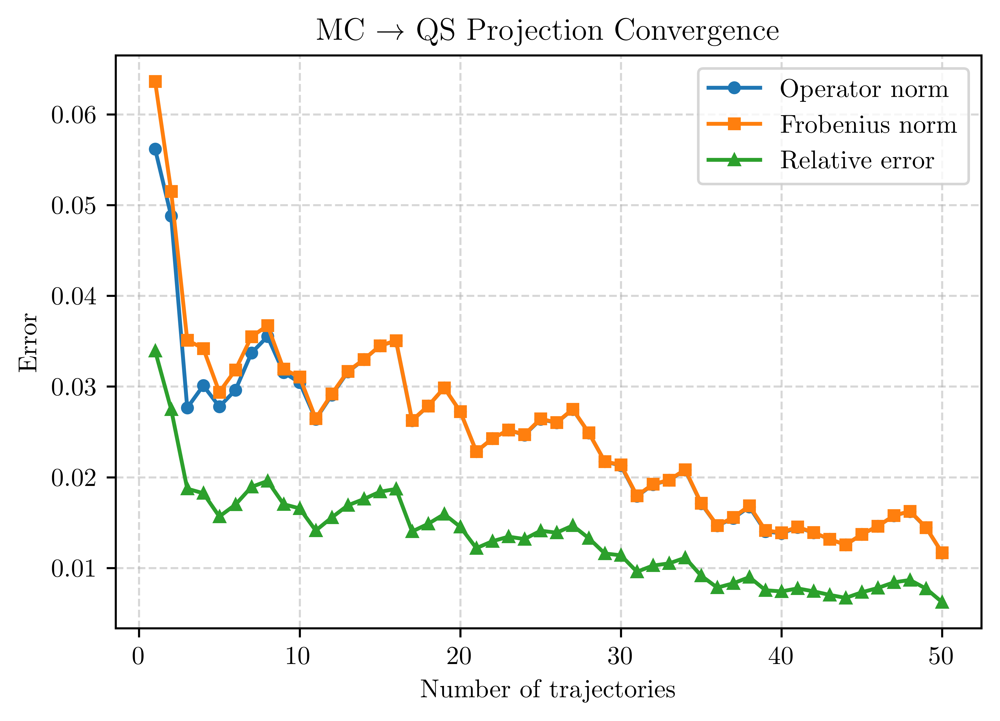

In [102]:
Ns = np.arange(1, len(errors_op)+1)
plt.figure(figsize=(6,4), dpi=800)
plt.plot(Ns, errors_op, 'o-', label='Operator norm', markersize=4)
plt.plot(Ns, errors_fro, 's-', label='Frobenius norm',markersize=4)
plt.plot(Ns, errors_rel, '^-', label='Relative error',markersize=4)
plt.xlabel("Number of trajectories")
plt.ylabel("Error")
# plt.yscale('log')
# plt.xscale('log')
plt.title("MC → QS Projection Convergence")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [99]:
# #toy model with a limit cycle 
# # parameters
# omega = 1.0
# alpha = 1
# beta = 1
# gamma = 10.0

# # system
# def FOM_limit_cycle(t, x):
#     x1, x2, x3 = x
#     u = 0.0

#     r2 = x1**2 + x2**2

#     dx1 = omega*x2 + beta*x1*x3 - alpha*r2*x1 + u
#     dx2 = -omega*x1 + beta*x2*x3 - alpha*r2*x2 + u
#     dx3 = -gamma*x3 + u

#     return [dx1, dx2, dx3]

# # output function
# def output(x):
#     return x[0]   # y = x1

# # simulate
# t_span = (0, 50)
# t_eval = np.linspace(0, 50, 5000)
# x0 = [1.5, 0.0, 1.0]

# sol = solve_ivp(FOM_limit_cycle, t_span, x0, t_eval=t_eval)

# x = sol.y.T
# t = sol.t
# y = x[:,0]

# # plot states
# plt.figure()
# plt.plot(t, x[:,0], label='x1')
# plt.plot(t, x[:,1], label='x2')
# plt.plot(t, x[:,2], label='x3')
# plt.title('States')
# plt.legend()
# plt.show()

# # plot output
# plt.figure()
# plt.plot(t, y)
# plt.title('Output y = x1')
# plt.xlabel('t')
# plt.ylabel('y')
# plt.show()

# # phase plot
# plt.figure()
# plt.plot(x[:,0], x[:,1])
# plt.title('Limit Cycle (x1 vs x2)')
# plt.axis('equal')
# plt.show()